# PyPSA-Sudan: least-cost electrification under recovery conditions

**Start with [section 11: national supply coupling](#national-coupling)** for eight neighbouring clusters linked to the 19-node Sudan dispatch model, with shared routes, local recovery conditions and checked cost bounds. Supporting work: [Four-cluster demonstration](#recovery-planning) · [Hourly pilot](#optimized-pilot) · [Uncertainty and break-even](#uncertainty-study) · [18-state sample](#spatial-proxy-study).

This notebook assembles equipment, installed networks, connections, delivery, installation, project development, tax allowances, annual operation, replacements, disposal and finance. It is the cost layer for the post-war electrification study, separate from the existing 2022 dispatch model.

**Sections 1–6 explain provisional budgets for fixed example designs. Section 7 optimizes three real atlas clusters. Section 8 tests uncertainty and break-even thresholds. Section 9 expands to one selected cluster in each of 18 states, using atlas-demand proxies and recovery-service scenarios.** We proceed with available public evidence; measured settlement demand is not required to run these explicitly conditional scenarios. Monetary inputs remain editable analyst assumptions; no observed Sudan price is silently converted to USD, and no damage is inferred from a conflict-risk category.

| Available and checked | Still needed |
|---|---|
| National dispatch coupling for eight neighbouring clusters, plus the earlier local demonstrations and evidence | Multiple geographic interfaces, national asset investment and sequencing; better route and procurement evidence |
| Fixed budgets use 100 homes; the pilot uses source cluster sizes and checks identical hourly service across options | Measured diversity/peaks, critical and productive loads, field reliability and multiple weather years |
| Transparent upfront and 20-year costs; point maps across proxy-demand scenarios | A validated construction recommendation or integrated national budget |

The fixed examples in sections 1–6 are **not optimized**. Section 7 separately matches assumed demand across options and checks hourly adequacy. Its conditional rankings depend on provisional routes, equipment prices, service profiles and grid availability; they are not field-validated recommendations.

**Current results: section 11 first.** Supporting reading: 1 Fixed budgets → 2 Cost breakdown → 3 Cash flows and finance → 4 Fixed-design sensitivities → 5 Evidence and assumptions → 6 Accounting checks → 7 Hourly pilot → 8 Uncertainty and break-even → 9 Spatial proxy-demand scenarios across 18 states → 10 Four-cluster joint recovery demonstration. Section 11 adds national dispatch coupling for eight clusters; a country-wide access allocation and field-verified rehabilitation plan remain outside its scope.

[Project map](https://github.com/Elgenied/pypsa-sudan) · [Editable inputs and accounting rules](../../data/system_costs/README.md) · [Study plan](https://github.com/Elgenied/pypsa-sudan/blob/main/docs/STUDY_PLAN.md)

In [1]:
from pathlib import Path
import sys, json, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from this notebook directory or the repository root, including the Desktop copy.
here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p/'data/system_costs/components.csv').exists())
MODEL = ROOT/'research/system_costs'
sys.path.insert(0, str(MODEL))
from cost_model import evaluate, export_results, read_csv, write_csv, RESULTS, DATA, sensitivity_rows
plt.rcParams.update({'figure.dpi': 125, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
pd.set_option('display.max_colwidth', 100)
outputs = export_results()
summary = pd.DataFrame([o['summary'] for o in outputs])
central = summary.query("scenario == 'central'").set_index('case')
labels = {'standalone': 'Standalone\n100 homes', 'mini_grid': 'Mini-grid\n100 homes',
          'grid_extension': 'Grid extension\n5 km new MV', 'grid_repair_extension': 'Grid + repair\nsynthetic case'}
colors = {'standalone':'#DFAD35','mini_grid':'#269C94','grid_extension':'#446A98','grid_repair_extension':'#8C6AA6'}
def money_table(frame):
    return frame.style.format(precision=0, thousands=',').set_properties(**{'text-align':'right'})

## 1. Results: provisional budgets, not supplier quotations

The accounting horizon is **20 years**, with **10% real discounting** in the central case. Costs are held constant in real terms. “2025 USD” is an **assigned scenario price basis**, not a verified inflation conversion of the older benchmarks. The original evidence keeps its own currency and date.

These four designs all target 1 kWh/home/day, but were selected to demonstrate accounting, not to minimize cost. The grid example assumes a usable upstream source with spare capacity. The repair example adds 2 km of existing MV repair at 50% of a new line's rate and a separate upstream repair allowance. Neither describes surveyed damage.

Annual operating cost excludes replacement purchases, which appear in the cash flows and lifecycle total. All figures below include the assumed nonrecoverable import-tax allowance. An alternative total excluding that allowance is exported separately; it is not a comprehensive social cost-benefit calculation.

,Upfront USD,Upfront USD/home,Annual operations USD,20-year discounted cost USD
Standalone / 100 homes,"309,275","3,093","3,155","467,856"
Mini-grid / 100 homes,"252,440","2,524","7,068","399,890"
Grid extension / 5 km new MV,"186,516","1,865","11,898","293,462"
Grid + repair / synthetic case,"234,036","2,340","12,698","347,911"


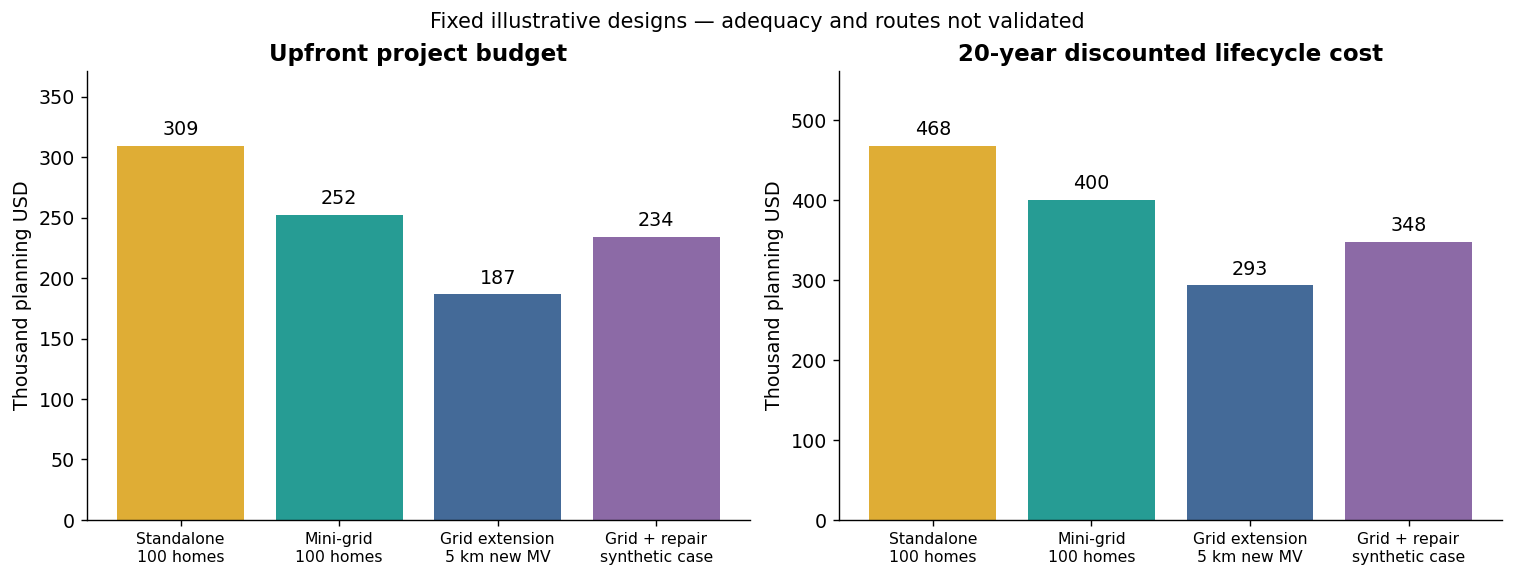

In [2]:
view = central[['initial_budget_USD','initial_USD_per_connection','annual_operating_USD','lifecycle_NPC_USD']].copy()
view.columns=['Upfront USD','Upfront USD/home','Annual operations USD','20-year discounted cost USD']
view.index=[labels[x].replace('\n',' / ') for x in view.index]
display(money_table(view))

fig, axes = plt.subplots(1,2,figsize=(12,4.5), layout='constrained')
for ax, field, title in zip(axes, ['initial_budget_USD','lifecycle_NPC_USD'],
                           ['Upfront project budget','20-year discounted lifecycle cost']):
    vals=central[field]/1000
    bars=ax.bar([labels[x] for x in vals.index], vals, color=[colors[x] for x in vals.index])
    ax.bar_label(bars,fmt='%.0f',padding=4)
    ax.set_ylabel('Thousand planning USD'); ax.set_title(title); ax.set_ylim(0,vals.max()*1.2)
    ax.tick_params(axis='x', labelsize=9)
fig.suptitle('Fixed illustrative designs — adequacy and routes not validated',fontsize=12)
fig.savefig(RESULTS/'budget_overview.png',bbox_inches='tight'); plt.show()

### What is actually being purchased?

The standalone portfolio comprises 100 separate systems, each with 1 kWp PV, 3 kWh **nominal** battery capacity and a 1 kW hybrid inverter. The mini-grid has 50 kWp PV, 150 kWh nominal batteries, a 40 kW battery inverter, a 30 kW diesel generator and 2 km of LV distribution. Battery usable energy, temperature derating and cycling need specification; nominal kWh is not delivered kWh.

Both grid examples include 5 km of new MV, one installed 100 kVA MV/LV transformer, 2 km LV, service drops/meters and basic internal wiring. All four include safe home wiring. Household appliances and productive-use equipment are outside the supply boundary.

In [3]:
boq=pd.read_csv(DATA/'bill_of_quantities.csv')
components=pd.read_csv(DATA/'components.csv')
design_table=boq.merge(components[['component','quantity_unit']],on='component',validate='many_to_one')
display(design_table.pivot(index=['component','quantity_unit'],columns='case',values='quantity').fillna(0).style.format(precision=1))
display(Markdown('Zero in this design table means **not selected**, not a missing price. MV repair is an additional case-design input: 2 route km × 50% of the new-line rate.'))

,case,grid_extension,grid_repair_extension,mini_grid,standalone
component,quantity_unit,,,,
battery,kWh_nominal,0.0,0.0,150.0,300.0
battery_inverter,kW_AC,0.0,0.0,40.0,0.0
civil_site,site,0.0,0.0,1.0,0.0
diesel_genset,kW_electric,0.0,0.0,30.0,0.0
fuel_tank_ats,system,0.0,0.0,1.0,0.0
grid_protection,site,1.0,1.0,0.0,0.0
house_wiring,connection,100.0,100.0,100.0,100.0
land_right,site_20year,0.0,0.0,1.0,0.0
lv_line,route_km,2.0,2.0,2.0,0.0


Zero in this design table means **not selected**, not a missing price. MV repair is an additional case-design input: 2 route km × 50% of the new-line rate.

## 2. What the full mini-grid budget contains

Hardware and installed work are separated. Freight and installation percentages apply only to eligible hardware; an already installed LV line is not charged installation again. The PV inverter and battery inverter have separate roles. A standalone hybrid inverter already includes MPPT, so the model rejects adding another PV inverter to that design.

The source's shipment-cost percentages divide a shipment cost basket; they are **not** percentages to apply to equipment value. Similarly, a published “distribution plus meters per customer” benchmark is only a cross-check, not an extra charge on top of explicit lines and meters.

,Component,Quantity,Unit,Unit price USD,Subtotal USD,Life years
0,pv_module,50.0,kWp,300,"15,000",25
1,pv_inverter,50.0,kW_AC,150,"7,500",10
2,battery,150.0,kWh_nominal,350,"52,500",8
3,battery_inverter,40.0,kW_AC,420,"16,800",10
4,pv_bos,50.0,kWp,120,"6,000",25
5,diesel_genset,30.0,kW_electric,650,"19,500",10
6,fuel_tank_ats,1.0,system,"1,200","1,200",15
7,lv_line,2.0,route_km,"10,000","20,000",30
8,service_meter,100.0,connection,120,"12,000",10
9,house_wiring,100.0,connection,100,"10,000",20


,Initial budget USD
component_purchase,"168,000"
international_freight,"9,480"
inland_logistics,"11,850"
installation_labour,"17,775"
engineering_development,"16,568"
contingency,"22,367"
assumed_tax,"6,399"


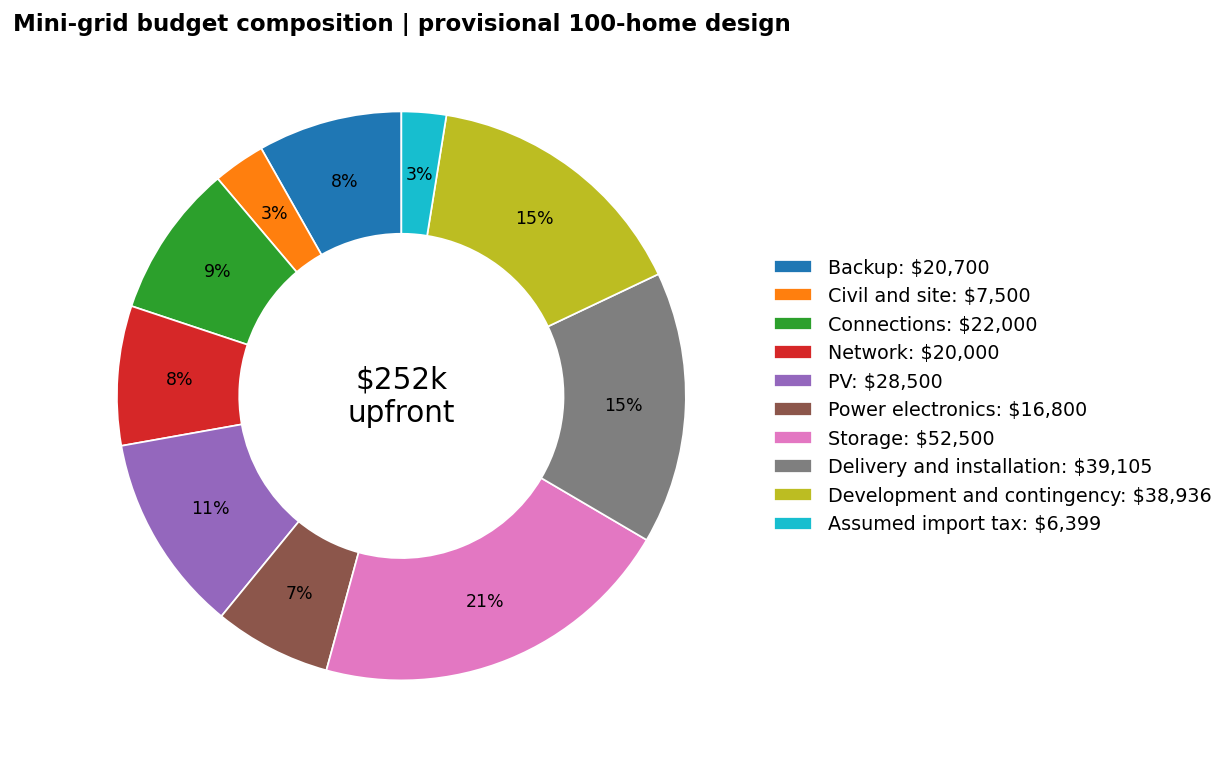

,Annual operating USD
technical_maintenance,"2,004"
insurance_allowance,840
administration,"1,200"
security_allowance,"1,000"
diesel_fuel,"1,904"
diesel_runtime_maintenance,119
grid_supply,0


In [4]:
mg=evaluate('mini_grid')
item_table=pd.DataFrame(mg['items'])[['component','quantity','quantity_unit','unit_cost','cost','life']]
item_table.columns=['Component','Quantity','Unit','Unit price USD','Subtotal USD','Life years']
display(item_table.style.format({'Quantity':'{:,.1f}','Unit price USD':'{:,.0f}','Subtotal USD':'{:,.0f}','Life years':'{:,.0f}'}))
display(money_table(pd.DataFrame.from_dict(mg['initial'],orient='index',columns=['Initial budget USD'])))

groups=pd.DataFrame(mg['items']).groupby('group')['cost'].sum()
groups['Delivery and installation']=sum(mg['initial'][x] for x in ['international_freight','inland_logistics','installation_labour'])
groups['Development and contingency']=mg['initial']['engineering_development']+mg['initial']['contingency']
groups['Assumed import tax']=mg['initial']['assumed_tax']
assert np.isclose(groups.sum(), mg['summary']['initial_budget_USD'])
fig,ax=plt.subplots(figsize=(10,6),layout='constrained')
wedges,_,_=ax.pie(groups,autopct='%1.0f%%',startangle=90,pctdistance=.78,
                  wedgeprops={'width':.43,'edgecolor':'white'},textprops={'fontsize':10})
ax.text(0,0,f"${groups.sum()/1000:,.0f}k\nupfront",ha='center',va='center',fontsize=17)
ax.legend(wedges,[f'{k}: ${v:,.0f}' for k,v in groups.items()],loc='center left',bbox_to_anchor=(1,.5),frameon=False)
ax.set_title('Mini-grid budget composition | provisional 100-home design')
fig.savefig(RESULTS/'mini_grid_cost_breakdown.png',bbox_inches='tight');plt.show()
display(money_table(pd.DataFrame.from_dict(mg['operating'],orient='index',columns=['Annual operating USD'])))

## 3. Replacements, lifecycle cost and financing

The cash-flow ledger records initial investment at year 0 and operations at each year-end. Components are replaced at their assumed life **only before** the end of the study: central-case batteries at years 8 and 16; inverters and the diesel genset at year 10. Replacement prices include applicable delivery, installation, contingency and tax, but initial development is not charged again. Removal/recycling allowances are charged when equipment retires. Prices do not decline automatically.

Baseline residual value is zero. The API can test a straight-line remaining-value credit; that accounting convention is not a resale guarantee. Construction is treated as occurring at commissioning: multi-year construction, interest during construction and working-capital timing require a later dated funding schedule.

$$NPC=C_0+\sum_{t=1}^{T}\frac{O_t+R_t+D_t-S_t}{(1+r)^t},\qquad EAC=NPC\frac{r}{1-(1+r)^{-T}}$$

$O$ is operation, $R$ replacements, $D$ disposal and $S$ residual credit. At zero discount, $EAC=NPC/T$.

The displayed cost per target kWh is $\frac{NPC}{\sum_{t=1}^{T} E_{target,t}/(1+r)^t}$. **It becomes an LCOE only if that delivery is feasible and the operating cost assumptions are consistent with dispatch.** Here demand is constant, hence it also equals EAC/annual target energy. It is not a measured tariff or customer bill.

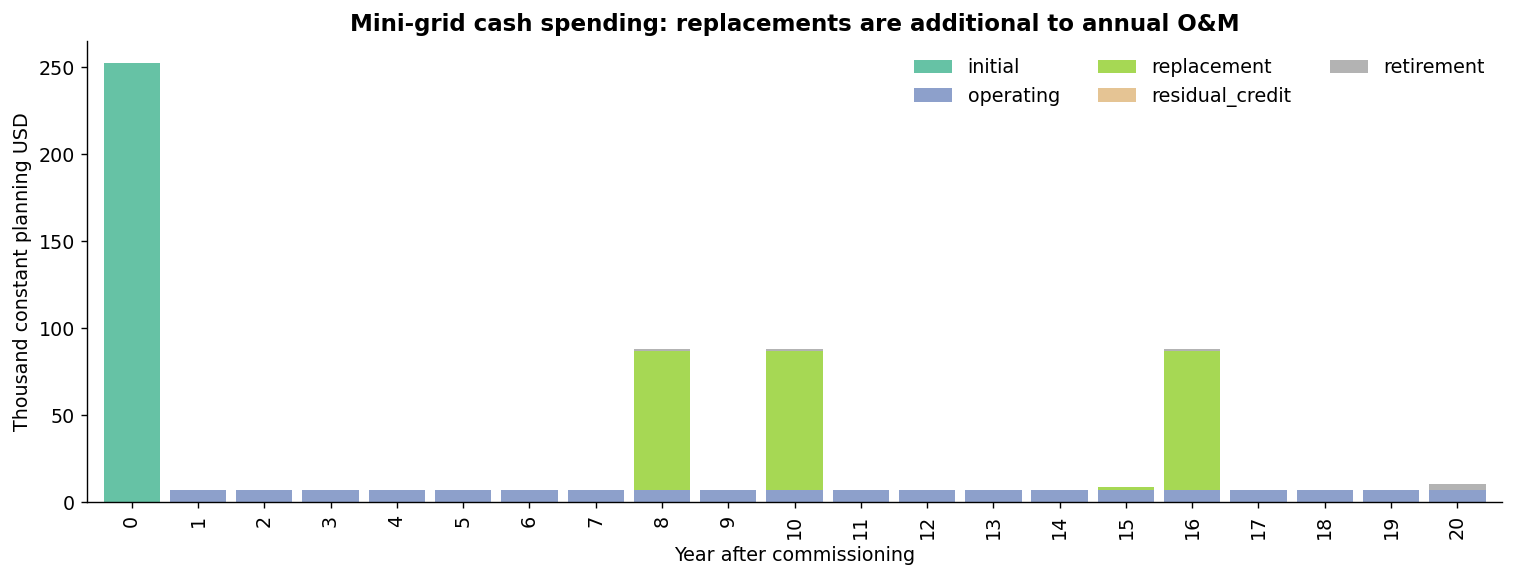

kind,initial,operating,replacement,residual_credit,retirement
year,,,,,
0,"252,440",0,0,0,0
1,0,"7,068",0,0,0
8,0,"7,068","79,642",0,"1,050"
10,0,"7,068","79,645",0,"1,116"
16,0,"7,068","79,642",0,"1,050"
20,0,"7,068",0,0,"3,330"


**Financing illustration:** 70% debt, 30% equity, no grant; 10-year loan at 10% real interest. These are scenarios, not available financing terms.

,debt_USD,equity_USD,annual_debt_service_USD,year1_operating_plus_debt_USD
Standalone / 100 homes,"216,493","92,783","35,233","38,388"
Mini-grid / 100 homes,"176,708","75,732","28,758","35,826"
Grid extension / 5 km new MV,"130,561","55,955","21,248","33,147"
Grid + repair / synthetic case,"163,825","70,211","26,662","39,360"


Debt service is shown for liquidity planning and is **not added to NPC**, which already charges the initial investment and discounts future costs. Year-1 operations plus debt service excludes equity return, replacement reserves and later replacement purchases. Grants reduce sponsor funding, not total system resource requirements.

In [5]:
ledger=pd.DataFrame(mg['ledger'])
annual=ledger.pivot_table(index='year',columns='kind',values='cost_USD',aggfunc='sum',fill_value=0)
fig,ax=plt.subplots(figsize=(12,4.5),layout='constrained')
(annual/1000).plot.bar(stacked=True,ax=ax,width=.85,colormap='Set2')
ax.set_ylabel('Thousand constant planning USD');ax.set_xlabel('Year after commissioning')
ax.set_title('Mini-grid cash spending: replacements are additional to annual O&M')
ax.legend(title='',ncol=3,frameon=False)
fig.savefig(RESULTS/'lifetime_cashflows.png',bbox_inches='tight');plt.show()
display(money_table(annual.loc[[0,1,8,10,16,20]]))

fin=central[['debt_USD','equity_USD','annual_debt_service_USD','year1_operating_plus_debt_USD']].copy()
fin.index=[labels[x].replace('\n',' / ') for x in fin.index]
display(Markdown('**Financing illustration:** 70% debt, 30% equity, no grant; 10-year loan at 10% real interest. These are scenarios, not available financing terms.'))
display(money_table(fin))
display(Markdown('Debt service is shown for liquidity planning and is **not added to NPC**, which already charges the initial investment and discounts future costs. Year-1 operations plus debt service excludes equity return, replacement reserves and later replacement purchases. Grants reduce sponsor funding, not total system resource requirements.'))

## 4. Which assumptions matter?

The combined lower-input and higher-input cases are stress scenarios, **not confidence intervals**. They change equipment costs, delivery allowances, battery life and financing together. For interpretation, the second chart varies one input at a time from the central case.

Grid distance is route length, not the atlas's straight-line distance to a possibly unsuitable line. No crossing of these curves is reported as an economically validated connection threshold: generation adequacy, grid service and routing have not yet been checked.

scenario,lower_input,central,higher_input
Standalone / 100 homes,0.55,1.51,5.50
Mini-grid / 100 homes,0.50,1.29,4.39
Grid extension / 5 km new MV,0.39,0.94,2.75
Grid + repair / synthetic case,0.46,1.12,3.41


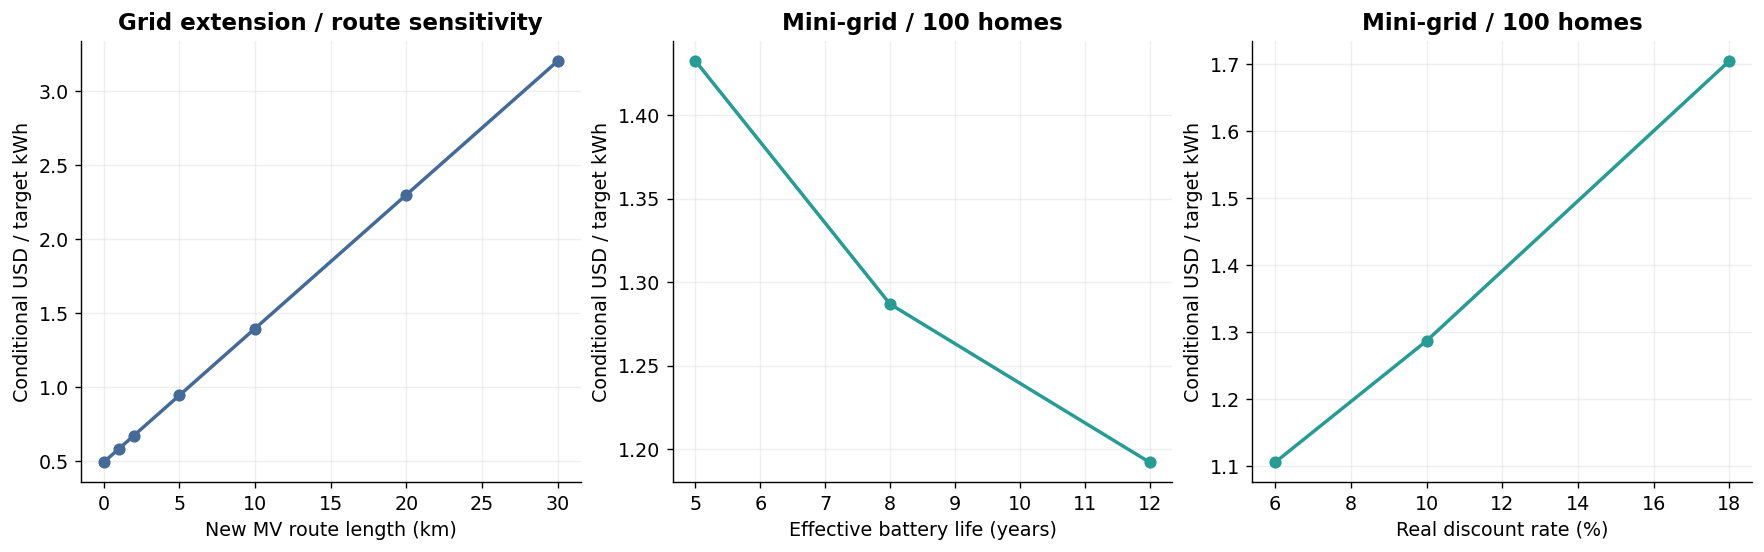

In [6]:
comparison=summary.pivot(index='case',columns='scenario',values='conditional_USD_per_target_kWh').reindex(central.index)
comparison=comparison[['lower_input','central','higher_input']]
comparison.index=[labels[x].replace('\n',' / ') for x in comparison.index]
display(comparison.style.format('{:.2f}').set_caption('Conditional USD per target kWh — no feasibility-certified winner'))

sens=pd.read_csv(RESULTS/'sensitivity.csv')
fig,axes=plt.subplots(1,3,figsize=(14,4.3),layout='constrained')
specs=[('grid_extension','new_MV_route_km','New MV route length (km)'),
       ('mini_grid','battery_life_years','Effective battery life (years)'),
       ('mini_grid','real_discount_rate','Real discount rate (%)')]
for ax,(case,driver,xlabel) in zip(axes,specs):
    s=sens.query('case == @case and driver == @driver').sort_values('value')
    x=s.value*100 if driver=='real_discount_rate' else s.value
    ax.plot(x,s.conditional_USD_per_target_kWh,marker='o',color=colors[case],linewidth=2)
    ax.set_xlabel(xlabel);ax.set_ylabel('Conditional USD / target kWh')
    ax.set_title('Grid extension / route sensitivity' if driver=='new_MV_route_km' else labels[case].replace('\n',' / '));ax.grid(alpha=.2)
fig.savefig(RESULTS/'sensitivities.png',bbox_inches='tight');plt.show()

## 5. Evidence versus modelling assumptions

**What the Sudan reports actually give us:** dated battery and inverter/panel prices in SDG, indicative local diesel prices, and evidence about delivery/payment constraints. They do not supply a complete compatible system, installation scope, FX rate, verified battery lifespan or current route costs.

The battery table below retains city and date. A 200 Ah battery without voltage cannot be converted into kWh. The panel table's printed “590 kW” is unresolved, so it is not normalized into a panel cost per kW. The separate 550 W interview quote is not used to silently correct that table. Do not combine quotes across dates/specifications into a supposedly contemporaneous turnkey offer.

In [7]:
evidence=ROOT/'data/report_evidence'
if evidence.exists():
    prices=pd.read_csv(evidence/'market_prices_2025.csv')
    batteries=prices.query("product == 'lithium_ion_battery'")
    display(batteries[['data_period','city','price_SDG','nominal_energy_kWh','derived_SDG_per_nominal_kWh']]
            .style.format({'price_SDG':'{:,.0f}','nominal_energy_kWh':'{:,.0f}','derived_SDG_per_nominal_kWh':'{:,.0f}'},na_rep='No quote'))
    fuel=pd.read_csv(evidence/'fuel_prices_2024.csv')
    display(fuel.query("fuel == 'diesel'")[['data_period','location','price_SDG_per_litre','availability']]
            .style.format({'price_SDG_per_litre':'{:,.0f}'},na_rep='No quote'))
else:
    display(Markdown('Local report evidence was not copied here. See the repository data/report_evidence collection.'))

,data_period,city,price_SDG,nominal_energy_kWh,derived_SDG_per_nominal_kWh
12,2025-09-18,Atbara,"5,400,000",10,"540,000"
13,2025-09-18,Port Sudan,"5,094,000",10,"509,400"
14,2025-09-18,Dongola,No quote,10,No quote
15,2025-09-18,Khartoum,"5,094,000",10,"509,400"
16,2025-09-28,Atbara,"5,300,000",10,"530,000"
17,2025-09-28,Port Sudan,"5,227,000",10,"522,700"
18,2025-09-28,Dongola,No quote,10,No quote
19,2025-09-28,Khartoum,"5,227,000",10,"522,700"
20,2025-10-16,Atbara,"5,000,000",10,"500,000"
21,2025-10-16,Port Sudan,"5,300,000",10,"530,000"


,data_period,location,price_SDG_per_litre,availability
0,2024-08,Port Sudan,"2,711",available; no black market reported
2,2024-08,Shandi,"2,800",no black market reported
4,2024-08,Sinnar,No quote,unavailable in stations and black market
6,2024-08,Kosty,"8,333",black market only; stations out of service
8,2024-08,Omdurman,"3,050",gasoline price not reported
10,2024-08,Darfur region; Khartoum city; Kordofan region,No quote,black market dependence; no prices given


### The editable cost assumptions

All USD values in the next table are **provisional analyst inputs** on the assigned constant-2025 basis. They are neither inferred FX conversions nor automatically inflated historical costs. The anchor column in `components.csv` points to benchmark evidence or explains that a value is an unsourced allowance. Quantity and scope matter as much as unit price.

The ESMAP handbook provides useful historical multi-country component benchmarks; the separate regional grid inputs come from a **South Sudan** study, not Sudan. We use them as context and retain their dates/definitions. The detailed source URLs, page numbers and downloaded-file hashes are in `sources.json` and `benchmark_evidence.csv`.

In [8]:
display(components[['component','quantity_unit','low_USD','base_USD','high_USD','life_years','annual_om_fraction']]
        .style.format({'low_USD':'{:,.0f}','base_USD':'{:,.0f}','high_USD':'{:,.0f}',
                       'life_years':'{:,.0f}','annual_om_fraction':'{:.1%}'}))
params=pd.read_csv(DATA/'scenario_parameters.csv')
display(params[['parameter','lower_input','central','higher_input','unit']].style.format(precision=3))
display(Markdown('Component lifetimes are fixed except battery life, which is overridden by the scenario parameter. Rates use fractions: 0.10 means 10%. A blank source price is never interpreted as zero.'))

,component,quantity_unit,low_USD,base_USD,high_USD,life_years,annual_om_fraction
0,pv_module,kWp,200,300,500,25,1.0%
1,pv_inverter,kW_AC,80,150,250,10,1.0%
2,battery,kWh_nominal,250,350,550,8,0.5%
3,battery_inverter,kW_AC,300,420,700,10,1.0%
4,shs_hybrid_inverter,kW_AC,200,350,600,10,1.0%
5,pv_bos,kWp,60,120,220,25,1.0%
6,diesel_genset,kW_electric,450,650,"1,000",10,3.0%
7,fuel_tank_ats,system,500,"1,200","2,500",15,2.0%
8,mv_line,route_km,"12,000","20,000","35,000",30,2.0%
9,lv_line,route_km,"5,000","10,000","18,000",30,2.0%


,parameter,lower_input,central,higher_input,unit
0,horizon_years,20.000,20.000,20.000,year
1,real_discount_rate,0.060,0.100,0.180,fraction
2,international_freight,0.040,0.080,0.150,fraction_imported_hardware
3,nonrecoverable_tax,0.000,0.050,0.150,fraction_imported_plus_international_freight
4,inland_logistics,0.030,0.100,0.250,fraction_transport_eligible_hardware
5,equipment_installation,0.080,0.150,0.250,fraction_labour_eligible_hardware
6,engineering_development,0.040,0.080,0.120,fraction_direct_resource_cost
7,contingency,0.050,0.100,0.200,fraction_direct_plus_engineering
8,battery_life_years,12.000,8.000,5.000,year
9,insurance_fraction,0.000,0.005,0.020,fraction_component_purchase_cost_per_year


Component lifetimes are fixed except battery life, which is overridden by the scenario parameter. Rates use fractions: 0.10 means 10%. A blank source price is never interpreted as zero.

## 6. What was checked, what remains missing, and how to use this

The checks below exercise accounting against hand-calculated cases: a zero-interest annuity, loan repayment, a replacement at year 5 but not at retirement, discounted residual value, losses/fuel units, installed-price scope, grant/debt separation and input errors. These validate the implementation's arithmetic, **not the real-world prices or the service feasibility**.

In [9]:
check=subprocess.run([sys.executable,str(MODEL/'check_costs.py')],capture_output=True,text=True)
if check.returncode:
    raise RuntimeError(check.stdout+'\n'+check.stderr)
validation=json.loads((RESULTS/'validation.json').read_text())
display(pd.DataFrame([validation]))
coverage=pd.read_csv(DATA/'coverage.csv')
display(coverage[['cost_or_requirement','status','needed_to_upgrade']])

,checks_run,failures,errors,passed,scope
0,9,0,0,True,"Accounting, dimensions and limiting cases; not independent validation of costs or feasibility"


,cost_or_requirement,status,needed_to_upgrade
0,"PV, storage and conversion",included_provisional,"Supplier quotations, DoD, efficiency, heat derating, warranties"
1,"Freight, port and inland delivery",included_provisional,"Actual shipment value, route, cargo scope and cost; source shipment shares cannot be applied as ..."
2,Installation and commissioning,included_provisional,BOM/EPC offer and contractor scope
3,"MV/LV, transformer and connection",included_provisional,"Route, conductor, poles, voltage drop, protection and quotes"
4,"Engineering, permits and contingency",included_provisional,Actual project development and fiscal treatment
5,"Fuel, energy, O&M and administration",included_provisional,"Hourly dispatch, delivered fuel, upstream supply cost and service contract"
6,Replacements and disposal,included_provisional,"Cycle/temperature life, actual spares and recycling offers"
7,Finance and collections,included_provisional,"Finance offer, subsidy design, affordability and collection evidence"
8,Conflict damage and repair,synthetic_case_only,Asset condition survey and repair BOM/time; never infer from DRE risk class
9,Grid reliability and upstream expansion,unvalidated_boundary,"Available MW, hourly outages, source rehabilitation and backup adequacy"


### Change one assumption and recalculate

Edit `data/system_costs/components.csv` for prices, equipment life and O&M; `scenario_parameters.csv` for logistics, finance, fuel and effective battery life; `bill_of_quantities.csv` for equipment/route quantities; and `case_designs.csv` for demand, losses and repair assumptions. **Run All** to regenerate every result. Do not edit result CSVs as inputs. Changing quantities does not trigger a capacity optimizer or certify adequacy.

The following example changes mini-grid battery life without changing the source evidence. It does not alter the saved central scenario.

In [10]:
example=evaluate('mini_grid',overrides={'battery_life_years':5})['summary']
display(pd.DataFrame([{'case':'Central: 8-year battery',
                       'NPC_USD':mg['summary']['lifecycle_NPC_USD']},
                      {'case':'Sensitivity: 5-year battery','NPC_USD':example['lifecycle_NPC_USD']}]))

,case,NPC_USD
0,Central: 8-year battery,399890.409081
1,Sensitivity: 5-year battery,445217.011951


### Use in PyPSA and the next study step

1. Select a small, geographically varied settlement sample. Establish household counts, critical/productive loads and the same hourly service requirement for each option. DRE buildings are not automatically customer accounts.
2. Obtain comparable quotations and route surveys. Replace the highest-impact provisional inputs first: installed MV/LV, usable battery life and price, delivery, repair BOM, bulk supply and delivered fuel. Record quote date, currency, FX convention, specification and what is included.
3. Optimize generation/storage and dispatch chronologically for each candidate service arrangement. Keep battery **energy** and inverter **power** separate. Confirm unmet load, peaks and seasonal performance before computing an LCOE or comparing options.
4. Apply the full cost ledger to feasible designs, then compare under finance, demand, fuel-access and damage scenarios. Shared feeders must be costed once when scaling beyond individual sites.

For a one-year PyPSA objective, `capital_cost` must be periodized, not raw USD/kW CAPEX. Convert USD/kW-year to USD/MW-year (×1,000); storage energy USD/kWh-year to USD/MWh-year (×1,000). A `Store` with charging/discharging `Link`s permits independent power/energy sizing. Link power is defined at its input, so efficiency and rating conventions must be reconciled. Charge the physical bidirectional converter once, not independently on both links. Fixed route/connection costs need activation/choice logic rather than an arbitrary per-MW capacity coefficient.

At the central fuel assumptions, diesel's simple variable electric-output cost is `(1.5 USD/litre × 0.32 litre/kWh + 0.03 USD/kWh) × 1,000 = 510 USD/MWh`. This already uses electrical-output fuel consumption; do not divide by efficiency again. The per-litre input remains provisional and the annual diesel share used in this notebook must be replaced by dispatch.

**Sections 1–6 provide the cost accounting. Section 7 below now applies it to an hourly three-cluster optimization pilot. The 2022 national dispatch model is unchanged and no national least-cost map is claimed.**

### References

- [ESMAP (2022), Mini Grids for Half a Billion People](https://documents1.worldbank.org/curated/en/099635009232259510/pdf/P1751510dd4ab407e083a6098d1905fa94f.pdf), Table 1.4, physical PDF page 85 / printed page 57. Historical benchmarks; not a Sudan quote.
- [World Bank, South Sudan high-level electrification prospectus](https://documents1.worldbank.org/curated/en/099062423121020382/pdf/P175227003a74408f0bc3a075ae51a5747e.pdf), Annex Table 4, PDF pages 27–28. South Sudan planning assumptions, not Sudan observations.
- [Sudan report evidence source register](../../data/report_evidence/source_register.csv): R17, UNDP 2026 solar value-chain study, PDF pages 29 and 31; R12, World Bank August 2024 electricity snapshot, PDF pages 9–10.
- [PyPSA 1.0.6 Generator](https://docs.pypsa.org/v1.0.6/user-guide/components/generators/) and [Store](https://docs.pypsa.org/v1.0.6/user-guide/components/stores/) component documentation.

<a id="optimized-pilot"></a>
## 7. Next study step: optimize supply for three real settlement clusters

**This section advances beyond the fixed illustrative budgets above.** It sizes PV, batteries and converters, dispatches every hour of 2022, and compares three supply arrangements at the **same assumed service level**. The LP's annual objective includes the complete lifecycle-cost framework, not just equipment purchase prices.

We selected three atlas clusters before examining costs: near-grid, remote compact and remote dispersed. These are illustrative cases, not a representative national sample. Names are reverse-geocoded labels; the geohash identifies the actual cluster. Potential connections are building proxies, not verified households. Absence of detected nightlight does not prove lack of electricity.

The study uses **real source coordinates and hourly NASA POWER weather**, with **assumed demand, routes, costs and grid service**. There is no post-war field validation or present-day safety assessment. Conditional rankings are meaningful within this model, not construction recommendations.

This section reuses checked cached optimization outputs when inputs are unchanged. Set `FORCE_PILOT=True` below to solve again. Changing cost inputs, pilot configuration, weather or model code invalidates the cache and triggers fresh solves. Downloading new source data is a separate explicit step.

In [11]:
from pilot_model import run as run_pilot, DATA as PILOT_DATA, OUT as PILOT_OUT, CONFIG as PILOT_CONFIG
from check_pilot import check as check_pilot
FORCE_PILOT = False
pilot = run_pilot(force=FORCE_PILOT)
pilot_validation = check_pilot()
sites = pd.read_csv(PILOT_DATA/'sites.csv')
display(sites[['pilot_type','geohash','village_name','admin_cgaz_1','num_connections','demand',
               'distance_to_existing_transmission_lines','hull_area']].rename(columns={
               'num_connections':'Source potential connections','demand':'Source demand kWh/day',
               'distance_to_existing_transmission_lines':'Straight-line grid distance km','hull_area':'Area km2'}))

Using checked cached optimization outputs; set FORCE_PILOT=True to solve again.


{"passed": true, "optimized_cases": 18, "hourly_case_snapshots": 157680, "same_service": true, "source_hashes": true, "lifecycle_objective_reconciled": true, "status": "Numerical and data integrity checks only; no independent field validation", "any_design_bound_binding": false}


,pilot_type,geohash,village_name,admin_cgaz_1,Source potential connections,Source demand kWh/day,Straight-line grid distance km,Area km2
0,near_grid,scbmu9pc3u,Al Kurumuk,Blue Nile,196,65.7,1.54,0.492
1,remote_dense,sdxk3ns4zh,Ash Shiqeyyab,Gezira,132,44.2,30.88,0.021
2,remote_sparse,sfcc38ee31,Al Gash,Kassala,123,41.2,24.91,0.283


### Matched service and technical assumptions

| Input | Treatment in this pilot |
|---|---|
| Demand | 1 kWh/day per source potential connection; identical evening-heavy daily shape, repeated all year; no random diversity. This is a chosen recovery-service target, **not measured demand or the lower atlas demand formula**. |
| Standalone | Identical independent AC-coupled PV/battery systems per service point. The aggregate LP is equivalent to assigning every point the same proportional system and dispatch. Equipment receives an explicit 25% small-order premium. No household diesel. |
| Mini-grid | Shared PV/battery/converter plus optional diesel generation, capped at 20% of delivered annual demand. Fixed backup-ready tank and site costs are included even if diesel is unused. |
| Grid | A fixed 80 kW usable tie-in, local PV/battery allowed, no diesel; source initially available all hours. The tie-in rating assumes a 100 kVA transformer at 0.8 power factor. This is a boundary condition, not a measured grid capability. |
| Network | New MV route proxy = 1.3 × straight-line source distance. Total LV branch-length proxy = 1.3 × √(service points × settlement area in km²). These are editable geometric assumptions, not surveyed feeders. Constant downstream losses: 8% mini-grid, 10% grid. |
| PV profile | NASA POWER hourly GHI and ambient temperature for 2022, UTC. Horizontal-array approximation: cell temperature from an assumed 45°C NOCT; −0.4%/°C temperature coefficient, 90% miscellaneous DC factor and 96% inverter efficiency. No tilt/transposition or measured calibration. |
| Battery | Separate nominal energy and converter power; 10–90% SOC, 95% efficiency in each direction, cyclic full-year state of charge. AC charge and discharge ratings share one converter; it is charged once. |
| Reliability | Every hourly demand must be supplied; no load-shedding option. No reserve, component failures, N−1 test or measured outage trace. Passing this requirement means model adequacy for these assumptions. |
| Economics | Same central 20-year lifecycle assumptions, replacements and real 10% discount rate as the cost section. Dispatch replaces the old assumed diesel share/grid purchases. The 2022 weather/load year repeats for economic accounting; no demand growth or technology degradation trajectory. |

PV capacity is expressed in DC kWp with AC output profiles. The proxy assumes a 1:1 PV inverter rating. Batteries remain nominal kWh. Solar-home systems use separate AC PV and battery converters here; a packaged DC/hybrid design could cost less and should be tested later.

,geohash,mode,annual_delivered_kWh,pv_kWp,battery_nominal_kWh,converter_AC_kW,diesel_kW,initial_budget_USD,modelled_LCOE_USD_per_kWh
0,scbmu9pc3u,standalone,"71,540",197.1,179.7,28.8,0.0,"405,991",0.924
1,scbmu9pc3u,mini_grid,"71,540",56.8,174.5,26.2,5.1,"389,888",0.962
2,scbmu9pc3u,grid_extension,"71,540",10.8,-0.0,-0.0,0.0,"287,266",0.746
3,sdxk3ns4zh,standalone,"48,180",56.8,119.5,19.4,0.0,"183,843",0.666
4,sdxk3ns4zh,mini_grid,"48,180",34.1,120.2,19.1,2.0,"186,848",0.730
5,sdxk3ns4zh,grid_extension,"48,180",7.2,-0.0,-0.0,0.0,"1,047,427",3.209
6,sfcc38ee31,standalone,"44,895",90.7,111.0,19.9,0.0,"216,610",0.806
7,sfcc38ee31,mini_grid,"44,895",31.6,111.3,16.8,2.9,"241,776",0.945
8,sfcc38ee31,grid_extension,"44,895",6.7,-0.0,-0.0,0.0,"925,670",3.055


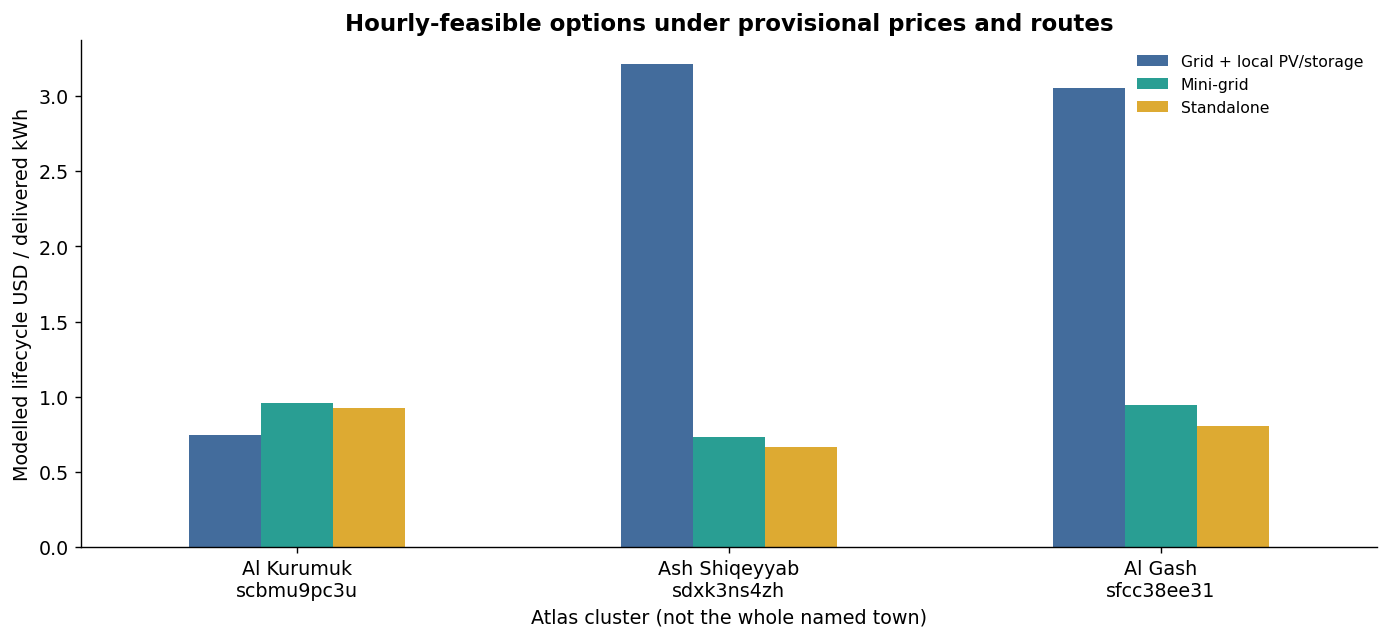

,Cluster,Conditional lowest-cost option,USD/kWh,Next-option premium %
0,Al Kurumuk [scbmu9pc3u],Grid + local PV/storage,0.746,23.9
1,Ash Shiqeyyab [sdxk3ns4zh],Standalone,0.666,9.7
2,Al Gash [sfcc38ee31],Standalone,0.806,17.3


A “remote compact” label does not predetermine a mini-grid winner. Local distribution, load size, household equipment pricing and weather can change the ranking. No national extrapolation is made.

In [12]:
base_pilot=pilot.query("scenario=='base'").copy()
case_names={'standalone':'Standalone','mini_grid':'Mini-grid','grid_extension':'Grid + local PV/storage'}
site_names=sites.set_index('geohash').apply(lambda s: f"{s.village_name} [{s.name}]",axis=1).to_dict()
display(base_pilot[['geohash','mode','annual_delivered_kWh','pv_kWp','battery_nominal_kWh','converter_AC_kW','diesel_kW',
                    'initial_budget_USD','modelled_LCOE_USD_per_kWh']].style.format({
                    'annual_delivered_kWh':'{:,.0f}','pv_kWp':'{:.1f}','battery_nominal_kWh':'{:.1f}',
                    'converter_AC_kW':'{:.1f}','diesel_kW':'{:.1f}','initial_budget_USD':'{:,.0f}',
                    'modelled_LCOE_USD_per_kWh':'{:.3f}'}))
price_grid=base_pilot.pivot(index='geohash',columns='mode',values='modelled_LCOE_USD_per_kWh').reindex(sites.geohash)
fig,ax=plt.subplots(figsize=(11,5),layout='constrained')
price_grid.rename(columns=case_names).set_axis([sites.set_index('geohash').loc[k,'village_name']+'\n'+k for k in price_grid.index]).plot.bar(ax=ax,rot=0,color=['#436C9C','#299E93','#DDAA32'])
ax.set_ylabel('Modelled lifecycle USD / delivered kWh');ax.set_xlabel('Atlas cluster (not the whole named town)')
ax.set_title('Hourly-feasible options under provisional prices and routes')
ax.legend(title='',frameon=False,fontsize=9)
fig.savefig(PILOT_OUT/'option_costs.png',bbox_inches='tight');plt.show()
ranked=base_pilot.sort_values('modelled_LCOE_USD_per_kWh').groupby('geohash',sort=False).head(2)
rows=[]
for sid,g in ranked.groupby('geohash'):
    g=g.sort_values('modelled_LCOE_USD_per_kWh');first,second=g.iloc[0],g.iloc[1]
    rows.append({'Cluster':site_names[sid], 'Conditional lowest-cost option':case_names[first['mode']],
                 'USD/kWh':first.modelled_LCOE_USD_per_kWh,
                 'Next-option premium %':100*(second.modelled_LCOE_USD_per_kWh/first.modelled_LCOE_USD_per_kWh-1)})
display(pd.DataFrame(rows).style.format({'USD/kWh':'{:.3f}','Next-option premium %':'{:.1f}'}))
display(Markdown('A “remote compact” label does not predetermine a mini-grid winner. Local distribution, load size, household equipment pricing and weather can change the ranking. No national extrapolation is made.'))

### Generation mixes and seasonal storage operation

The pies show annual generation/imports for the conditionally cheapest base-case option at each cluster. Storage discharge is **not** added as new generation. The weekly plot shows all energy flows for the compact site's mini-grid, including charge below the axis and battery SOC. Every hour of the year is solved; the displayed week is selected only for readability.

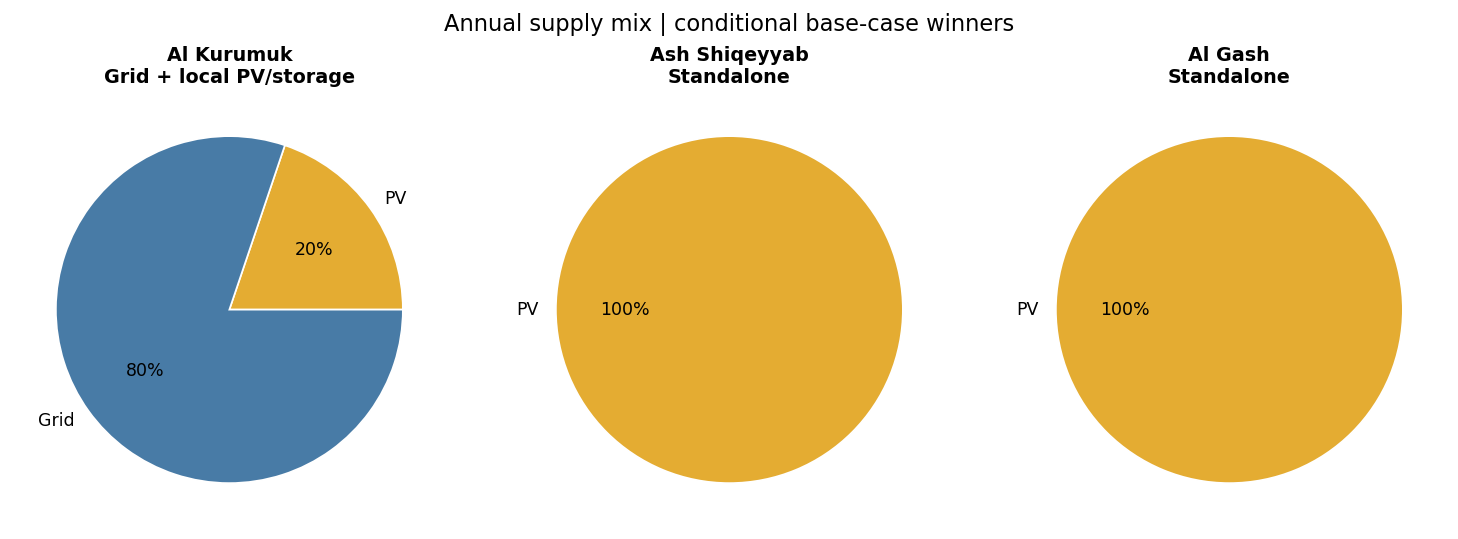

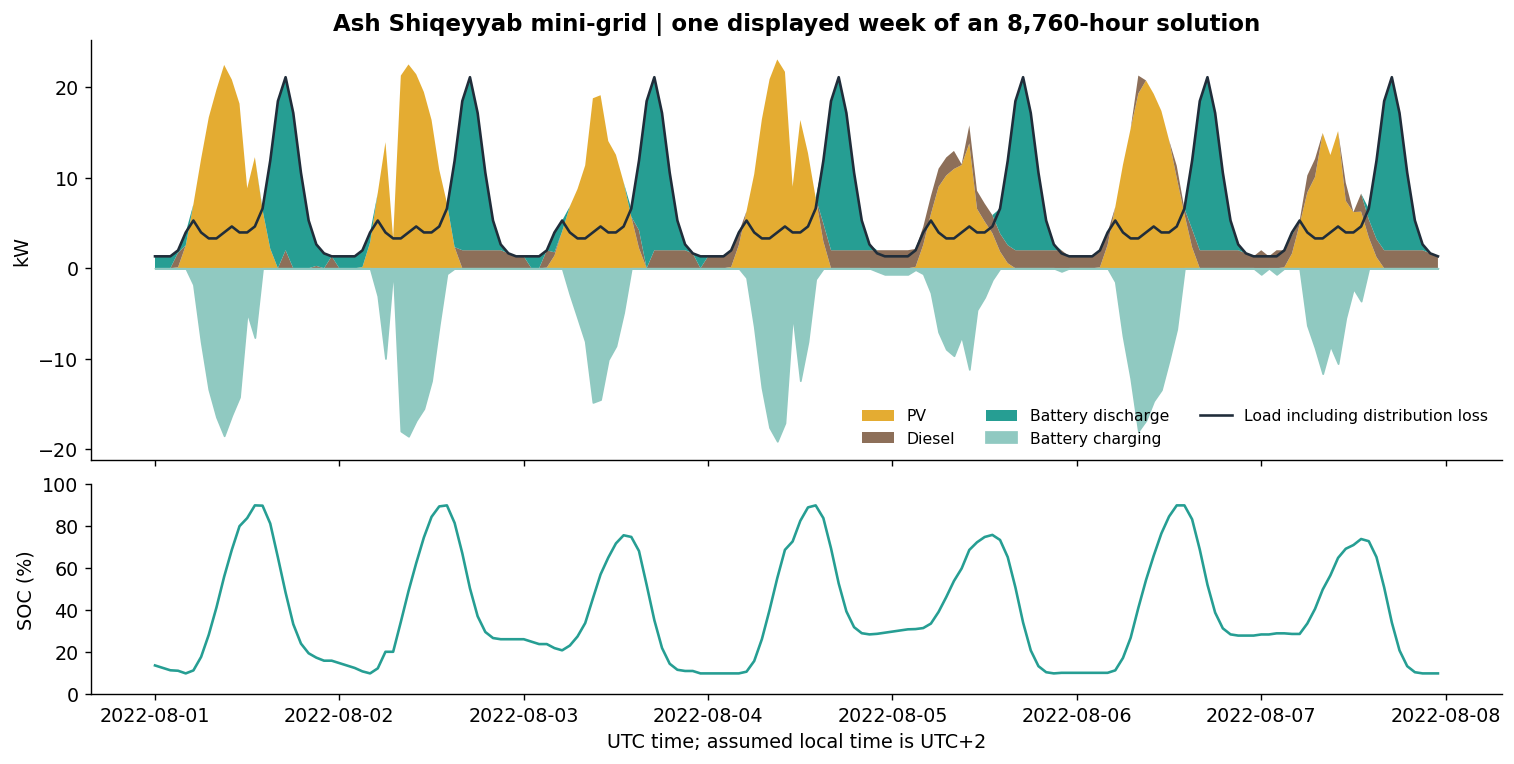

In [13]:
winners=base_pilot.loc[base_pilot.groupby('geohash').modelled_LCOE_USD_per_kWh.idxmin()]
fig,axes=plt.subplots(1,3,figsize=(12,4.2),layout='constrained')
for ax,(_,r) in zip(axes,winners.iterrows()):
    vals=np.array([r.pv_generation_kWh,r.diesel_generation_kWh,r.grid_import_kWh])
    mask=vals>1e-5
    ax.pie(vals[mask],labels=np.array(['PV','Diesel','Grid'])[mask],colors=np.array(['#E4AC32','#8D6F59','#487BA6'])[mask],
           autopct='%1.0f%%',wedgeprops={'edgecolor':'white'},textprops={'fontsize':10})
    ax.set_title(r.source_name+'\n'+case_names[r['mode']],fontsize=11)
fig.suptitle('Annual supply mix | conditional base-case winners',fontsize=13)
fig.savefig(PILOT_OUT/'pilot_supply_pies.png',bbox_inches='tight');plt.show()

sample=base_pilot.query("pilot_type=='remote_dense' and mode=='mini_grid'").iloc[0]
hourly=pd.read_csv(PILOT_OUT/(sample.run_id+'_hourly.csv.gz'),parse_dates=['time_UTC']).set_index('time_UTC')
week=hourly.loc['2022-08-01':'2022-08-07']
fig,axes=plt.subplots(2,1,figsize=(12,6),sharex=True,layout='constrained',gridspec_kw={'height_ratios':[2,1]})
axes[0].stackplot(week.index,week.pv_MW*1000,week.diesel_MW*1000,week.discharge_MW*1000,
                  labels=['PV','Diesel','Battery discharge'],colors=['#E4AC32','#8D6F59','#269E93'])
axes[0].fill_between(week.index,0,-week.charge_MW*1000,color='#90C9C1',label='Battery charging')
axes[0].plot(week.index,week.bus_load_MW*1000,color='#202D3A',linewidth=1.5,label='Load including distribution loss')
axes[0].set_ylabel('kW');axes[0].legend(ncol=3,fontsize=9,frameon=False)
axes[0].set_title(sample.source_name+' mini-grid | one displayed week of an 8,760-hour solution')
axes[1].plot(week.index,week.battery_soc*100,color='#269E93');axes[1].set_ylim(0,100)
axes[1].set_ylabel('SOC (%)');axes[1].set_xlabel('UTC time; assumed local time is UTC+2')
fig.savefig(PILOT_OUT/'pilot_dispatch_week.png',bbox_inches='tight');plt.show()

### Recovery stresses: the model chooses different capacities

These are **re-optimized cases**, not post-processing price multipliers:

- **Evening grid interruption:** grid unavailable from 18:00 through 23:59 local time every day. It is a synthetic outage stress, not a measured wartime schedule; local PV/battery can respond.
- **No diesel:** the mini-grid cannot consume diesel; PV and batteries must cover the entire year. This represents a fuel-access boundary, not an inferred damage fraction.
- **Double demand:** the compact site receives 2 kWh/service point/day for all three architectures. Routes, customers and prices remain fixed.

The full run contains 18 optimizations: 9 base options, 3 interrupted-grid cases, 3 no-diesel mini-grids and 3 higher-demand options. The remaining cost uncertainties are not resolved by these tests.

In [14]:
stress=pilot.query("scenario!='base'").copy()
refs=base_pilot[['geohash','mode','equivalent_annual_cost_USD','modelled_LCOE_USD_per_kWh']].rename(columns={
     'equivalent_annual_cost_USD':'base_annual_cost','modelled_LCOE_USD_per_kWh':'base_LCOE'})
stress=stress.merge(refs,on=['geohash','mode'],validate='many_to_one')
stress['annual_cost_change_percent']=100*(stress.equivalent_annual_cost_USD/stress.base_annual_cost-1)
display(stress[['geohash','mode','scenario','pv_kWp','battery_nominal_kWh','initial_budget_USD',
                'modelled_LCOE_USD_per_kWh','annual_cost_change_percent']].style.format({
                 'pv_kWp':'{:.1f}','battery_nominal_kWh':'{:.1f}','initial_budget_USD':'{:,.0f}',
                 'modelled_LCOE_USD_per_kWh':'{:.3f}','annual_cost_change_percent':'{:.1f}'}))
display(Markdown('When demand doubles, annual cost and cost per kWh can move in different directions because fixed network/site costs are spread across more energy. This is not evidence of measured future demand.'))

near=sites.query("pilot_type=='near_grid'").iloc[0].geohash
compact=sites.query("pilot_type=='remote_dense'").iloc[0].geohash
def pilot_price(sid,mode,scenario):
    return pilot.query('geohash==@sid and mode==@mode and scenario==@scenario').iloc[0].modelled_LCOE_USD_per_kWh
display(Markdown(f"""**What this run teaches us:**

- At the near-grid cluster, grid supply costs **${pilot_price(near,'grid_extension','base'):.2f}/kWh** with the assumed continuous upstream service, increasing to **${pilot_price(near,'grid_extension','evening_outage'):.2f}/kWh** with evening interruptions. Standalone supply is **${pilot_price(near,'standalone','base'):.2f}/kWh**. Distance alone is therefore insufficient to choose a connection.
- At the compact cluster, the base mini-grid costs **${pilot_price(compact,'mini_grid','base'):.2f}/kWh**, versus **${pilot_price(compact,'standalone','base'):.2f}/kWh** for standalone. At double demand these become **${pilot_price(compact,'mini_grid','double_demand'):.2f}** and **${pilot_price(compact,'standalone','double_demand'):.2f}/kWh**. Demand assumptions can change the preferred architecture.
- These are conditional model responses. The study has not measured either location's real outage pattern, demand, customer count or quoted system costs.
"""))

,geohash,mode,scenario,pv_kWp,battery_nominal_kWh,initial_budget_USD,modelled_LCOE_USD_per_kWh,annual_cost_change_percent
0,scbmu9pc3u,grid_extension,evening_outage,41.9,150.2,"424,111",1.002,34.3
1,sdxk3ns4zh,grid_extension,evening_outage,27.2,101.1,"1,138,749",3.457,7.7
2,sfcc38ee31,grid_extension,evening_outage,25.2,94.3,"1,010,577",3.303,8.1
3,scbmu9pc3u,mini_grid,no_diesel,214.2,195.4,"546,545",1.219,26.8
4,sdxk3ns4zh,mini_grid,no_diesel,61.7,129.8,"217,311",0.791,8.3
5,sfcc38ee31,mini_grid,no_diesel,98.5,120.7,"309,786",1.124,18.9
6,sdxk3ns4zh,standalone,double_demand,113.6,238.9,"352,004",0.634,90.3
7,sdxk3ns4zh,mini_grid,double_demand,68.2,240.4,"302,613",0.596,63.3
8,sdxk3ns4zh,grid_extension,double_demand,14.3,-0.0,"1,054,090",1.680,4.7


When demand doubles, annual cost and cost per kWh can move in different directions because fixed network/site costs are spread across more energy. This is not evidence of measured future demand.

**What this run teaches us:**

- At the near-grid cluster, grid supply costs **$0.75/kWh** with the assumed continuous upstream service, increasing to **$1.00/kWh** with evening interruptions. Standalone supply is **$0.92/kWh**. Distance alone is therefore insufficient to choose a connection.
- At the compact cluster, the base mini-grid costs **$0.73/kWh**, versus **$0.67/kWh** for standalone. At double demand these become **$0.60** and **$0.63/kWh**. Demand assumptions can change the preferred architecture.
- These are conditional model responses. The study has not measured either location's real outage pattern, demand, customer count or quoted system costs.


### What is now checked—and what the next paper milestone needs

The pilot checks source hashes, complete hourly inputs, identical service targets, AC energy balance, chronological battery balance, SOC/converter limits, grid-outage restrictions, diesel-energy limits, and reconstructed lifecycle cost against the optimization objective. It also checks that removing fuel or grid availability cannot lower the optimized annual cost. A tiny 0.001 USD/MWh charge-flow tie-break penalty is excluded from reported financial costs. Source counts and names remain unverified.

An optimal LP solution does **not** validate current access, prices, field reliability, safety or routes. Before location recommendations:

1. Verify the three clusters' present buildings/customers and obtain hourly household, clinic, school and productive-use demand. Replace identical profiles with measured diversity and peaks.
2. Survey a usable grid tie-in and routes, conductor/transformer capacity, repair scope and outages. Replace the geometric lengths and flat losses with distribution design and power-flow checks.
3. Obtain comparable local quotations, exact battery specifications/lifetimes and finance terms. Test modular equipment and integrated solar-home packages, not only continuous capacities and the assumed small-order premium.
4. Use a validated tilted-PV model and multiple weather years; add component failures, maintenance and reserve requirements. Test actual fuel delivery limitations and multi-year demand/recovery timing.
5. Expand the sample, include shared feeders and productive loads, and test joint investment decisions. Do not extrapolate the three conditional winners into a national technology map.

The current comparison answers: **“Under these documented service, cost, weather and network assumptions, how should each candidate architecture be sized, and what does it cost?”** It is now a functioning pilot study rather than a list of example bills.

In [15]:
display(pd.DataFrame([pilot_validation]))
display(pilot[['max_power_balance_error_MW','max_storage_balance_error_MWh','annual_cost_objective_gap_USD']].abs().max().to_frame('Largest residual across 18 solves'))
display(base_pilot[['geohash','mode','pv_yield_proxy_kWh_per_kWp','atlas_longrun_yield_kWh_per_kWp']].drop_duplicates('geohash')
        .style.format({'pv_yield_proxy_kWh_per_kWp':'{:,.0f}','atlas_longrun_yield_kWh_per_kWp':'{:,.0f}'}))
display(Markdown('The annual solar columns have different weather periods and array assumptions. They are a diagnostic comparison, not a calibration target. Detailed hourly outputs, installed quantities and 20-year cash flows are in `results/pilot/`.'))

,passed,optimized_cases,hourly_case_snapshots,same_service,source_hashes,lifecycle_objective_reconciled,status,any_design_bound_binding
0,True,18,157680,True,True,True,Numerical and data integrity checks only; no independent field validation,False


,Largest residual across 18 solves
max_power_balance_error_MW,1.561251e-17
max_storage_balance_error_MWh,1.643650e-16
annual_cost_objective_gap_USD,1.915032e-08


,geohash,mode,pv_yield_proxy_kWh_per_kWp,atlas_longrun_yield_kWh_per_kWp
0,scbmu9pc3u,standalone,"1,566","1,674"
3,sdxk3ns4zh,standalone,"1,723","1,803"
6,sfcc38ee31,standalone,"1,723","1,836"


The annual solar columns have different weather periods and array assumptions. They are a diagnostic comparison, not a calibration target. Detailed hourly outputs, installed quantities and 20-year cash flows are in `results/pilot/`.

### Pilot sources and reproducibility

- [World Bank Group / VIDA Sudan DRE Atlas](https://energydata.info/dataset/sudan-distributed-renewable-energy-dre), 2025 release, CC BY 4.0; [existing project provenance](https://github.com/Elgenied/pypsa-sudan/blob/main/research/dre_atlas_2025/SOURCE_REGISTER.md). Selected source rows are retained unchanged in `data/electrification_pilot/sites.csv`.
- [NASA POWER hourly API](https://power.larc.nasa.gov/docs/services/api/temporal/hourly/): 2022 GHI and temperature, explicitly requested in UTC. Request URLs, parameter units, API metadata, source/derived hashes and the selected coordinates are in `source_manifest.json`. Hourly radiation is Wh/m² over each one-hour interval, numerically equivalent to its average W/m² here.
- Cost evidence and assumptions remain in `data/system_costs/`; model configuration and selection rules are in [the pilot input guide](../../data/electrification_pilot/README.md).

To solve explicitly from the project root: `python research/system_costs/pilot_model.py --force`. To recalculate saved results' checks: `python research/system_costs/check_pilot.py`. To regenerate this entire reading copy: `python research/system_costs/run_notebook.py --kernel pypsa`.

<a id="uncertainty-study"></a>
## 8. Uncertainty, break-even points and the next data priorities

**Which pilot choices survive changes in the assumptions—and where do they change?** This section varies ten inputs individually, then tests eight deliberately chosen joint scenarios at each cluster. Each operationally relevant problem is optimized over all 8,760 hours; identical problems reuse checked solutions. Network length/unit-price changes use exact fixed-cost adjustments where they cannot affect dispatch under this model.

These are exploratory bounds, **not observed Sudan distributions or confidence intervals**. The three clusters are illustrative, and scenario counts are not probabilities. We retain the same 2022 weather, assumed demand shape, constant-2025-USD cost basis and 20-year horizon. A result called “stable” means stable within the tests explicitly shown here.

The main deliverables are: cost-response curves, grid route thresholds, demand crossing brackets, joint-scenario cost penalties and a targeted list of evidence to collect. No current damage, verified routes or national optimum is inferred.

In [16]:
from uncertainty_model import load_results as load_uncertainty, OUT as UOUT, DESIGN as UDESIGN
from check_uncertainty import check as check_uncertainty
from uncertainty_analysis import analyse as analyse_uncertainty, LABELS as OPTION_LABELS
from IPython.display import Image
FORCE_UNCERTAINTY_TABLES = False  # Rebuild tables; still reuse identical checked case solutions.
uncertainty, joint = load_uncertainty(force=FORCE_UNCERTAINTY_TABLES)
uncertainty_validation = check_uncertainty()
uncertainty_views = analyse_uncertainty()
display(pd.DataFrame([{'Input':k, 'Tested values':str(v['values']), 'Central':v['central'],
                      'Unit / scope':v['unit']} for k,v in UDESIGN['axes'].items()]))
display(Markdown(f"**Execution:** {uncertainty_validation['unique_hourly_cases']} distinct hourly problems, including {uncertainty_validation['fresh_solves']} new solves and reused identical baseline cases. We checked {uncertainty_validation['checked_case_hours']:,} case-hours, {len(uncertainty)} single-input option rows and {len(joint)} joint-scenario option rows. Rows are comparisons, not independent samples."))

{"passed": true, "unique_hourly_cases": 201, "fresh_solves": 192, "checked_case_hours": 1760760, "one_at_a_time_comparisons": 288, "joint_option_comparisons": 72, "equal_service": true, "lifecycle_costs_reconstructed": true, "scenario_probabilities_assigned": false, "field_validated": false, "any_artificial_design_bound_binding": false}


,Input,Tested values,Central,Unit / scope
0,daily_kWh,"[0.5, 1, 2, 3]",1.00,kWh/service point/day
1,pv_cost_factor,"[0.7, 1, 1.3]",1.00,"multiplier: modules, BOS and PV inverter"
2,battery_cost_factor,"[0.6, 1, 1.4]",1.00,multiplier: battery modules only
3,discount_rate,"[0.06, 0.1, 0.18]",0.10,real annual fraction
4,diesel_price,"[1, 1.5, 3]",1.50,USD/litre delivered
5,grid_price,"[0.08, 0.15, 0.3]",0.15,USD/kWh at tie-in
6,outage_hours,"[0, 3, 6, 9]",0.00,hours/day from 18:00 local; wraps midnight
7,standalone_markup,"[1, 1.25, 1.5]",1.25,imported standalone hardware multiplier
8,mv_cost_factor,"[0.6, 1, 1.6]",1.00,installed MV line unit-cost multiplier
9,lv_length_factor,"[0.7, 1, 1.5]",1.00,multiplier on pilot LV route proxy


**Execution:** 201 distinct hourly problems, including 192 new solves and reused identical baseline cases. We checked 1,760,760 case-hours, 288 single-input option rows and 72 joint-scenario option rows. Rows are comparisons, not independent samples.

### 8.1 Demand and grid availability

Demand is scaled equally across all options at a site. Other inputs remain central in each single-input experiment. Outages begin at 18:00 local; the nine-hour schedule extends through 02:59 the next day. Longer schedules remove a nested set of hours. They are synthetic recovery stresses, not observed outage traces. Local PV/storage can be resized to supply every hour.

Points are solved cases. Lines between points aid reading and do not certify intermediate designs. Daily-demand and outage changes are separate experiments.

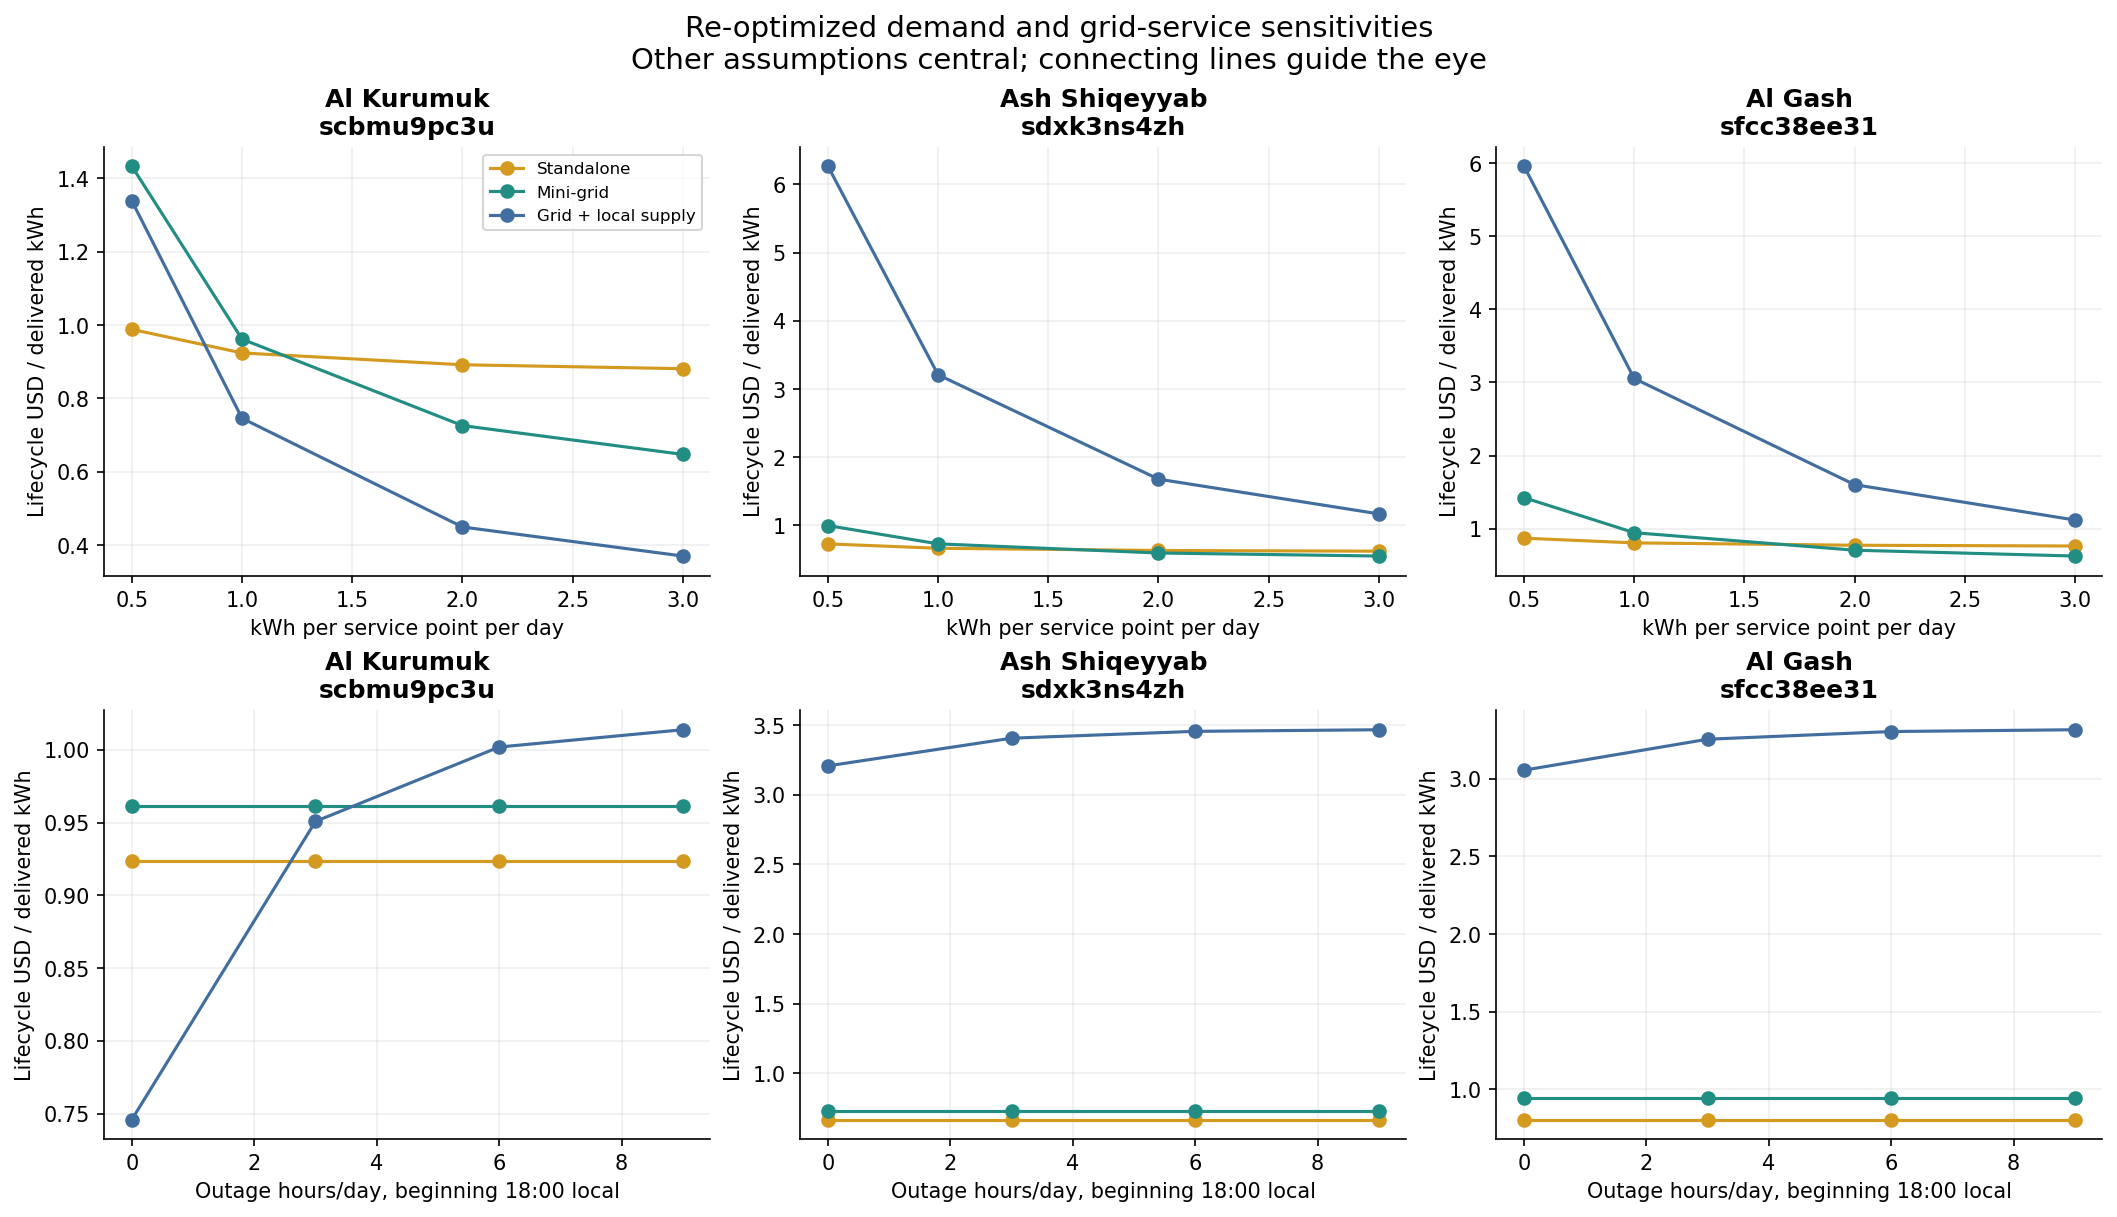

In [17]:
display(Image(filename=str(UOUT/'demand_outage_curves.png')))

### 8.2 What can overturn the base-case choice?

For each tested value, compare the original base-case architecture with its cheapest competitor, after both are resized. Positive advantage means the base architecture still costs less; negative means another option becomes cheaper. Each horizontal interval shows the minimum and maximum across the selected bounds for one input, with all other inputs central.

This is a range-dependent sensitivity screen. It is not a statistical importance ranking or a formal value-of-information calculation. Grid-price and diesel-price sensitivities only affect architectures that use those supplies. The mini-grid's existing 20% annual diesel-energy cap still applies.

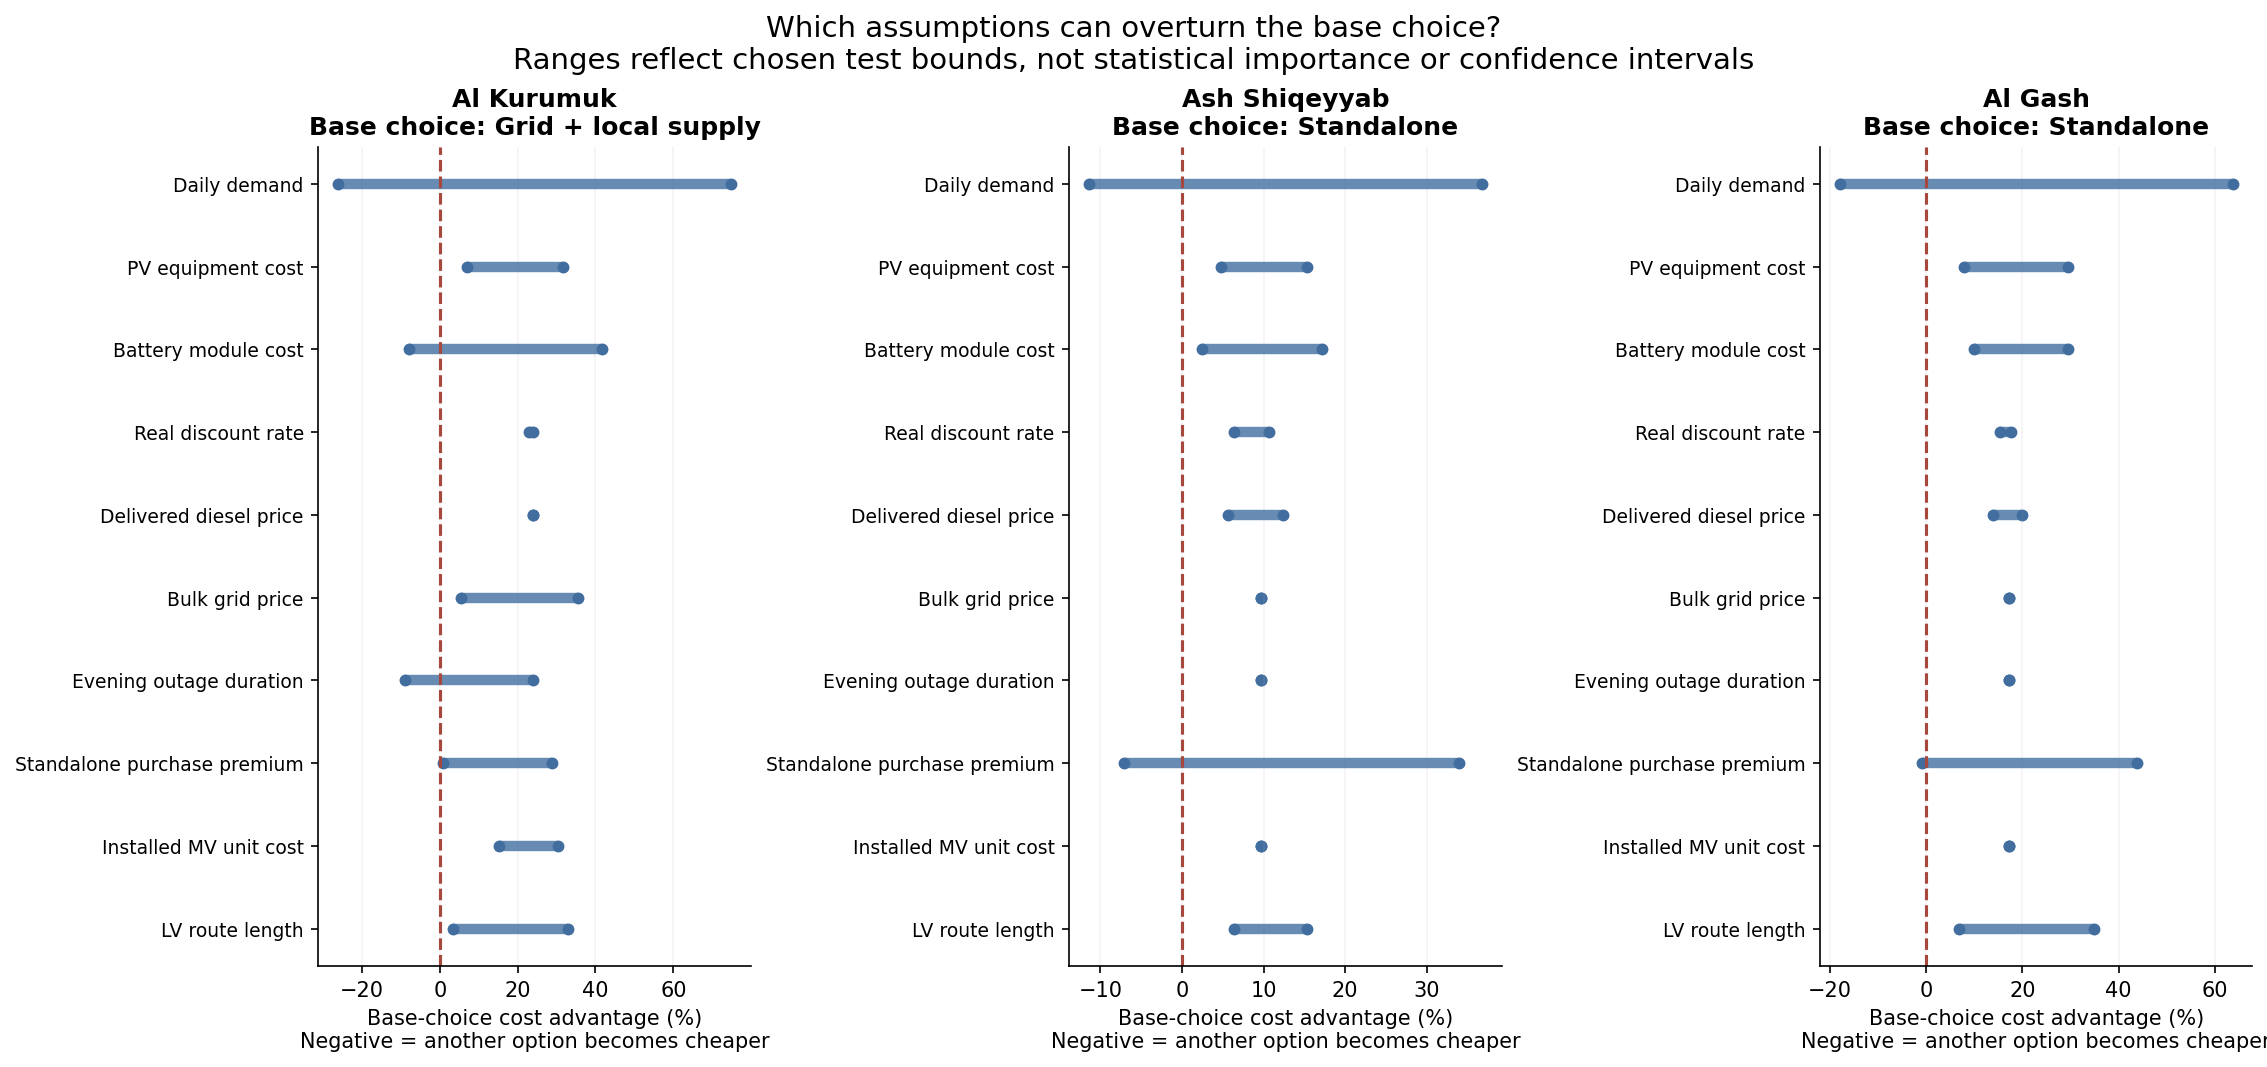

,geohash,driver,base_choice_loses_at_any_tested_value,margin_range_percentage_points,minimum_base_choice_advantage_percent,maximum_base_choice_advantage_percent
1,scbmu9pc3u,daily_kWh,True,101.0,-26.2,74.9
0,scbmu9pc3u,battery_cost_factor,True,49.6,-8.0,41.7
7,scbmu9pc3u,outage_hours,True,32.7,-8.9,23.9
4,scbmu9pc3u,grid_price,False,30.1,5.4,35.5
11,sdxk3ns4zh,daily_kWh,True,48.2,-11.4,36.8
19,sdxk3ns4zh,standalone_markup,True,41.0,-7.1,33.9
10,sdxk3ns4zh,battery_cost_factor,False,14.8,2.4,17.2
18,sdxk3ns4zh,pv_cost_factor,False,10.6,4.8,15.4
21,sfcc38ee31,daily_kWh,True,81.7,-18.0,63.7
29,sfcc38ee31,standalone_markup,True,44.7,-0.9,43.8


The table identifies the most decision-sensitive tested assumptions at each cluster. Test bounds influence this order; a driver outside these bounds or an omitted interaction can still matter. Complete curves and winners are retained in `one_at_a_time.csv` and `decision_summary.csv`.

In [18]:
display(Image(filename=str(UOUT/'decision_margin_ranges.png')))
priority=uncertainty_views['priorities'].copy()
priority=priority.sort_values(['geohash','base_choice_loses_at_any_tested_value','margin_range_percentage_points'],ascending=[True,False,False])
display(priority.groupby('geohash',sort=False).head(4).style.format({
    'margin_range_percentage_points':'{:.1f}','minimum_base_choice_advantage_percent':'{:.1f}',
    'maximum_base_choice_advantage_percent':'{:.1f}'}))
display(Markdown('The table identifies the most decision-sensitive tested assumptions at each cluster. Test bounds influence this order; a driver outside these bounds or an omitted interaction can still matter. Complete curves and winners are retained in `one_at_a_time.csv` and `decision_summary.csv`.'))

### 8.3 Grid-distance break-even

Under the pilot's fixed losses and fixed usable tie-in capacity, changing new MV length changes only infrastructure cost:

$$C_\mathrm{grid}(L)=C_\mathrm{grid}(0)+a_\mathrm{MV}L,\qquad L^*=\frac{C_\mathrm{best\ offgrid}-C_\mathrm{grid}(0)}{a_\mathrm{MV}}.$$

The coefficient includes the full annualized line cost from the lifecycle ledger. The crossing is exact **within that simplified model**. A blank threshold means grid already costs more than the cheapest off-grid alternative at zero new MV length. The axes show hypothetical **route kilometres**, not straight-line distance; actual routes, losses, voltage and upstream capacity remain unverified. Each site keeps its own LV layout and demand.

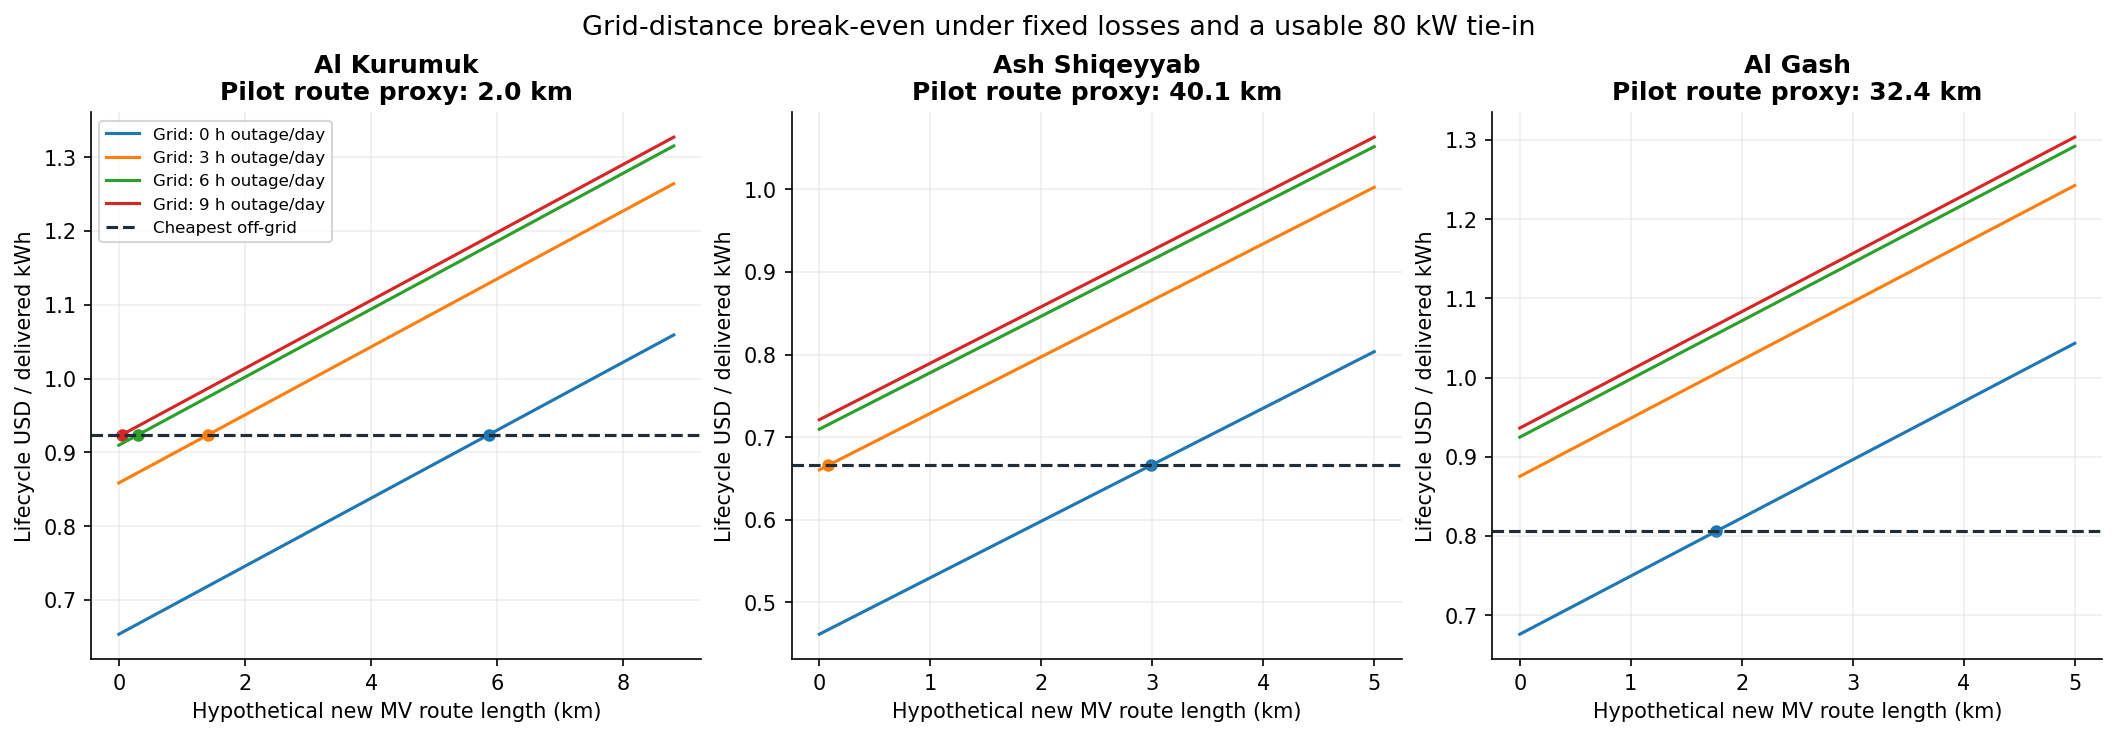

,source_name,geohash,outage_hours,best_offgrid,assumed_route_km,break_even_new_MV_route_km,status
0,Al Kurumuk,scbmu9pc3u,0,standalone,2.00,5.86,nonnegative_crossing
1,Al Kurumuk,scbmu9pc3u,3,standalone,2.00,1.42,nonnegative_crossing
2,Al Kurumuk,scbmu9pc3u,6,standalone,2.00,0.31,nonnegative_crossing
3,Al Kurumuk,scbmu9pc3u,9,standalone,2.00,0.05,nonnegative_crossing
4,Ash Shiqeyyab,sdxk3ns4zh,0,standalone,40.14,2.99,nonnegative_crossing
5,Ash Shiqeyyab,sdxk3ns4zh,3,standalone,40.14,0.08,nonnegative_crossing
6,Ash Shiqeyyab,sdxk3ns4zh,6,standalone,40.14,No nonnegative crossing,grid_more_expensive_even_at_zero_route
7,Ash Shiqeyyab,sdxk3ns4zh,9,standalone,40.14,No nonnegative crossing,grid_more_expensive_even_at_zero_route
8,Al Gash,sfcc38ee31,0,standalone,32.38,1.77,nonnegative_crossing
9,Al Gash,sfcc38ee31,3,standalone,32.38,No nonnegative crossing,grid_more_expensive_even_at_zero_route


In [19]:
display(Image(filename=str(UOUT/'route_break_even.png')))
route_thresholds=pd.read_csv(UOUT/'route_thresholds.csv')
display(route_thresholds[['source_name','geohash','outage_hours','best_offgrid','assumed_route_km',
                          'break_even_new_MV_route_km','status']].style.format({
                          'assumed_route_km':'{:.2f}','break_even_new_MV_route_km':'{:.2f}'},na_rep='No nonnegative crossing'))

### 8.4 Demand and outage crossing brackets

Demand thresholds compare **mini-grid versus standalone**, with all other assumptions central. Each observed sign change is refined with full-year optimization to a bracket at most 0.025 kWh per service point per day wide. This pairwise crossing does not establish that either option beats grid supply. “No sign change” refers only to the tested demand grid; no global uniqueness claim is made.

Outage brackets use the tested 0, 3, 6 and 9-hour schedules. We do not interpolate a precise fractional-hour reliability threshold from these points.

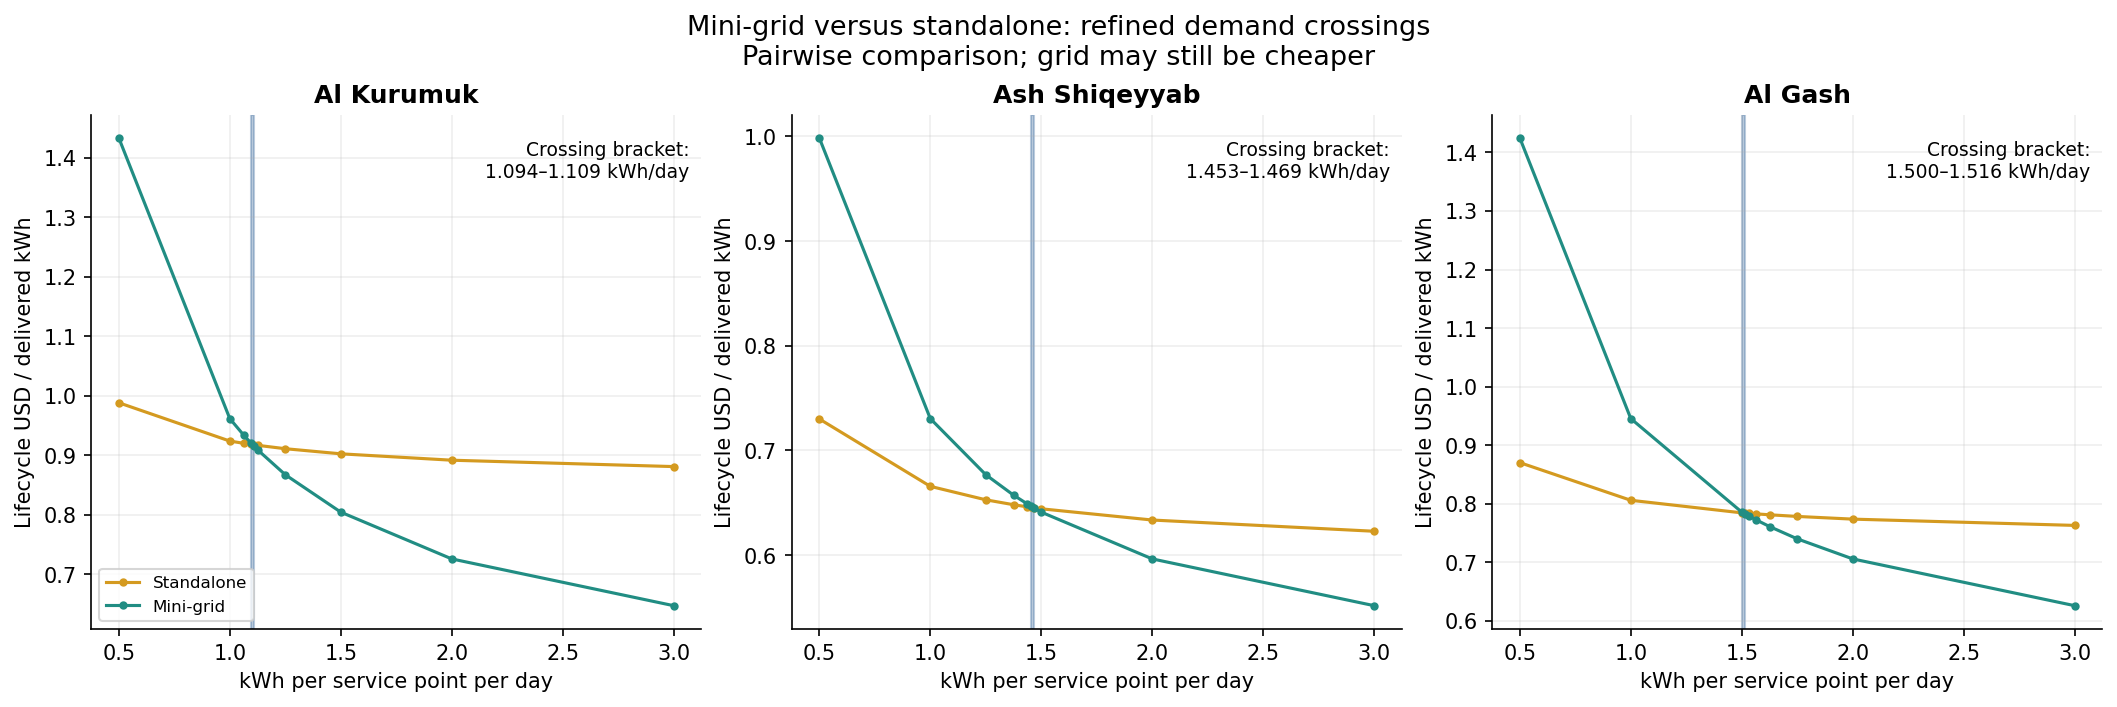

,geohash,source_name,lower_kWh_day,upper_kWh_day,lower_mini_minus_standalone_USD_kWh,upper_mini_minus_standalone_USD_kWh,status
0,scbmu9pc3u,Al Kurumuk,1.094,1.109,0.0029,-0.0024,sign_change_bracket
1,sdxk3ns4zh,Ash Shiqeyyab,1.453,1.469,0.0012,-0.0003,sign_change_bracket
2,sfcc38ee31,Al Gash,1.500,1.516,0.0012,-0.0016,sign_change_bracket


,geohash,lower_hours_per_day,upper_hours_per_day,status
0,scbmu9pc3u,0.0,3.0,crossing_between_tested_outage_schedules
1,sdxk3ns4zh,0.0,9.0,no_crossing_between_tested_schedules
2,sfcc38ee31,0.0,9.0,no_crossing_between_tested_schedules


In [20]:
demand_thresholds=pd.read_csv(UOUT/'demand_thresholds.csv')
outage_thresholds=pd.read_csv(UOUT/'outage_threshold_brackets.csv')
display(Image(filename=str(UOUT/'demand_break_even.png')))
display(demand_thresholds.style.format({'lower_kWh_day':'{:.3f}','upper_kWh_day':'{:.3f}',
      'lower_mini_minus_standalone_USD_kWh':'{:.4f}','upper_mini_minus_standalone_USD_kWh':'{:.4f}'}))
display(outage_thresholds)

### 8.5 Combined assumptions: stable choices and close alternatives

Eight corners combine daily demand (0.5 or 2 kWh/service point), lower/higher PV-and-battery equipment costs, and grid availability (0 or 6 hours of evening interruption). All other inputs remain central. Paired hardware costs are a deliberate bundle, not a measured correlation. Finance and fuel interactions are not covered by this joint design.

Each cell below shows the cost premium over the cheapest architecture in that scenario. All capacities are chosen again in each scenario: **this is an adaptive-capacity architecture comparison, not the regret of building one fixed system before uncertainty is revealed**. A fixed-design robustness study would require a different experiment.

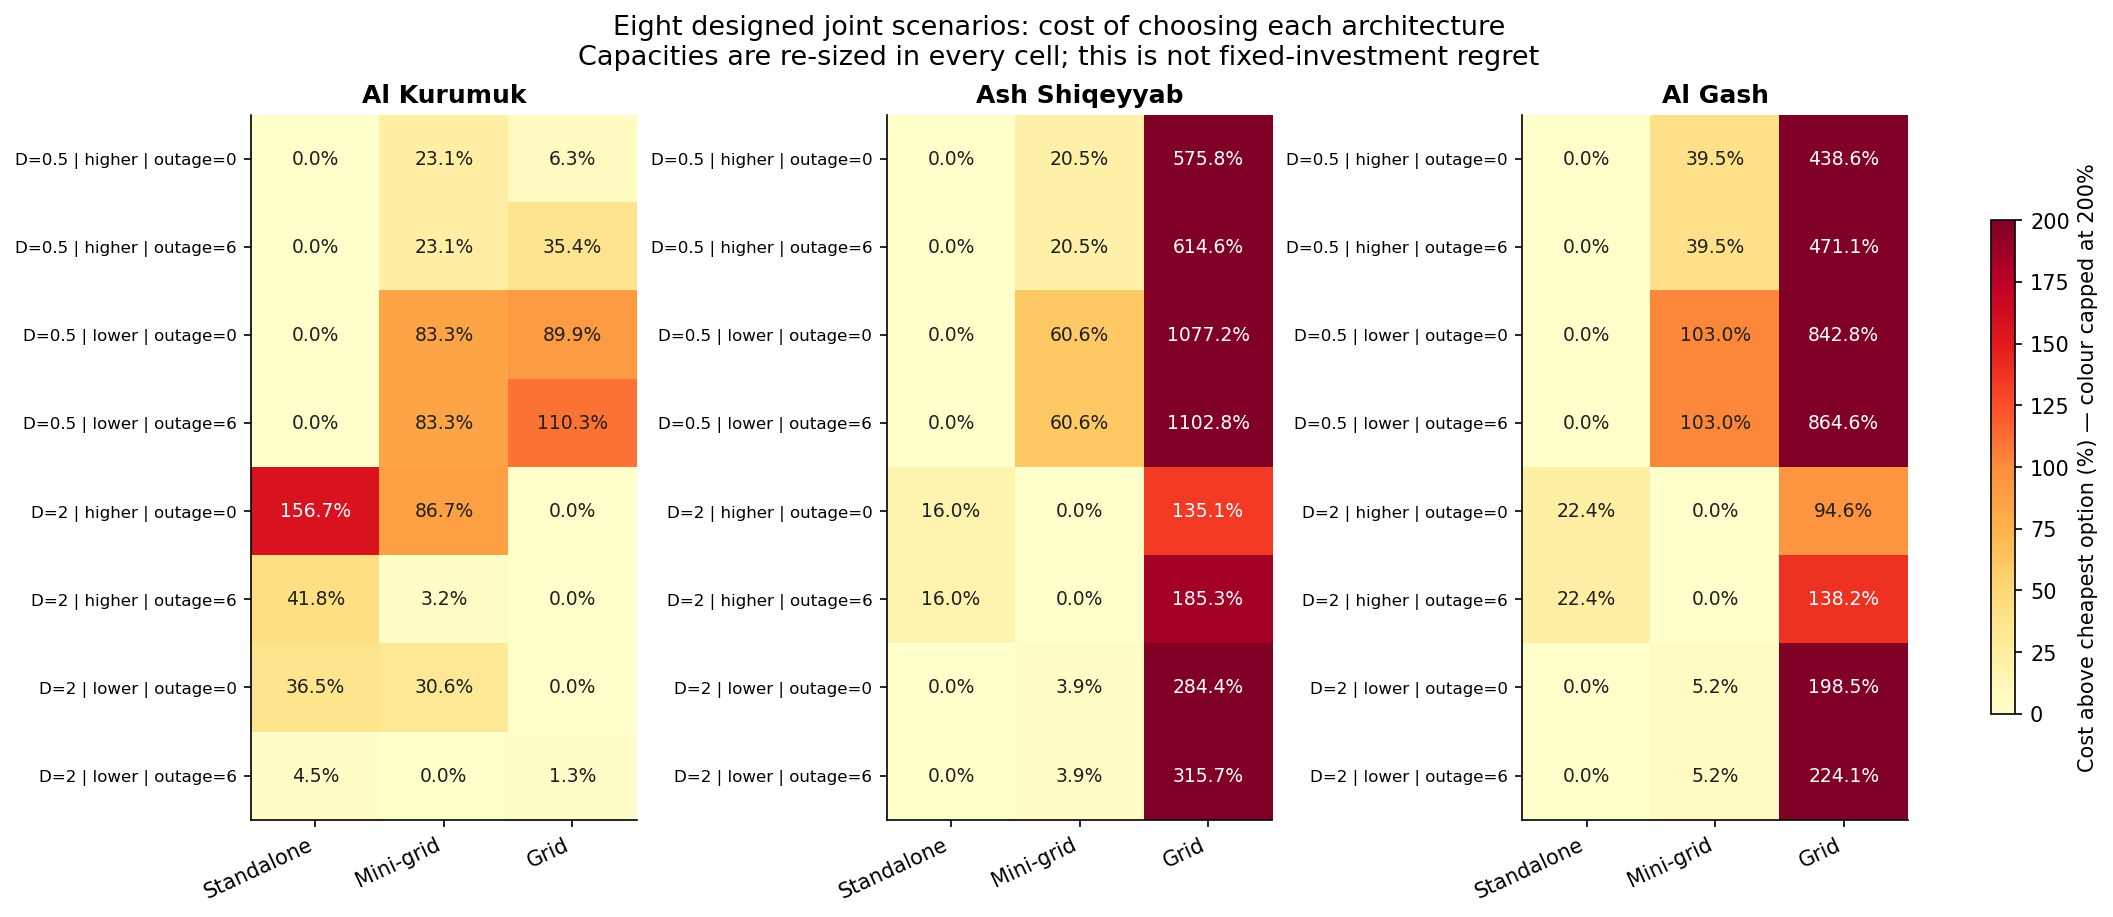

,source_name,mode,scenarios,strictly_cheapest_count,within_5_percent_count,min_USD_kWh,max_USD_kWh,max_adaptive_capacity_regret_percent
0,Al Kurumuk,standalone,8,4,5,0.605,1.264,156.7
1,Al Kurumuk,mini_grid,8,1,2,0.579,1.557,86.7
2,Al Kurumuk,grid_extension,8,3,4,0.443,1.713,110.3
3,Ash Shiqeyyab,standalone,8,6,6,0.435,0.928,16.0
4,Ash Shiqeyyab,mini_grid,8,2,4,0.452,1.119,60.6
5,Ash Shiqeyyab,grid_extension,8,0,0,1.674,6.633,1102.8
6,Al Gash,standalone,8,6,6,0.535,1.107,22.4
7,Al Gash,mini_grid,8,2,2,0.563,1.545,103.0
8,Al Gash,grid_extension,8,0,0,1.596,6.325,864.6


**Interpretation:** “6 of 8 cases” is a scenario count, not a 75% probability. “Within 5%” is an explicitly chosen near-tie criterion. Min/max costs are ranges over these scenarios, not confidence intervals.

In [21]:
display(Image(filename=str(UOUT/'joint_scenario_regret.png')))
robustness=uncertainty_views['robustness']
display(robustness[['source_name','mode','scenarios','strictly_cheapest_count','within_5_percent_count',
                    'min_USD_kWh','max_USD_kWh','max_adaptive_capacity_regret_percent']].style.format({
                    'min_USD_kWh':'{:.3f}','max_USD_kWh':'{:.3f}','max_adaptive_capacity_regret_percent':'{:.1f}'}))
display(Markdown('**Interpretation:** “6 of 8 cases” is a scenario count, not a 75% probability. “Within 5%” is an explicitly chosen near-tie criterion. Min/max costs are ranges over these scenarios, not confidence intervals.'))

### 8.6 Findings generated from this run

In [22]:
findings=[]
for sid,g in robustness.groupby('geohash',sort=False):
    text=', '.join(f"{OPTION_LABELS[r['mode']]} cheapest in {int(r.strictly_cheapest_count)}/8 cases" for _,r in g.iterrows())
    findings.append(f"- **{g.source_name.iloc[0]} [{sid}]:** {text}.")
for r in demand_thresholds.query("status=='sign_change_bracket'").itertuples(index=False):
    findings.append(f"- **Demand crossing, {r.source_name}:** mini-grid and standalone exchange cost order between **{r.lower_kWh_day:.3f} and {r.upper_kWh_day:.3f} kWh/service point/day**, conditional on central prices and the assumed load shape.")
near_id=sites.query("pilot_type=='near_grid'").iloc[0].geohash
nr=route_thresholds[(route_thresholds.geohash==near_id)&(route_thresholds.outage_hours==0)].iloc[0]
if pd.notna(nr.break_even_new_MV_route_km):
    findings.append(f"- **Near-grid route threshold:** with continuous upstream service, the grid/off-grid crossing is **{nr.break_even_new_MV_route_km:.2f} route km**, compared with a current unsurveyed proxy of **{nr.assumed_route_km:.2f} km**.")
display(Markdown('\n'.join(findings)))

- **Al Kurumuk [scbmu9pc3u]:** Standalone cheapest in 4/8 cases, Mini-grid cheapest in 1/8 cases, Grid + local supply cheapest in 3/8 cases.
- **Ash Shiqeyyab [sdxk3ns4zh]:** Standalone cheapest in 6/8 cases, Mini-grid cheapest in 2/8 cases, Grid + local supply cheapest in 0/8 cases.
- **Al Gash [sfcc38ee31]:** Standalone cheapest in 6/8 cases, Mini-grid cheapest in 2/8 cases, Grid + local supply cheapest in 0/8 cases.
- **Demand crossing, Al Kurumuk:** mini-grid and standalone exchange cost order between **1.094 and 1.109 kWh/service point/day**, conditional on central prices and the assumed load shape.
- **Demand crossing, Ash Shiqeyyab:** mini-grid and standalone exchange cost order between **1.453 and 1.469 kWh/service point/day**, conditional on central prices and the assumed load shape.
- **Demand crossing, Al Gash:** mini-grid and standalone exchange cost order between **1.500 and 1.516 kWh/service point/day**, conditional on central prices and the assumed load shape.
- **Near-grid route threshold:** with continuous upstream service, the grid/off-grid crossing is **5.86 route km**, compared with a current unsurveyed proxy of **2.00 km**.

### 8.7 What evidence to collect next

Use the sensitivity results to target validation:

1. **Demand:** verify service points and household/business/clinic loads, particularly near the demand crossing brackets. A building count and a repeated evening profile remain proxies.
2. **Grid feasibility and reliability:** establish a usable tie-in, its capacity and outage record, and a buildable route. Compare route evidence against the conditional thresholds rather than atlas proximity alone.
3. **Comparable procurement:** obtain mini-grid and standalone quotations with the same service, equipment, delivery, installation and replacement scope. Test the standalone purchasing premium explicitly.
4. **Storage and finance:** validate battery lifetime, temperature exposure, replacement access and financing terms. Battery price was varied here; its lifetime remains eight years.

Then test selected fixed designs against multiple weather years, demand shapes and unplanned equipment/fuel outages, and expand to a justified settlement sample. Shared feeder decisions and upstream constraints are required before interpreting a settlement map as a national least-cost plan.

**What is checked:** complete hourly inputs; equal service; AC and chronological battery balances; operating/capacity/SOC limits; outage and fuel restrictions; reconstructed capital and lifecycle costs; monotonicity under tighter supply or higher costs; and threshold arithmetic. Passing these checks does not validate the field assumptions.

In [23]:
display(pd.DataFrame([uncertainty_validation]))
display(Markdown('Experiment inputs and interpretation: [uncertainty input guide](../../data/electrification_uncertainty/README.md). Complete outputs: `results/uncertainty/`. Run `python research/system_costs/uncertainty_model.py` and `python research/system_costs/check_uncertainty.py` from the project root. Normal reading/rerunning uses verified cached solutions; input changes trigger re-optimization.'))

,passed,unique_hourly_cases,fresh_solves,checked_case_hours,one_at_a_time_comparisons,joint_option_comparisons,equal_service,lifecycle_costs_reconstructed,scenario_probabilities_assigned,field_validated,any_artificial_design_bound_binding
0,True,201,192,1760760,288,72,True,True,False,False,False


Experiment inputs and interpretation: [uncertainty input guide](../../data/electrification_uncertainty/README.md). Complete outputs: `results/uncertainty/`. Run `python research/system_costs/uncertainty_model.py` and `python research/system_costs/check_uncertainty.py` from the project root. Normal reading/rerunning uses verified cached solutions; input changes trigger re-optimization.

<a id="spatial-proxy-study"></a>
## 9. Continue with available data: a state-spanning proxy-demand study

**We can study electrification choices without a measured settlement-demand series.** This section uses the public atlas's building-demand estimate as one explicit scenario, then tests two chosen recovery-service levels. Missing measured demand is a model limitation, not a prerequisite for running this stage.

The study selects **18 actual atlas clusters, one in each state represented in the source**, before looking at costs. It obtains each selected location's complete 2022 NASA POWER hourly weather, sizes supply options and compares equal delivered service. The sample adds geographical breadth to sections 7–8; it is not a statistically representative national sample.

**What this answers:** how local supply choices change across these source locations and assumed service levels. **What it does not establish:** the cheapest technology for an entire state, a national investment budget, current electrification status or a forecast of observed post-war demand.

In [24]:
from spatial_proxy_model import run as run_spatial_proxy, DATA as SPATIAL_DATA, OUT as SPATIAL_OUT, DESIGN as SPATIAL_DESIGN
from check_spatial_proxy import check as check_spatial_proxy
from spatial_proxy_analysis import analyse as analyse_spatial_proxy
spatial_results = run_spatial_proxy()  # Offline checked caches; changed inputs trigger new solves.
spatial_validation = check_spatial_proxy()
spatial_views = analyse_spatial_proxy()
spatial_sites = pd.read_csv(SPATIAL_DATA/'sites.csv')
spatial_coverage = pd.read_csv(SPATIAL_DATA/'coverage.csv')
spatial_selection = json.loads((SPATIAL_DATA/'selection_manifest.json').read_text())
display(Markdown(f"**Coverage:** {spatial_selection['selected_clusters']} selected clusters from {spatial_selection['eligible_clusters']:,} eligible clusters in an atlas of {spatial_selection['atlas_clusters']:,}. The model solved **{spatial_validation['unique_hourly_cases']} distinct full-year cases**, covering **{spatial_validation['checked_case_hours']:,} case-hours**. Only the selected points receive technology comparisons."))
display(spatial_sites[['sample_id','admin_cgaz_1','geohash','num_connections','demand',
                      'atlas_daily_kWh_per_connection','distance_to_existing_transmission_lines','grid_in_local_scope']]
       .rename(columns={'admin_cgaz_1':'Source state','num_connections':'Potential connections',
                        'demand':'Atlas proxy kWh/day','grid_in_local_scope':'Grid assessed conditionally'})
       .style.format({'atlas_daily_kWh_per_connection':'{:.3f}','distance_to_existing_transmission_lines':'{:.2f}'}))

{"passed": true, "selected_clusters": 18, "states": 18, "unique_hourly_cases": 168, "checked_case_hours": 1471680, "grid_assessed_clusters": 10, "grid_not_assessed_clusters": 8, "atlas_formula_reconstructed": true, "full_atlas_selection_rechecked": true, "equal_service": true, "lifecycle_costs_reconstructed": true, "measured_settlement_demand_used": false, "national_extrapolation": false, "field_validated": false}


**Coverage:** 18 selected clusters from 6,843 eligible clusters in an atlas of 33,891. The model solved **168 distinct full-year cases**, covering **1,471,680 case-hours**. Only the selected points receive technology comparisons.

,sample_id,Source state,geohash,Potential connections,Atlas proxy kWh/day,atlas_daily_kWh_per_connection,distance_to_existing_transmission_lines,Grid assessed conditionally
0,1,Blue Nile,sf08v5b9z9,124,41.500000,0.335,17.84,True
1,2,Central Darfur,sd2g41z66t,118,39.500000,0.335,670.14,False
2,3,East Darfur,sd42qskjwv,108,36.200000,0.335,439.32,False
3,4,Gedaref,sf2q2xxtwf,146,48.900000,0.335,34.61,True
4,5,Gezira,sdxeb9y0b3,147,49.200000,0.335,18.97,True
5,6,Kassala,sf9rmy5yz7,146,49.200000,0.337,19.32,True
6,7,Khartoum,sdzht8b78s,120,40.200000,0.335,12.45,True
7,8,North Darfur,sd9b707rxx,117,39.200000,0.335,537.69,False
8,9,North Kordofan,sdmmwej5x4,133,44.600000,0.335,56.84,False
9,10,Northern,semwk8ych9,105,37.700000,0.359,9.77,True


### 9.1 Sampling and demand assumptions

Eligible records have 80–250 potential connections, positive area/demand/solar resource, building density between 0% and 25%, a state label and no detected source nightlight. Placeholder place names are retained; geohashes identify the sites. Within each state, choose the actual record nearest the median feature profile for building count, area, line distance and solar yield. Count, area and distance are transformed with `log1p`; features are divided by their within-state interquartile range and squared deviations are summed. Ties are broken by geohash. Selection does not use costs or model outcomes.

This deliberately restricts the study to comparable small clusters. It excludes many large towns and small settlements; a chosen site does not represent all communities in its state. No nightlight is not proof of no electricity. Source nightlights span September 2022–August 2023, and source buildings/labels have mixed dates.

| Demand case | Daily energy | How to interpret it |
|---|---|---|
| **Atlas proxy** | Source formula: 1.1 × large + 0.65 × medium + 0.335 × small buildings, kWh/day; retain published rounding | Building-based low-service estimate, not metered demand |
| **Recovery 1** | 1 kWh per potential connection per day | Chosen service target; not a forecast |
| **Recovery 2** | 2 kWh per potential connection per day | Higher-service target; not an estimate of unmet demand |

All cases use the pilot's same assumed hourly shape. Building counts are potential service points, not verified customer accounts. The source formula is independently reconstructed, and every supply option receives exactly the same delivered energy and hourly shape within a demand case. Higher-service scenarios are separate steady-state systems; they do not model a gradual investment or demand-growth trajectory.

The **2022 weather year is a common resource reference**, combined with the 2025-release mixed-vintage settlement atlas. These inputs do not constitute an observed 2022 settlement electricity system.

### 9.2 Grid-assessment scope

The source gives straight-line distance to mixed/unknown-voltage line geography. It does not identify a functioning tie-in. We conditionally evaluate the pilot's grid option only where that distance is **50 km or less**. This is an analyst scope screen, **not an engineering feasibility limit**. Within that screen we retain the unsurveyed route multiplier, fixed 80 kW tie-in and constant losses; long feeders still need a different engineering model.

For the other sites, grid is **not assessed**. Their displayed choice is only between standalone and mini-grid; shared transmission expansion, reconstruction of local grids or a different connection point could change it. No infinite grid cost or claim of grid infeasibility is assigned.

Where grid is considered, compare continuous upstream availability with the existing synthetic six-hour evening outage. Standalone and mini-grid results do not change when the upstream grid scenario changes, so the same checked solutions are reused. The mini-grid retains its 20% annual delivered-energy diesel cap.

All equipment prices and finance assumptions remain central and spatially uniform. The preceding uncertainty section tests their sensitivity. PV is still a horizontal-array approximation; distribution losses, wiring and route lengths remain the documented pilot proxies. Current damage and security conditions are not inferred from atlas conflict categories.

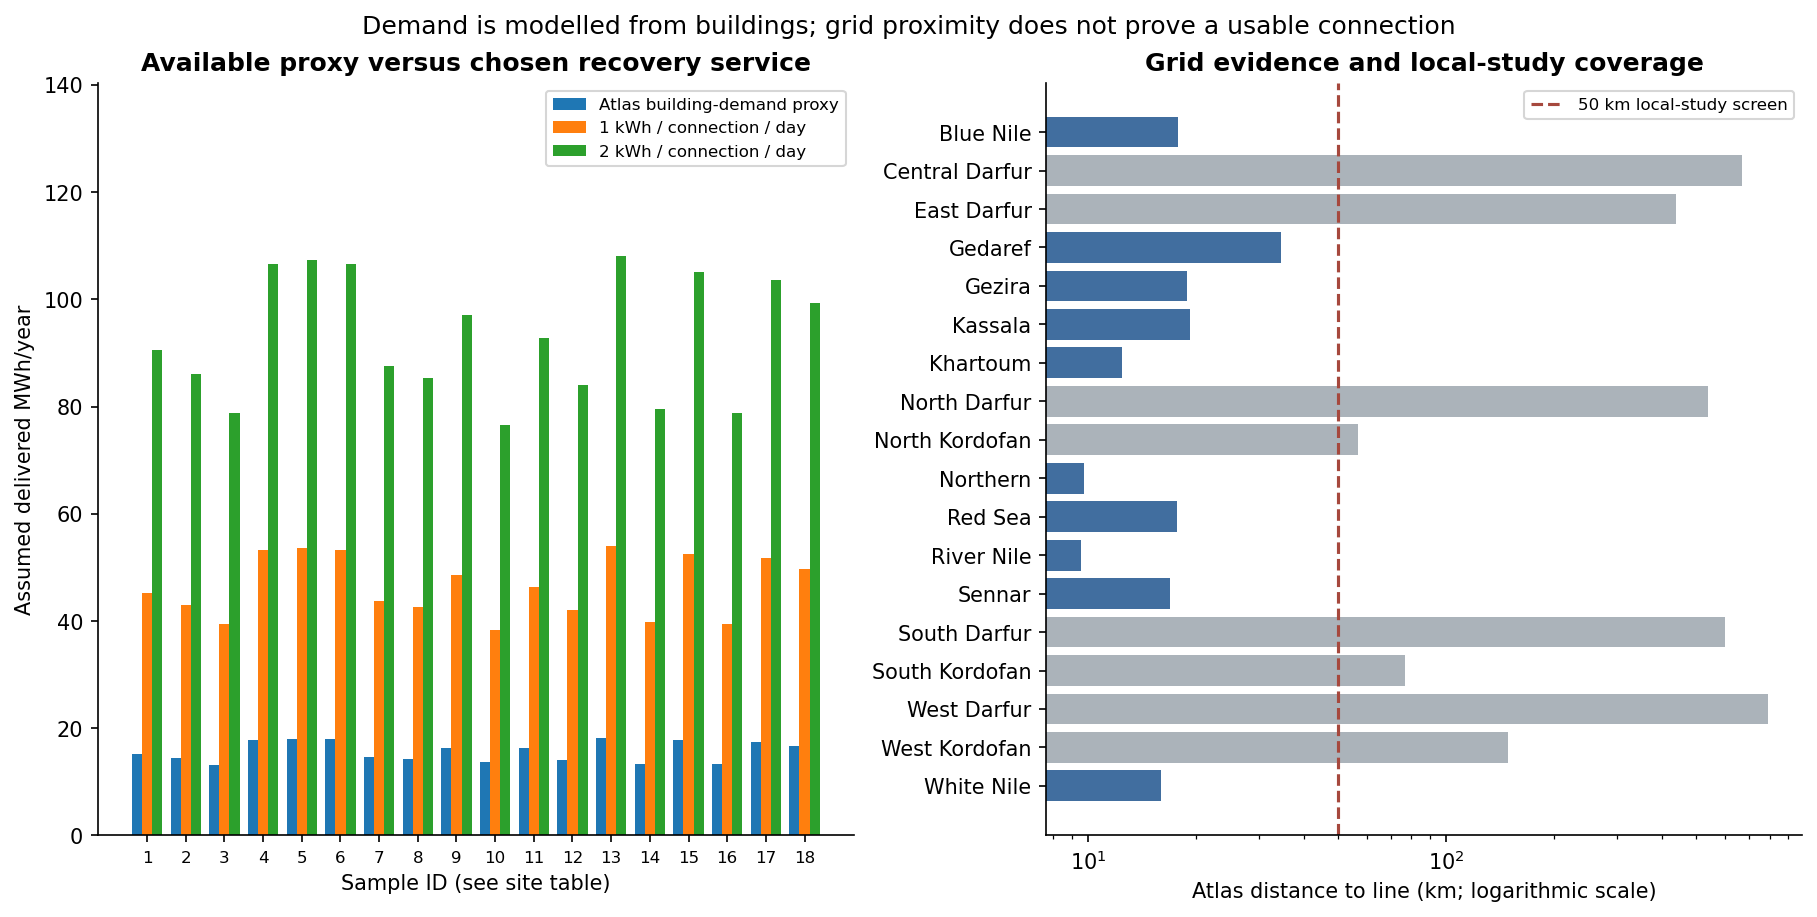

,state,atlas_clusters,eligible_clusters,selected_clusters,selected_geohash,grid_in_local_scope,eligible_median_grid_distance_km
0,Blue Nile,542,107,1,sf08v5b9z9,True,17.800
1,Central Darfur,951,243,1,sd2g41z66t,False,628.210
2,East Darfur,1981,338,1,sd42qskjwv,False,436.655
3,Gedaref,835,145,1,sf2q2xxtwf,True,34.930
4,Gezira,2842,506,1,sdxeb9y0b3,True,16.590
5,Kassala,1231,252,1,sf9rmy5yz7,True,21.265
6,Khartoum,1818,271,1,sdzht8b78s,True,13.520
7,North Darfur,3078,784,1,sd9b707rxx,False,551.415
8,North Kordofan,4017,1017,1,sdmmwej5x4,False,57.140
9,Northern,1345,137,1,semwk8ych9,True,8.990


In [25]:
display(Image(filename=str(SPATIAL_OUT/'proxy_demand_and_grid_scope.png')))
display(spatial_coverage)

### 9.3 Spatial results at selected clusters

Colour denotes the cheapest **assessed** option. Circles include a conditional grid alternative; triangles compare only the two off-grid options. Numbers match the site table. Grey dots locate the full atlas for context; they are neither administrative boundaries nor locations with calculated supply choices. State polygons are intentionally not coloured from a single sample.

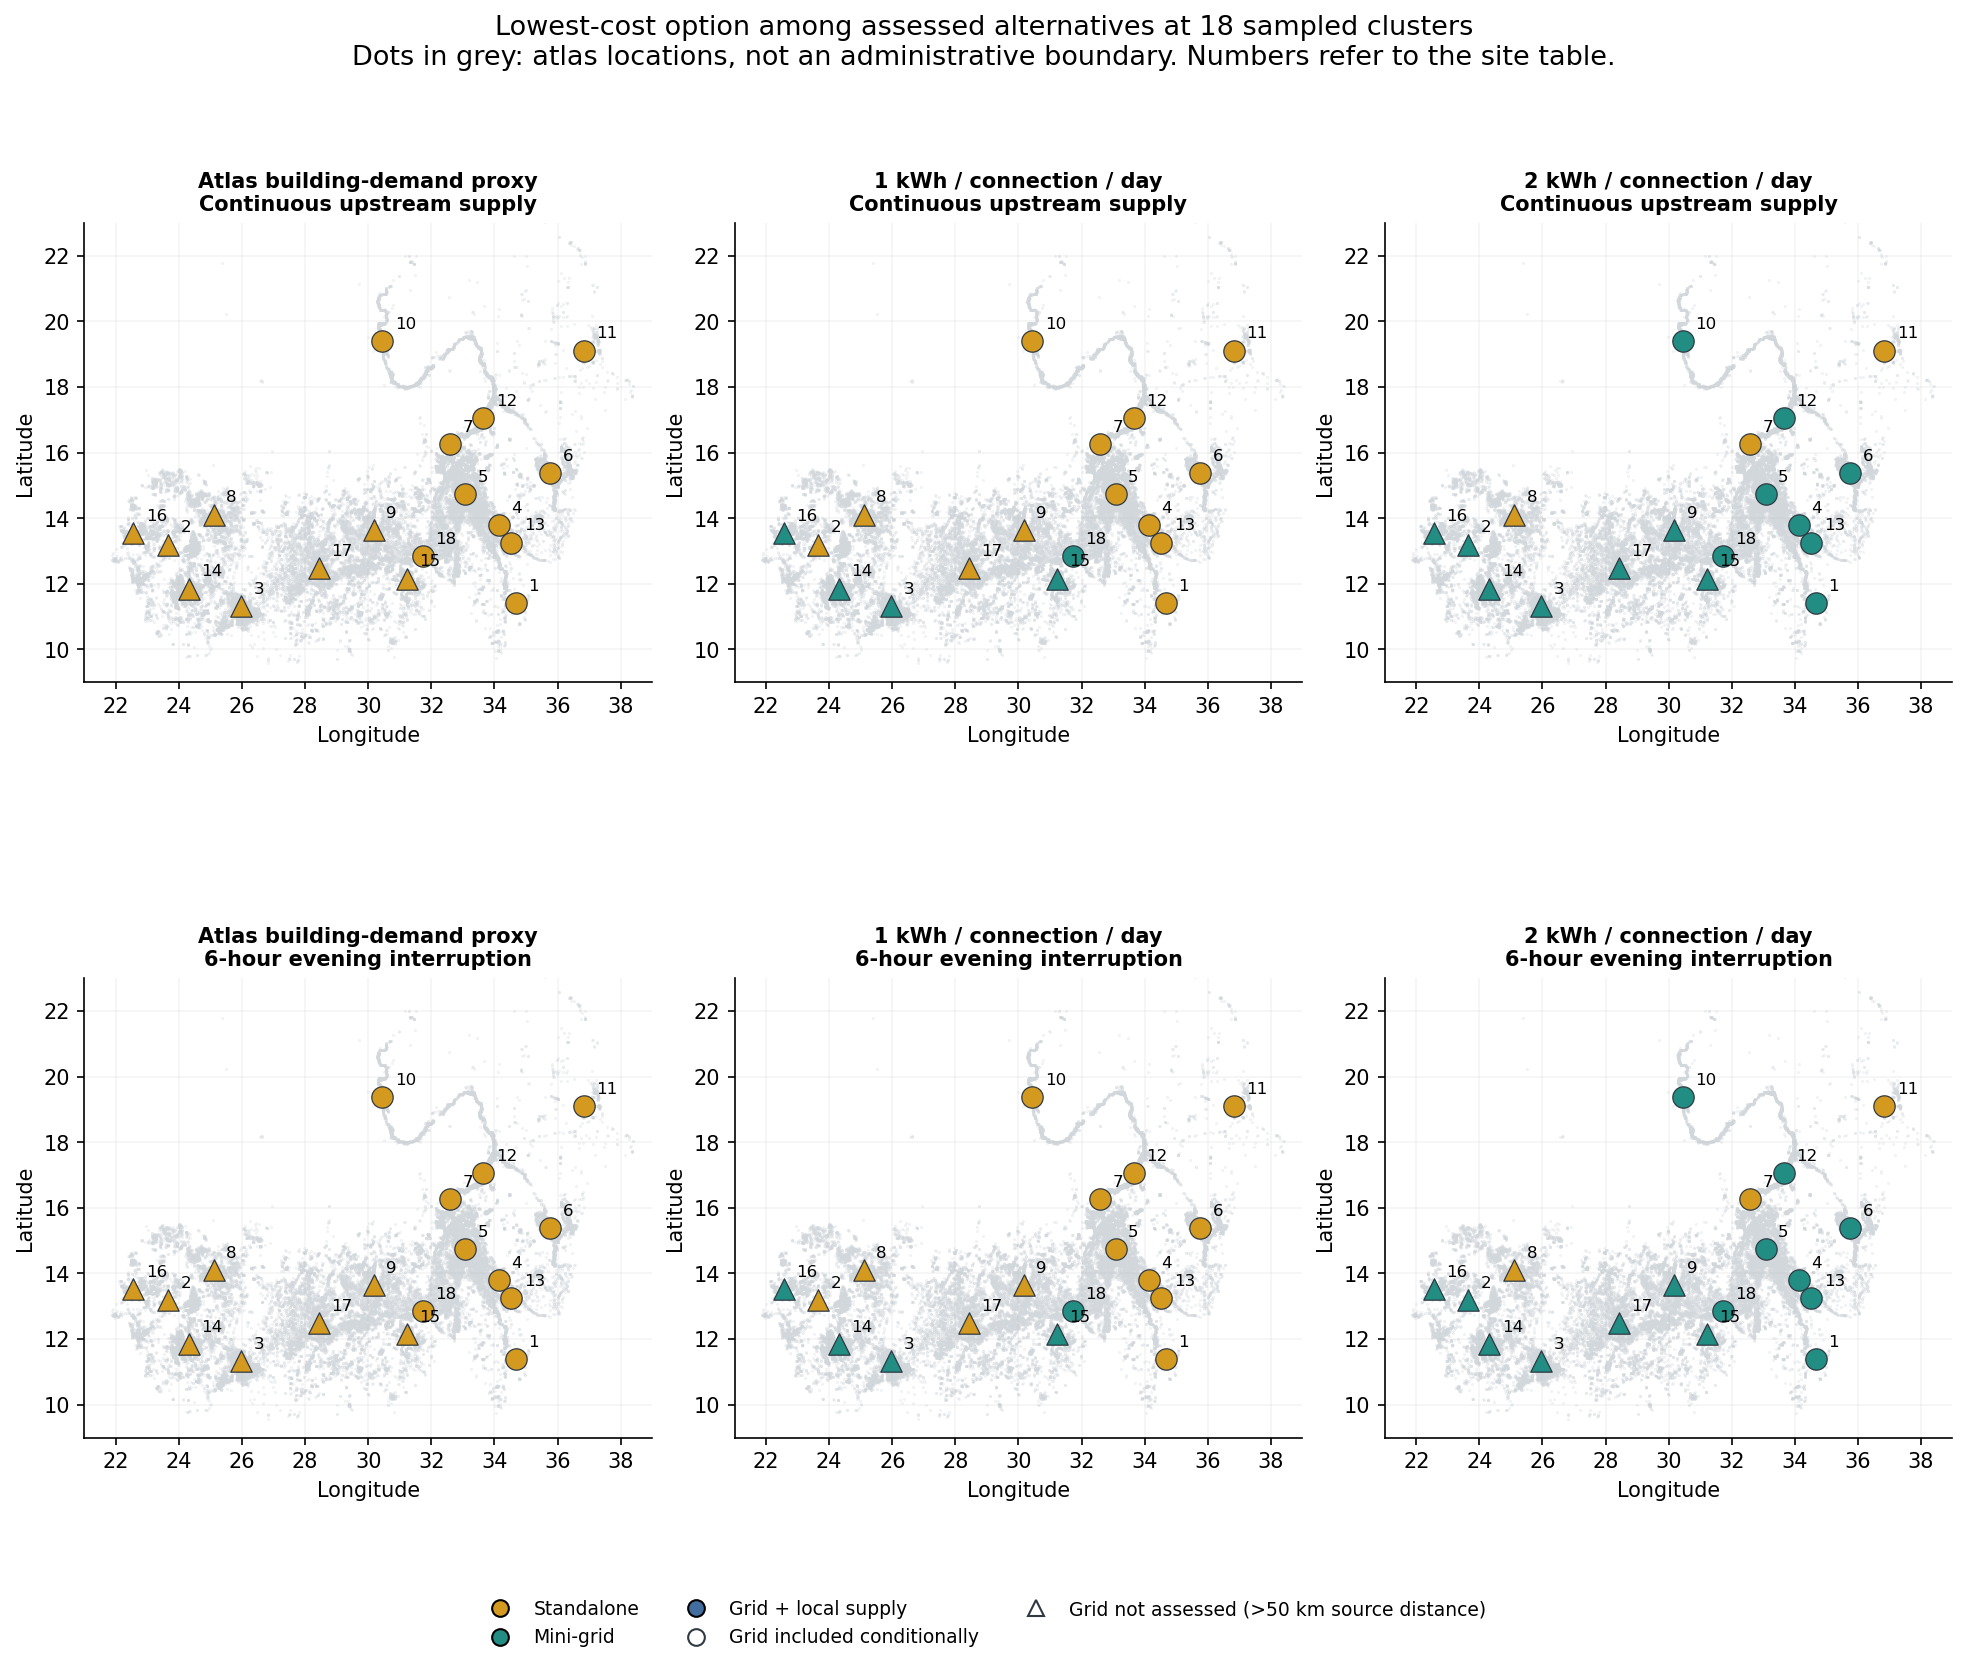

In [26]:
display(Image(filename=str(SPATIAL_OUT/'spatial_choices.png')))

### 9.4 Demand can change the architecture

Each cell reports lifecycle cost per delivered kWh for the cheapest assessed option, with its architecture shown by colour. These are full hourly-feasible model solutions under the stated assumptions. State names below identify where the sampled cluster lies, not a recommended state-wide technology.

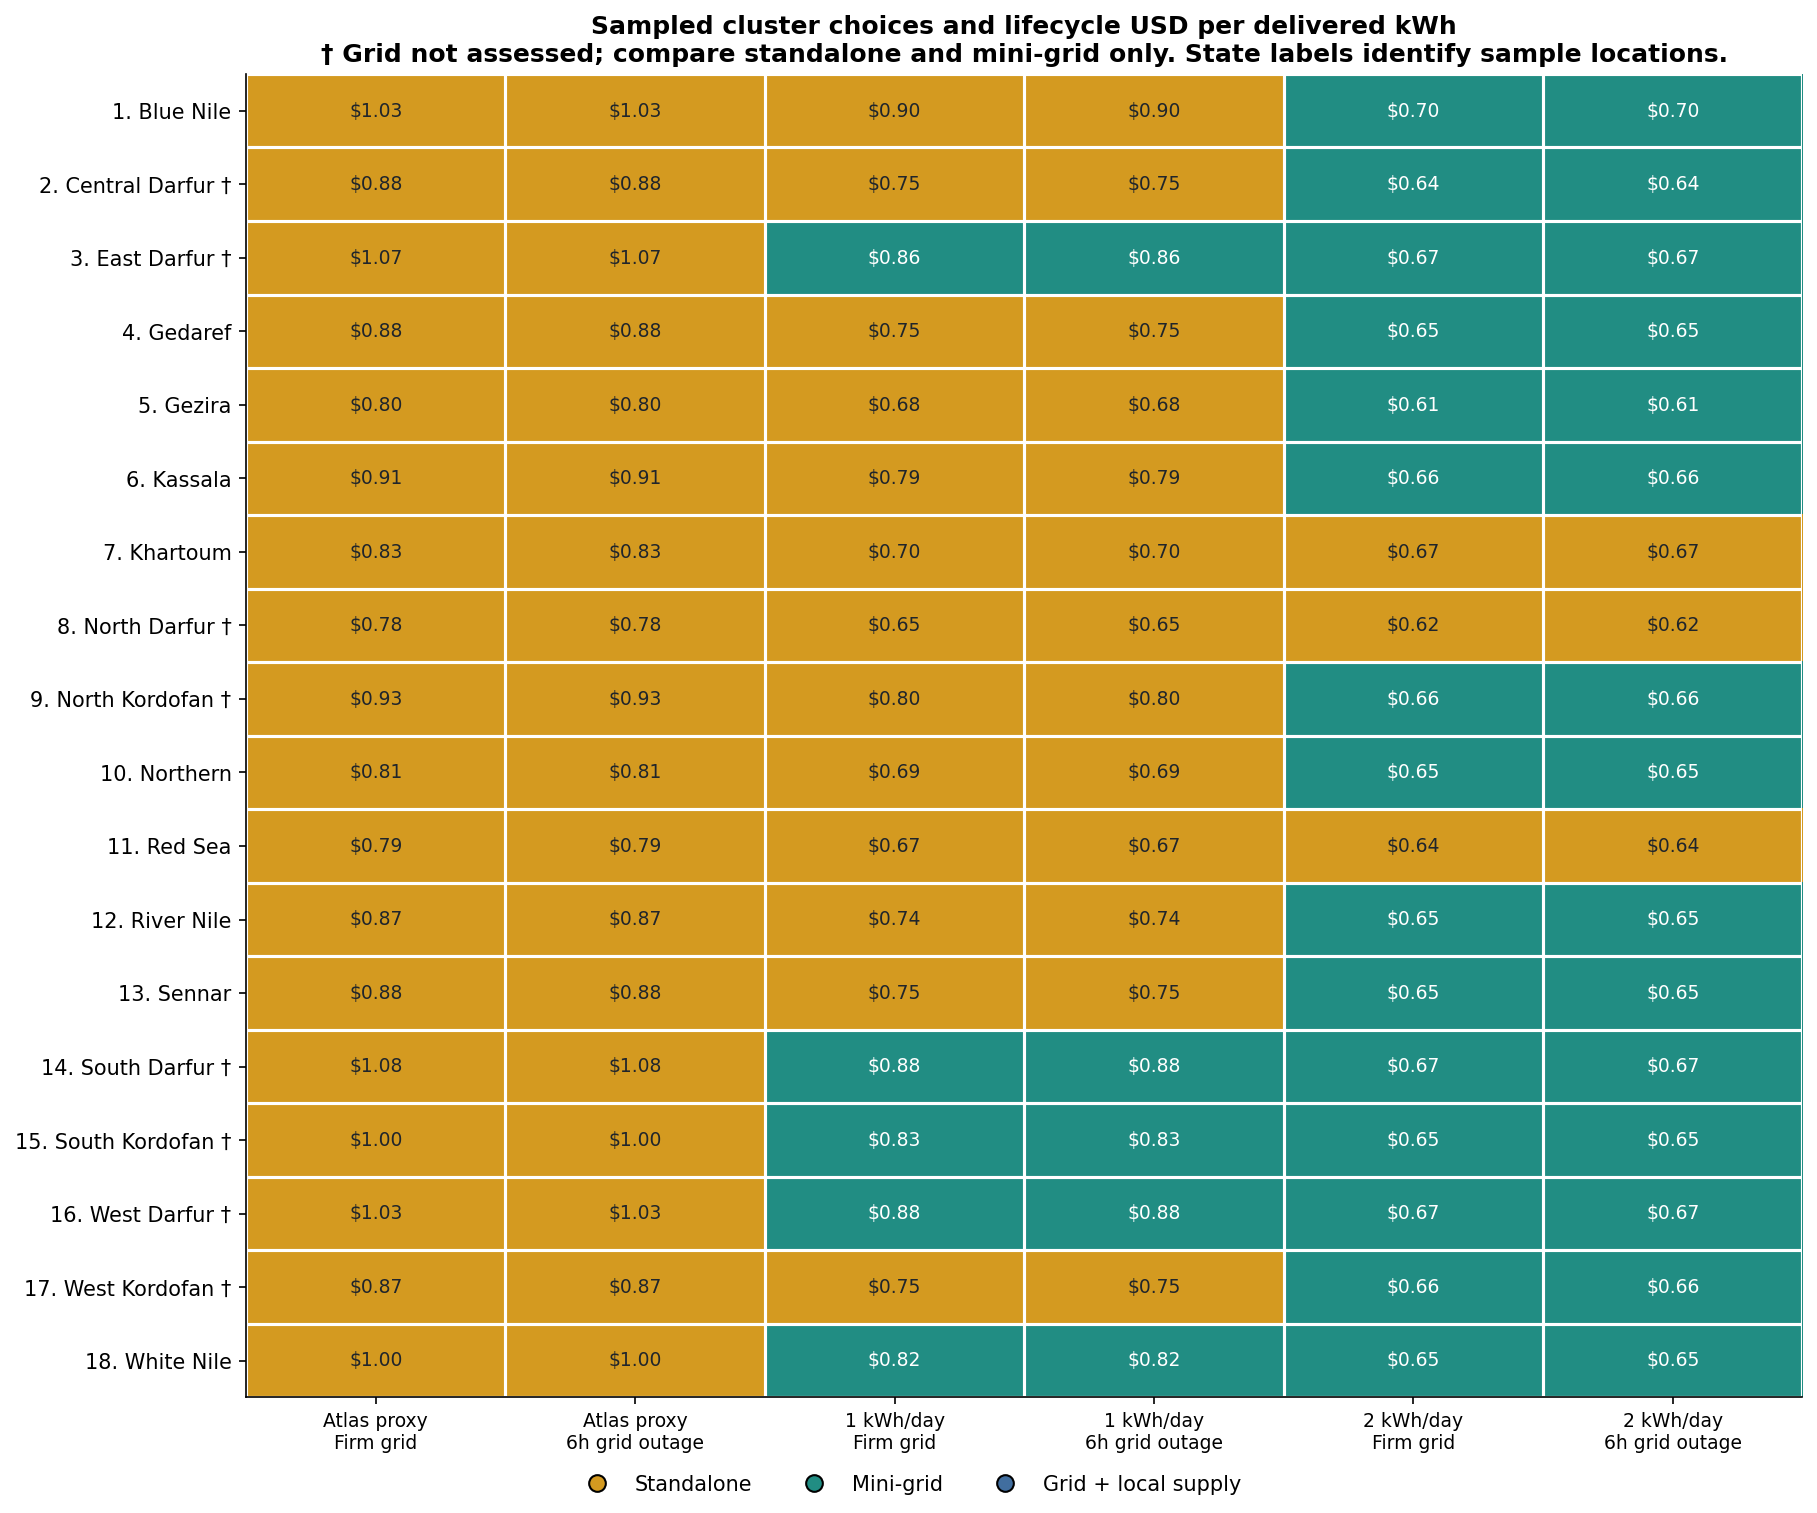

,demand_case,grid_case,grid_assessment,winner_among_assessed_options,sampled_clusters
0,atlas_proxy,continuous,conditional_local_candidate,standalone,10
1,atlas_proxy,continuous,not_assessed_outside_local_distance_scope,standalone,8
2,atlas_proxy,evening_interruption,conditional_local_candidate,standalone,10
3,atlas_proxy,evening_interruption,not_assessed_outside_local_distance_scope,standalone,8
4,recovery_1,continuous,conditional_local_candidate,mini_grid,1
5,recovery_1,continuous,conditional_local_candidate,standalone,9
6,recovery_1,continuous,not_assessed_outside_local_distance_scope,mini_grid,4
7,recovery_1,continuous,not_assessed_outside_local_distance_scope,standalone,4
8,recovery_1,evening_interruption,conditional_local_candidate,mini_grid,1
9,recovery_1,evening_interruption,conditional_local_candidate,standalone,9


,geohash,state,grid_case,atlas_proxy_choice,recovery_2_choice,choice_changes,grid_assessed
0,sd173jy9kq,South Darfur,continuous,standalone,mini_grid,True,False
1,sd173jy9kq,South Darfur,evening_interruption,standalone,mini_grid,True,False
2,sd2g41z66t,Central Darfur,continuous,standalone,mini_grid,True,False
3,sd2g41z66t,Central Darfur,evening_interruption,standalone,mini_grid,True,False
4,sd2j10mehv,West Darfur,continuous,standalone,mini_grid,True,False
5,sd2j10mehv,West Darfur,evening_interruption,standalone,mini_grid,True,False
6,sd42qskjwv,East Darfur,continuous,standalone,mini_grid,True,False
7,sd42qskjwv,East Darfur,evening_interruption,standalone,mini_grid,True,False
10,sdhpnc53gy,West Kordofan,continuous,standalone,mini_grid,True,False
11,sdhpnc53gy,West Kordofan,evening_interruption,standalone,mini_grid,True,False


Counts describe these 18 selected sites only. They are not probabilities, population shares, national technology shares or estimates of access gains. The two grid scenarios duplicate off-grid results where grid is not assessed.

In [27]:
display(Image(filename=str(SPATIAL_OUT/'state_sample_comparison.png')))
choices=spatial_views['choices']
display(spatial_views['counts'])
display(spatial_views['changes'].query("choice_changes"))
display(Markdown('Counts describe these 18 selected sites only. They are not probabilities, population shares, national technology shares or estimates of access gains. The two grid scenarios duplicate off-grid results where grid is not assessed.'))

### 9.5 Costs, capacities and close alternatives

The table below shows the higher-service case with continuous grid availability where assessed. Near ties identify sites where an alternative costs within 5% of the cheapest. Full capacities, dispatch and all other scenarios are retained in the result tables.

In [28]:
display(choices.query("demand_case=='recovery_2' and grid_case=='continuous'")[
    ['state','geohash','grid_assessment','winner_among_assessed_options','lowest_USD_kWh','runner_up_premium_percent',
     'within_5_percent','pv_kWp','battery_nominal_kWh','diesel_kW','initial_budget_USD']]
    .style.format({'lowest_USD_kWh':'{:.3f}','runner_up_premium_percent':'{:.1f}',
                  'pv_kWp':'{:.1f}','battery_nominal_kWh':'{:.1f}','diesel_kW':'{:.1f}','initial_budget_USD':'{:,.0f}'}))
display(spatial_views['totals'][['demand_case','grid_case','sampled_clusters','sample_connections',
       'sample_annual_delivered_MWh','sample_initial_budget_USD','sample_weighted_USD_kWh']]
       .style.format({'sample_annual_delivered_MWh':'{:,.1f}','sample_initial_budget_USD':'{:,.0f}','sample_weighted_USD_kWh':'{:.3f}'}))
display(Markdown('**Sample totals only:** these sums cover the 18 independent modelled clusters. They are not a Sudan budget and do not include shared feeders, regional reinforcement or population weighting.'))

,state,geohash,grid_assessment,winner_among_assessed_options,lowest_USD_kWh,runner_up_premium_percent,within_5_percent,pv_kWp,battery_nominal_kWh,diesel_kW,initial_budget_USD
4,Blue Nile,sf08v5b9z9,conditional_local_candidate,mini_grid,0.696,24.5,mini_grid,70.0,222.0,6.3,"337,213"
10,Central Darfur,sd2g41z66t,not_assessed_outside_local_distance_scope,mini_grid,0.644,12.2,mini_grid,59.2,211.4,5.0,"296,991"
16,East Darfur,sd42qskjwv,not_assessed_outside_local_distance_scope,mini_grid,0.667,36.9,mini_grid,55.1,193.1,5.8,"280,237"
22,Gedaref,sf2q2xxtwf,conditional_local_candidate,mini_grid,0.649,10.6,mini_grid,77.8,265.3,6.1,"371,928"
28,Gezira,sdxeb9y0b3,conditional_local_candidate,mini_grid,0.613,5.1,mini_grid,76.0,268.2,4.3,"350,854"
34,Kassala,sf9rmy5yz7,conditional_local_candidate,mini_grid,0.656,15.1,mini_grid,74.6,263.7,6.6,"379,710"
40,Khartoum,sdzht8b78s,conditional_local_candidate,standalone,0.667,0.4,standalone; mini_grid,120.1,217.6,0.0,"340,949"
46,North Darfur,sd9b707rxx,not_assessed_outside_local_distance_scope,standalone,0.616,7.2,standalone,84.4,219.3,0.0,"298,508"
52,North Kordofan,sdmmwej5x4,not_assessed_outside_local_distance_scope,mini_grid,0.656,17.3,mini_grid,65.4,239.5,6.3,"342,181"
58,Northern,semwk8ych9,conditional_local_candidate,mini_grid,0.651,1.2,mini_grid; standalone,52.7,187.0,3.6,"270,273"


,demand_case,grid_case,sampled_clusters,sample_connections,sample_annual_delivered_MWh,sample_initial_budget_USD,sample_weighted_USD_kWh
0,atlas_proxy,continuous,18,2293,282.5,"1,476,690",0.910
1,atlas_proxy,evening_interruption,18,2293,282.5,"1,476,690",0.910
2,recovery_1,continuous,18,2293,836.9,"3,692,661",0.770
3,recovery_1,evening_interruption,18,2293,836.9,"3,692,661",0.770
4,recovery_2,continuous,18,2293,"1,673.9","5,917,929",0.652
5,recovery_2,evening_interruption,18,2293,"1,673.9","5,917,929",0.652


**Sample totals only:** these sums cover the 18 independent modelled clusters. They are not a Sudan budget and do not include shared feeders, regional reinforcement or population weighting.

### 9.6 What we can conclude using available evidence

In [29]:
findings=spatial_views['findings']
lines=[f"- The selected sites contain **{findings['sample_connections']:,} potential connections**. Grid was considered conditionally at **{findings['grid_conditionally_assessed']} sites** and not assessed at **{findings['grid_not_assessed']}**."]
for scenario,count in findings['demand_case_changes'].items():
    lines.append(f"- Moving from atlas-proxy demand to 2 kWh/connection/day changes the cheapest assessed architecture at **{count} of 18 sites**, under the **{scenario.replace('_',' ')}** grid scenario.")
for key,counts in findings['counts'].items():
    lines.append('- **'+key.replace('_',' ')+'**: '+', '.join(f'{mode.replace("_"," ")}: {number}' for mode,number in counts.items())+' sampled sites.')
if not (choices.winner_among_assessed_options=='grid_extension').any():
    lines.append('- **Grid is not cheapest in the ten conditionally assessed sites.** This sample deliberately contains small clusters with no detected nightlight, selected near eligible state feature medians. It does not cover urban demand or shared trunk investments and cannot establish that off-grid is preferable throughout Sudan. The two grid-availability maps have identical winners because grid is already more expensive here; grid-option costs still change.')
display(Markdown('\n'.join(lines)))
display(pd.DataFrame([spatial_validation]))

- The selected sites contain **2,293 potential connections**. Grid was considered conditionally at **10 sites** and not assessed at **8**.
- Moving from atlas-proxy demand to 2 kWh/connection/day changes the cheapest assessed architecture at **15 of 18 sites**, under the **continuous** grid scenario.
- Moving from atlas-proxy demand to 2 kWh/connection/day changes the cheapest assessed architecture at **15 of 18 sites**, under the **evening interruption** grid scenario.
- **atlas proxy/continuous**: standalone: 18 sampled sites.
- **atlas proxy/evening interruption**: standalone: 18 sampled sites.
- **recovery 1/continuous**: standalone: 13, mini grid: 5 sampled sites.
- **recovery 1/evening interruption**: standalone: 13, mini grid: 5 sampled sites.
- **recovery 2/continuous**: mini grid: 15, standalone: 3 sampled sites.
- **recovery 2/evening interruption**: mini grid: 15, standalone: 3 sampled sites.
- **Grid is not cheapest in the ten conditionally assessed sites.** This sample deliberately contains small clusters with no detected nightlight, selected near eligible state feature medians. It does not cover urban demand or shared trunk investments and cannot establish that off-grid is preferable throughout Sudan. The two grid-availability maps have identical winners because grid is already more expensive here; grid-option costs still change.

,passed,selected_clusters,states,unique_hourly_cases,checked_case_hours,grid_assessed_clusters,grid_not_assessed_clusters,atlas_formula_reconstructed,full_atlas_selection_rechecked,equal_service,lifecycle_costs_reconstructed,measured_settlement_demand_used,national_extrapolation,field_validated
0,True,18,18,168,1471680,10,8,True,True,True,True,False,False,False


### 9.7 Continue without waiting for measured demand

This is now a reproducible **available-data scenario study**. The paper can frame its findings as conditional responses to service targets and available spatial evidence. It should not claim to have forecast actual customer consumption or identified a nationally optimal allocation.

The next computational improvements can also use public data and explicit scenarios:

1. Replace the single assumed hourly shape with several documented appliance/activity profiles at the same daily energy; test daylight productive loads and evening household peaks.
2. Test fixed selected designs against multiple weather years and unplanned supply failures, rather than resizing them after each uncertainty is revealed.
3. Add more sites per spatial stratum and evaluate shared routes/upstream limits before extrapolating or allocating technologies nationally.

Measured demand or local engineering evidence can strengthen the study if obtained later. Their absence remains transparent in the assumptions and uncertainty analysis rather than stopping progress.

**Reproduce:** `python research/system_costs/spatial_proxy_model.py`, then `python research/system_costs/check_spatial_proxy.py`. Normal runs use stored inputs offline. `prepare_spatial_proxy.py` is an explicit source-refresh step requiring the full atlas and internet. The detailed experiment, files, units and limits are in [the spatial proxy guide](../../data/spatial_proxy_study/README.md).

**Sources:** [World Bank Group / VIDA Sudan DRE Atlas, 2025 release, CC BY 4.0](https://energydata.info/dataset/sudan-distributed-renewable-energy-dre); [NASA POWER hourly API](https://power.larc.nasa.gov/docs/services/api/temporal/hourly/), 2022 GHI/temperature requested in UTC. Exact weather requests, units and hashes are retained with the inputs. Source formula and mixed-vintage definitions follow the project's [existing atlas source register](../dre_atlas_2025/SOURCE_REGISTER.md).

<a id="recovery-planning"></a>
## 10. Joint recovery planning: where should we repair, connect or supply locally?

**Research question:** Where, and under what recovery conditions, are grid rehabilitation, mini-grids or standalone systems the least-cost way to provide reliable electricity in Sudan?

This section implements the first **joint regional demonstration**: four neighbouring Blue Nile clusters, 880 potential connections, a common repairable feeder, alternative shared new routes, limited regional supply and a separate existing-load block. It optimizes discrete service/repair/route choices together with hourly grid-connected equipment sizing and operation. It does not allocate technology across Sudan yet.

**Read this section first for the current study.** Earlier sections retain the source evidence, accounting and supporting sensitivity work. We hold demand and prices fixed and compare only three coherent recovery conditions.

In [30]:
import importlib
import recovery_model as recovery
importlib.reload(recovery)
from recovery_analysis import make as recovery_figures
from check_recovery import evaluate as check_recovery
from IPython.display import Image
recovery_summary=recovery.run()
recovery_validation=check_recovery()
recovery_findings=recovery_figures()
RECOVERY_OUT=recovery.OUT
recovery_sites=pd.read_csv(recovery.DATA/'sites.csv')
recovery_choices=pd.read_csv(RECOVERY_OUT/'settlement_choices.csv')
display(Markdown('**Completed:** three joint 8,760-hour optimizations, plus eight independently optimized off-grid designs. All saved decisions, hourly balances, lifecycle costs and repair budgets are checked below.'))

C:\Users\eelqu\miniconda3\envs\pypsa\Lib\site-packages\xarray\backends\plugins.py:110: RuntimeWarning:

Engine 'cfgrib' loading failed:
Cannot find the ecCodes library



{"passed": true, "scenarios": 3, "settlements": 4, "potential_connections": 880, "hours_per_scenario": 8760, "settlement_service_hours": 105120, "offgrid_designs_checked": 8, "discrete_choices_checked": true, "shared_routes_costed_once": true, "repair_budgets_checked": true, "lifecycle_and_hourly_balances_checked": true, "zero_budget_limiting_case_checked": true, "nested_recovery_cost_monotonicity_checked": true, "national_model": false, "field_validated": false, "measured_damage_used": false}


{"scope": "Four neighbouring atlas clusters, not a national allocation", "potential_connections": 880, "annual_cost_reduction_constrained_to_broad_USD": 77165.95490131632, "allocation": {"constrained": {"mini_grid": 481, "standalone": 399}, "partial": {"grid": 677, "standalone": 203}, "broad": {"grid": 880}}}


**Completed:** three joint 8,760-hour optimizations, plus eight independently optimized off-grid designs. All saved decisions, hourly balances, lifecycle costs and repair budgets are checked below.

### 10.1 What is observed, what is assumed, and what the model decides

| Available input | Use in this model | Limit |
|---|---|---|
| Atlas cluster coordinates, buildings, area and line proximity | Existing Al Kurumuk pilot plus its three nearest eligible neighbours; network length proxies and 880 potential service points | Buildings are not verified customer accounts; nightlight absence is not proof of no connection |
| Existing NASA POWER 2022 hourly series at Al Kurumuk | Shared solar/weather input across sites within 2.21 km | Horizontal-array approximation; no claim of four independent weather observations |
| Full system-cost ledger | Equipment, connections, networks, repair, O&M and replacements | Provisional constant-2025 USD inputs; taxes excluded from this resource-cost comparison |
| Existing 2022 national model | Historical study context | **Not dynamically coupled** to this demonstration; regional supply is an aggregate limited interface |

The common feeder is **hypothetical repairable infrastructure**, with a 2.002 km length proxy (1.54 km atlas proximity ×1.3). Its repair cost is 35% of the new-line component cost, plus the ledger's applicable project allowances. The upstream repair restores a separate 150 kW supply block. Neither is an observed damage record. Source conflict categories are not used as damage estimates.

We prescribe **1 kWh per potential connection per day**, the same evening-heavy hourly service profile for every option, and a separate assumed existing-load block with 30 kW peak. The latter excludes the four clusters by construction; it is not estimated total Blue Nile demand. Regional bulk supply has a finite capacity and an explicit cost. A dedicated, costed backup generator can serve the existing-load block, but cannot supply the settlement feeder.

The model chooses one primary arrangement per cluster, which routes to build, whether to repair the common feeder and upstream block, and the grid-connected PV, battery, converter and diesel capacities. **For this first demonstration, grid-side generation/storage is offered at one shared hub at S1**, supplying connected sites through selected routes. Selecting the common feeder also connects S1. Grid-side equipment at every settlement is not offered: the result is least cost within this restricted architecture set, not an unrestricted regional optimum. Standalone designs represent identical separate service-point systems with no load-diversity benefit; mini-grids have local distribution. All satisfy identical delivered service.

In [31]:
display(recovery_sites[['site_id','geohash','village_name','num_connections','hull_area','distance_to_anchor_km']])
recovery_conditions=pd.DataFrame([dict(scenario=k,**v) for k,v in recovery.CONFIG['scenarios'].items()])
display(recovery_conditions[['label','repair_budget_USD','existing_supply_MW','outage_local_hours']])

,site_id,geohash,village_name,num_connections,hull_area,distance_to_anchor_km
0,S1,scbmu9pc3u,Al Kurumuk,196,0.492,0.000000
1,S2,scbmv17n61,Location #10663,131,0.366,1.706009
2,S3,scbmv04bqy,Kubbaka,481,0.706,1.787712
3,S4,scbmv4uebe,Radona,72,0.137,2.208589


,label,repair_budget_USD,existing_supply_MW,outage_local_hours
0,Constrained recovery,0,0.04,"[18, 19, 20, 21, 22, 23]"
1,Partial recovery,30000,0.06,"[19, 20, 21]"
2,Broad recovery,100000,0.08,[]


### 10.2 Three recovery conditions, one service standard

The repair budgets are **regional demonstration allowances**, not Sudan reconstruction budgets. Only the initial repair expenditures count against them; new local generation and new feeder investment are minimized but not capped by that repair budget. Increasing available upstream supply and reducing outage hours describe exogenous recovery outside this boundary; their external restoration expenditure is not estimated. Therefore cross-scenario cost reductions are conditional outcomes, **not a benefit-cost appraisal of national recovery**.

All three cases have the same demand, prices, 20-year horizon and real 10% discount rate. They are alternative stationary recovered-system conditions, not a dated transition pathway. Each case must meet every modelled hour, without load shedding. Diesel for settlement systems is limited to 20% of annual delivered energy; this is a declared planning constraint, not a reliability law. Network transfer limits and constant losses are represented; voltage, protection and contingency studies are not.

**Objective:** minimize equivalent annual lifecycle resource costs (equivalent to NPC for this common horizon), including fixed service activation, shared routes once, repairs, local equipment and actual hourly fuel/bulk energy. Sunk original grid construction is excluded.

Standalone and mini-grid capacity designs are first optimized independently for each cluster. Their minimized costs enter the joint model as binary, exact-service options. This decomposition is exact within the formulation because these options have no inter-settlement exchanges or shared fuel/investment constraint. Grid equipment and dispatch remain jointly optimized. Connectivity constraints prevent a grid-labelled island; binary route activation prevents fractional feeder construction. Every hour of 2022 is retained, with chronological cyclic storage and no representative-day compression.

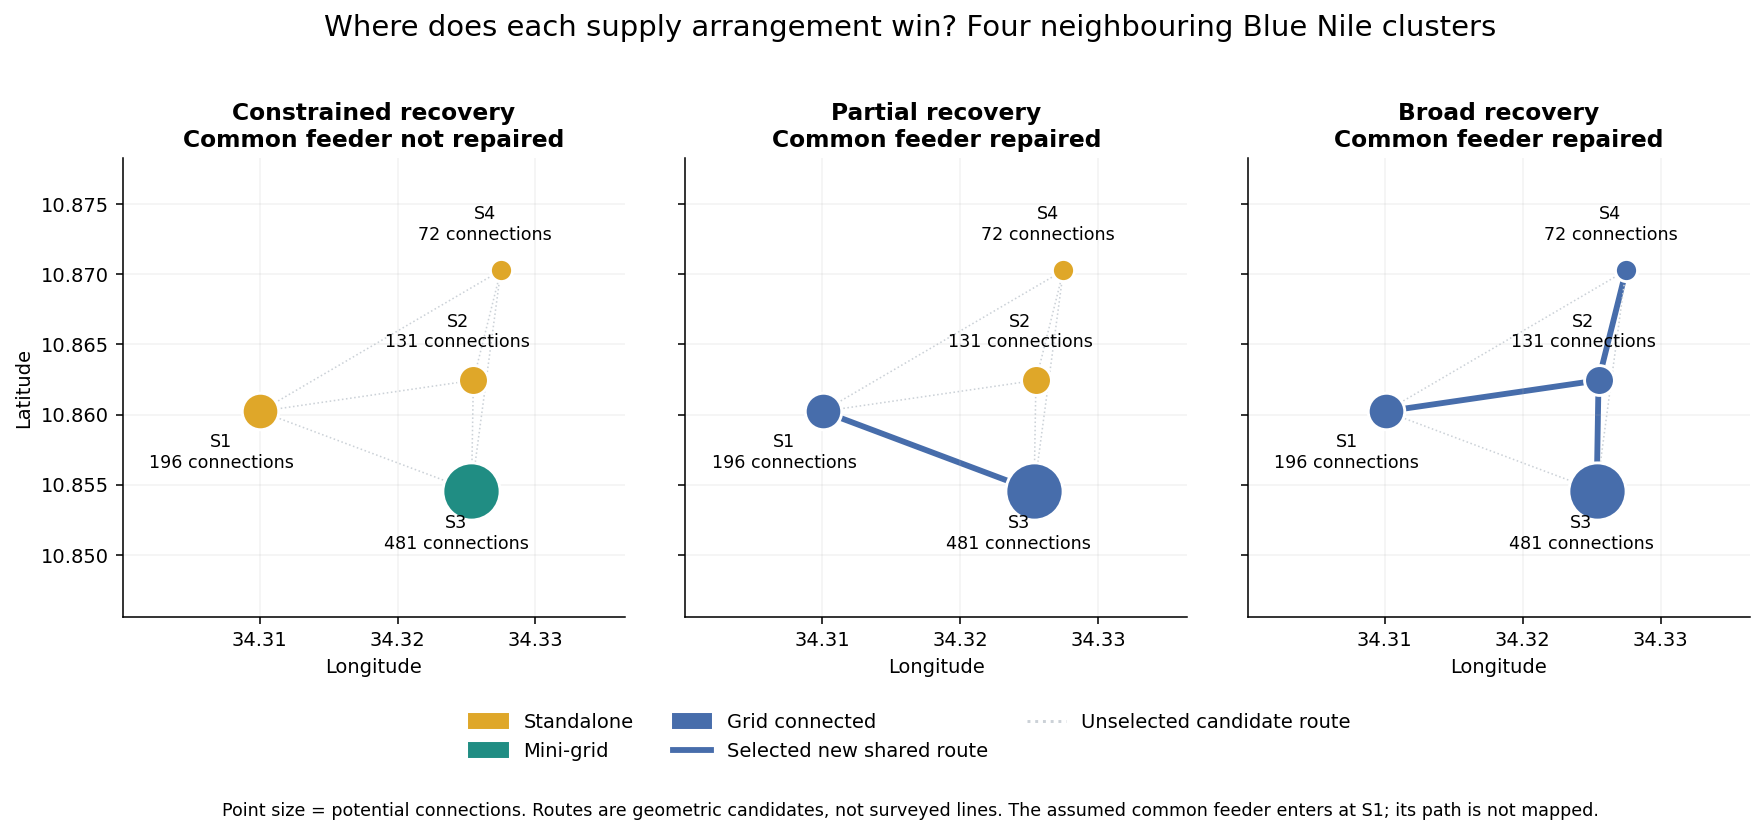

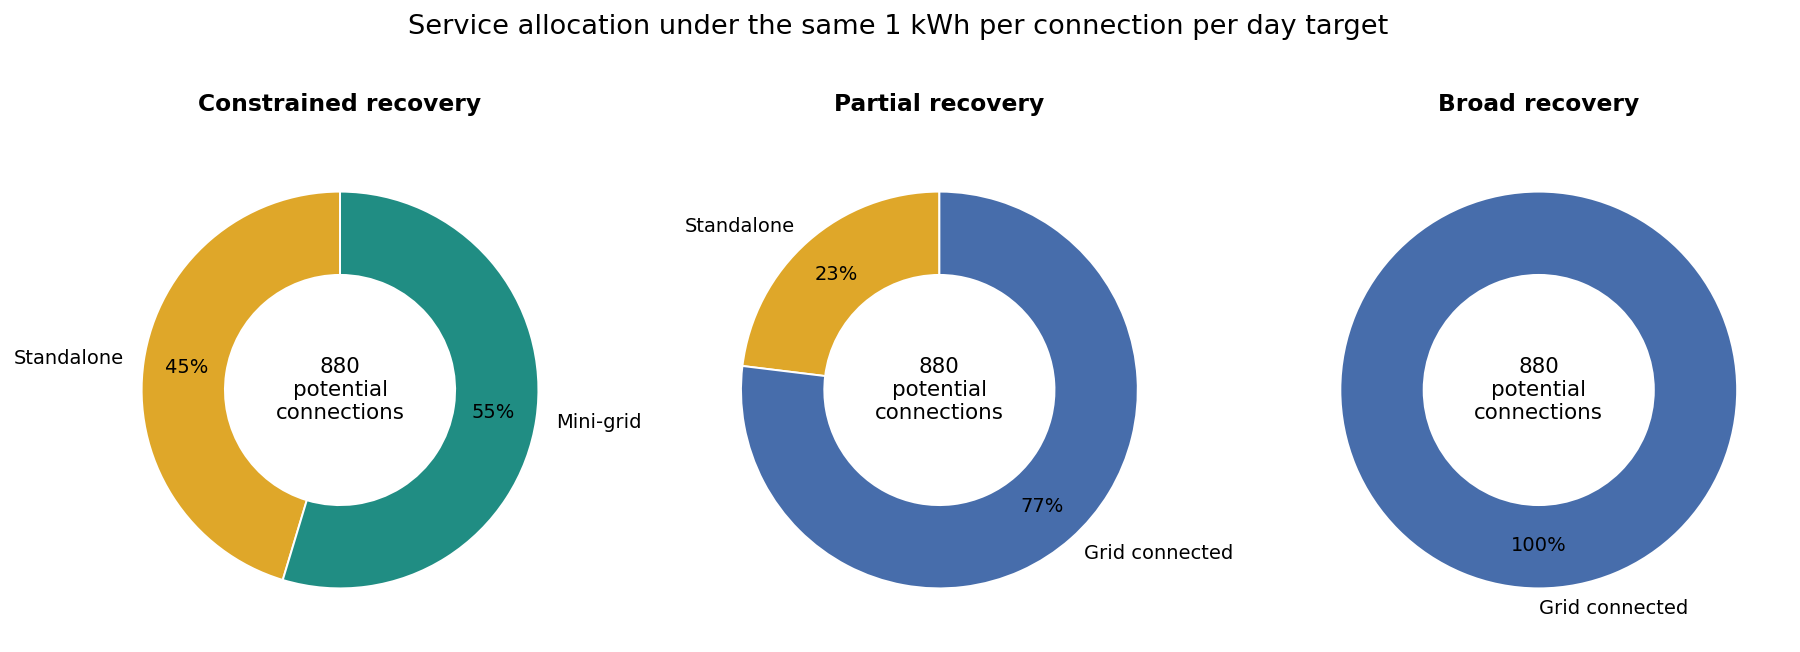

,,scenario,constrained,partial,broad
site_id,source_name,connections,,,
S1,Al Kurumuk,196,standalone,grid,grid
S2,Location #10663,131,standalone,standalone,grid
S3,Kubbaka,481,mini_grid,grid,grid
S4,Radona,72,standalone,standalone,grid


In [32]:
display(Image(filename=str(RECOVERY_OUT/'recovery_choices_map.png')))
display(Image(filename=str(RECOVERY_OUT/'recovery_connections.png')))
display(recovery_choices.pivot(index=['site_id','source_name','connections'],columns='scenario',values='choice').reindex(columns=recovery.CONFIG['scenario_order']))

**Reading the saved results:** With no repair budget, Kubbaka (S3) uses a mini-grid and the other clusters use standalone systems. Partial recovery makes a shared grid connection to Al Kurumuk (S1) and Kubbaka (S3) economical; the two smaller clusters remain standalone. Broad recovery connects all four through S1–S2, S2–S3 and S2–S4, and selects both candidate repairs.

These are separate stationary plans, not a recommendation to install and then discard the off-grid systems in that order. A transition study must explicitly carry existing investments between periods. Under the broad case's assumed continuous upstream availability, the optimizer chooses about 50.9 kWp of hub PV and no settlement storage or diesel. That result depends on the stated availability; it does not establish real-world outage resilience.

### 10.3 Investment, shared infrastructure and operation

The mapped edges are straight-line ×1.3 candidate new routes between source coordinates. All six pairwise candidates are offered; the solver pays a route's fixed lifecycle cost once, regardless of how many downstream settlements use it. The assumed common feeder reaches S1; its actual geographic path is unknown and is not drawn as if surveyed.

The allocation pies show **potential connections**, not population, energy shares or state-wide coverage. Equipment capacities are separated into power (kW/kWp) and battery energy (kWh). Total costs include the separate existing-load block; they must not be divided solely by settlement energy and labelled a settlement LCOE.

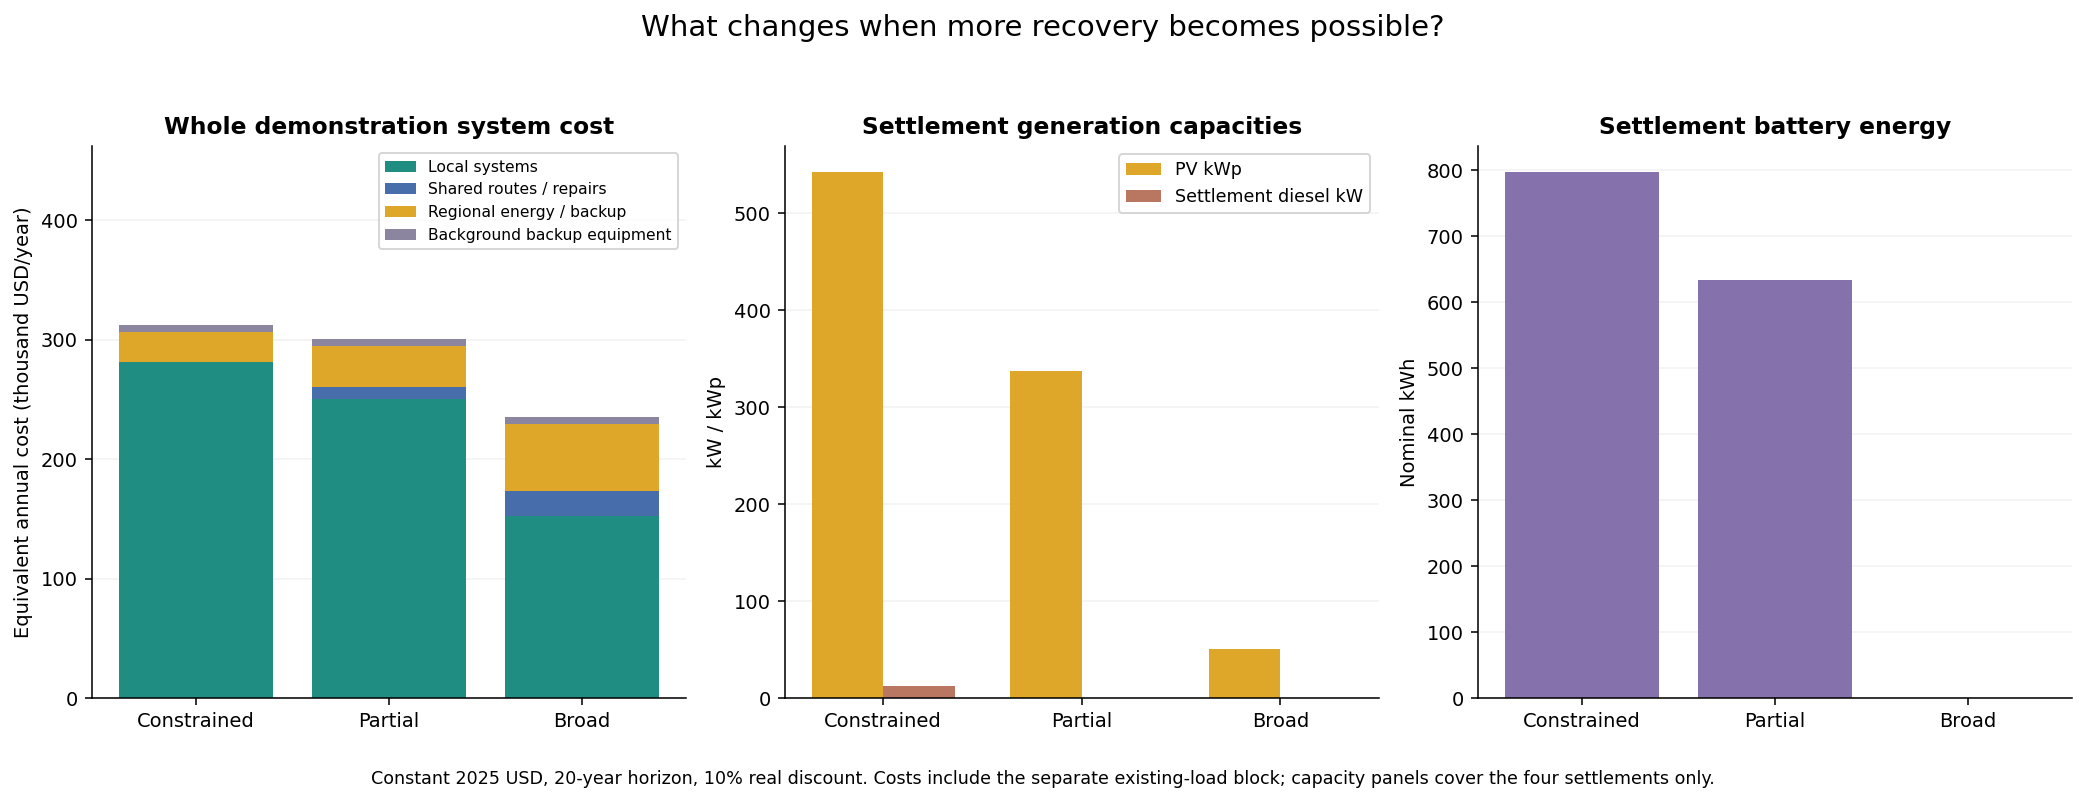

,scenario,equivalent_annual_cost_USD,lifecycle_NPC_USD,initial_investment_USD,repair_spend_USD,new_feeder_km,repaired_common_feeder_km,restored_upstream_MW
0,constrained,"312,317.84","2,658,937.86","1,676,428.65",0.00,0.00,0.00,0.00
1,partial,"300,650.31","2,559,605.53","1,623,107.86","16,648.63",2.32,2.00,-0.00
2,broad,"235,151.89","2,001,980.58","1,156,896.29","40,408.63",4.52,2.00,0.15


,scenario,site_id,choice,pv_kWp,battery_nominal_kWh,converter_AC_kW,diesel_kW
0,constrained,S1,standalone,197.10,179.74,28.84,0.00
1,constrained,S2,standalone,131.73,120.13,19.27,0.00
2,constrained,S3,mini_grid,141.51,431.94,64.53,12.39
3,constrained,S4,standalone,72.40,66.03,10.59,0.00
4,partial,S1,grid,133.61,447.98,112.28,-0.00
5,partial,S2,standalone,131.73,120.13,19.27,0.00
6,partial,S3,grid,-0.00,-0.00,-0.00,-0.00
7,partial,S4,standalone,72.40,66.03,10.59,0.00
8,broad,S1,grid,50.90,-0.00,-0.00,-0.00
9,broad,S2,grid,-0.00,-0.00,-0.00,-0.00


**Constrained recovery — selected repairs/routes**

,repair,value
0,feeder,0.0
1,upstream,0.0


,edge,value
0,S1_S2,0.0
1,S1_S3,0.0
2,S1_S4,0.0
3,S2_S3,0.0
4,S2_S4,0.0
5,S3_S4,0.0


...

,repair,value
0,feeder,1.0
1,upstream,-0.0


,edge,value
0,S1_S2,-0.0
1,S1_S3,1.0
2,S1_S4,-0.0
3,S2_S3,-0.0
4,S2_S4,-0.0
5,S3_S4,-0.0


**Broad recovery — selected repairs/routes**

,repair,value
0,feeder,1.0
1,upstream,1.0


,edge,value
0,S1_S2,1.0
1,S1_S3,0.0
2,S1_S4,0.0
3,S2_S3,1.0
4,S2_S4,1.0
5,S3_S4,0.0


In [33]:
display(Image(filename=str(RECOVERY_OUT/'recovery_costs_capacities.png')))
display(recovery_summary[['scenario','equivalent_annual_cost_USD','lifecycle_NPC_USD','initial_investment_USD','repair_spend_USD','new_feeder_km','repaired_common_feeder_km','restored_upstream_MW']].style.format(precision=2,thousands=','))
display(recovery_choices[['scenario','site_id','choice','pv_kWp','battery_nominal_kWh','converter_AC_kW','diesel_kW']].style.format(precision=2))
for sc in recovery.CONFIG['scenario_order']:
    display(Markdown('**'+recovery.CONFIG['scenarios'][sc]['label']+' — selected repairs/routes**'))
    repairs=pd.read_csv(RECOVERY_OUT/sc/'repair_asset.csv')
    routes=pd.read_csv(RECOVERY_OUT/sc/'route_build.csv')
    display(repairs);display(routes)

### 10.4 What has been checked and what this answers

Independent checks reload the exported PyPSA networks and custom decisions, then reconstruct all bus balances, full-year battery chronology, capacity limits, option activation, equal service, diesel limits, connected grid paths, repair budgets, and lifecycle costs. They also check the no-repair-budget limiting case and the nested recovery feasible sets. The solver's achieved mixed-integer optimality gap is reported; the target tolerance is 0.01%. Numerical validation is not field validation.

The answer is now **a jointly optimized local recovery plan conditional on a declared candidate network and a single grid-side backup hub**. The preferred choices may change with recovery because settlements can share routes and draw on restored supply. The model is not forced to select all three technologies. A technology winning nowhere in a case is a valid result.

The next implementation step is geographic scaling: repeat and connect regional candidate graphs, replace the assumed feeder with source-traced infrastructure where possible, and couple aggregate supply to the national generation/transmission model. Measured demand is not a prerequisite for extending the conditional model. National allocation, observed damage-based rehabilitation, engineering reliability and investment sequencing remain outside the present result.

**Reproduce:** run `python research/system_costs/recovery_model.py` and `python research/system_costs/check_recovery.py`, or Run All in this notebook. Cached results are verified against input and output hashes. `--force` re-solves. Model files (`network.nc`) omit custom constraints; rerun the Python builder to recreate them. Separate decision CSVs retain all service, route, repair and connectivity variables. See [method and scope](../../docs/RECOVERY_MODEL.md).

In [34]:
display(pd.read_csv(RECOVERY_OUT/'independent_checks.csv'))
display(pd.DataFrame([recovery_validation]))
display(Markdown('**Sample-only finding:** '+ '; '.join(recovery.CONFIG['scenarios'][sc]['label']+': '+', '.join(f'{count} connections via {mode.replace("_"," ")}' for mode,count in recovery_findings['allocation'][sc].items()) for sc in recovery.CONFIG['scenario_order'])+'.'))

,scenario,hours,max_bus_balance_error_MW,max_storage_error_MWh,cost_reconstruction_error_USD,repair_spend_USD,connected_grid_sites,mip_relative_gap
0,constrained,8760,3.469447e-18,0.000000e+00,0.0,0.000,0,0.0
1,partial,8760,1.651457e-15,2.914335e-16,0.0,16648.632,2,0.0
2,broad,8760,5.551115e-17,0.000000e+00,0.0,40408.632,4,0.0


,passed,scenarios,settlements,potential_connections,hours_per_scenario,settlement_service_hours,offgrid_designs_checked,discrete_choices_checked,shared_routes_costed_once,repair_budgets_checked,lifecycle_and_hourly_balances_checked,zero_budget_limiting_case_checked,nested_recovery_cost_monotonicity_checked,national_model,field_validated,measured_damage_used
0,True,3,4,880,8760,105120,8,True,True,True,True,True,True,False,False,False


**Sample-only finding:** Constrained recovery: 481 connections via mini grid, 399 connections via standalone; Partial recovery: 677 connections via grid, 203 connections via standalone; Broad recovery: 880 connections via grid.

<a id="national-coupling"></a>
## 11. Eight settlements, shared routes and national supply

**Current study — start here.** We now connect the local electrification choices to the 19-node Sudan electricity model. Eight neighbouring Blue Nile clusters represent **978 potential connections**, with all 8,760 hours retained. The national model supplies the local plan's actual hourly imports and their additional dispatch cost. This is a nationally supplied regional access plan, **not yet a national allocation of access technologies**.

The research question remains: **Where, and under what recovery conditions, are grid rehabilitation, mini-grids or standalone systems the least-cost way to provide reliable electricity in Sudan?** This step replaces the assumed bulk price with national dispatch, expands the local candidate graph, and checks the coupled cost bounds. Earlier sections retain the supporting evidence and previous models.

In [35]:
import coupled_model as coupled
from check_coupled import evaluate as check_coupled
from coupled_analysis import make as coupled_figures
coupled_summary=coupled.run()
coupled_validation=check_coupled()
coupled_findings=coupled_figures()
COUPLED_OUT=coupled.OUT
coupled_sites,coupled_routes=coupled.setup()
coupled_choices=pd.read_csv(COUPLED_OUT/'settlement_choices.csv')
display(Markdown('**Completed:** three nationally coupled recovery cases, 16 independent off-grid designs, full-year service and national dispatch checks. The declared candidate graph has '+str(len(coupled_routes))+' edges.'))

{"passed": true, "clusters": 8, "potential_connections": 978, "scenarios": 3, "hours": 8760, "national_buses": 19, "national_corridors": 13, "offgrid_designs": 16, "all_hourly_service_met": true, "national_shortage_allowed": false, "coupling_bounds_checked": true, "national_allocation": false, "field_validated": false}


**Completed:** three nationally coupled recovery cases, 16 independent off-grid designs, full-year service and national dispatch checks. The declared candidate graph has 11 edges.

### 11.1 What the coupling changes

| Previous regional demonstration | This coupled study |
|---|---|
| Four clusters, 880 potential connections | Eight clusters, 978 potential connections; selected before solving |
| Assumed 0.15 USD/kWh bulk electricity | Incremental dispatch cost from the national model; no extra bulk-price charge |
| Assumed 30 kW background block | Existing national consumption and accounting losses; no duplicate synthetic background |
| Optional hypothetical 150 kW upstream repair | Existing national generation and corridors; no invented national restoration asset |
| Local feasibility and MIP gap | Local feasibility, national re-dispatch and a coupled upper/lower cost bound |

The **national fleet stays at the 2022 reference in all cases**. The scenarios change only local feeder repair budgets and outage schedules. They are not measured national war-damage cases. National generation limits, schematic transfers and annual hydro budgets are active; shortages are prohibited in these coupled solves.

The eight clusters are the nearest eligible neighbours of the previous Al Kurumuk anchor (20–500 potential connections, positive area, no detected nightlight). They share the anchor's existing 2022 weather series, with a maximum separation of 9.601 km. Their names may repeat; geohashes identify separate source clusters. Two-nearest-neighbour edges plus a geometric minimum spanning tree form the candidate graph. All route lengths are unsurveyed distance proxies.

The assigned **Roseires regional bus is an aggregate supply boundary**, not a surveyed connection from Roseires city. The 2.002 km repairable common feeder remains a hypothetical atlas-proximity proxy. Only S1 offers grid-side generation/storage. This candidate architecture does not yet model voltage, protection, detailed transformer loading, contingencies or shared mini-grids across multiple clusters.

,site_id,geohash,village_name,num_connections,distance_to_anchor_km
0,S1,scbmu9pc3u,Al Kurumuk,196,0.000000
1,S2,scbmv17n61,Location #10663,131,1.706009
2,S3,scbmv04bqy,Kubbaka,481,1.787712
3,S4,scbmv4uebe,Radona,72,2.208589
4,S5,scbmtj02uk,Al Kurumuk,34,2.769435
5,S6,scbmtjnn4g,Gaissan,21,3.182118
6,S7,scbqjpuq0f,Location #32433,20,9.288916
7,S8,scbqm24701,Al Kurumuk,23,9.600876


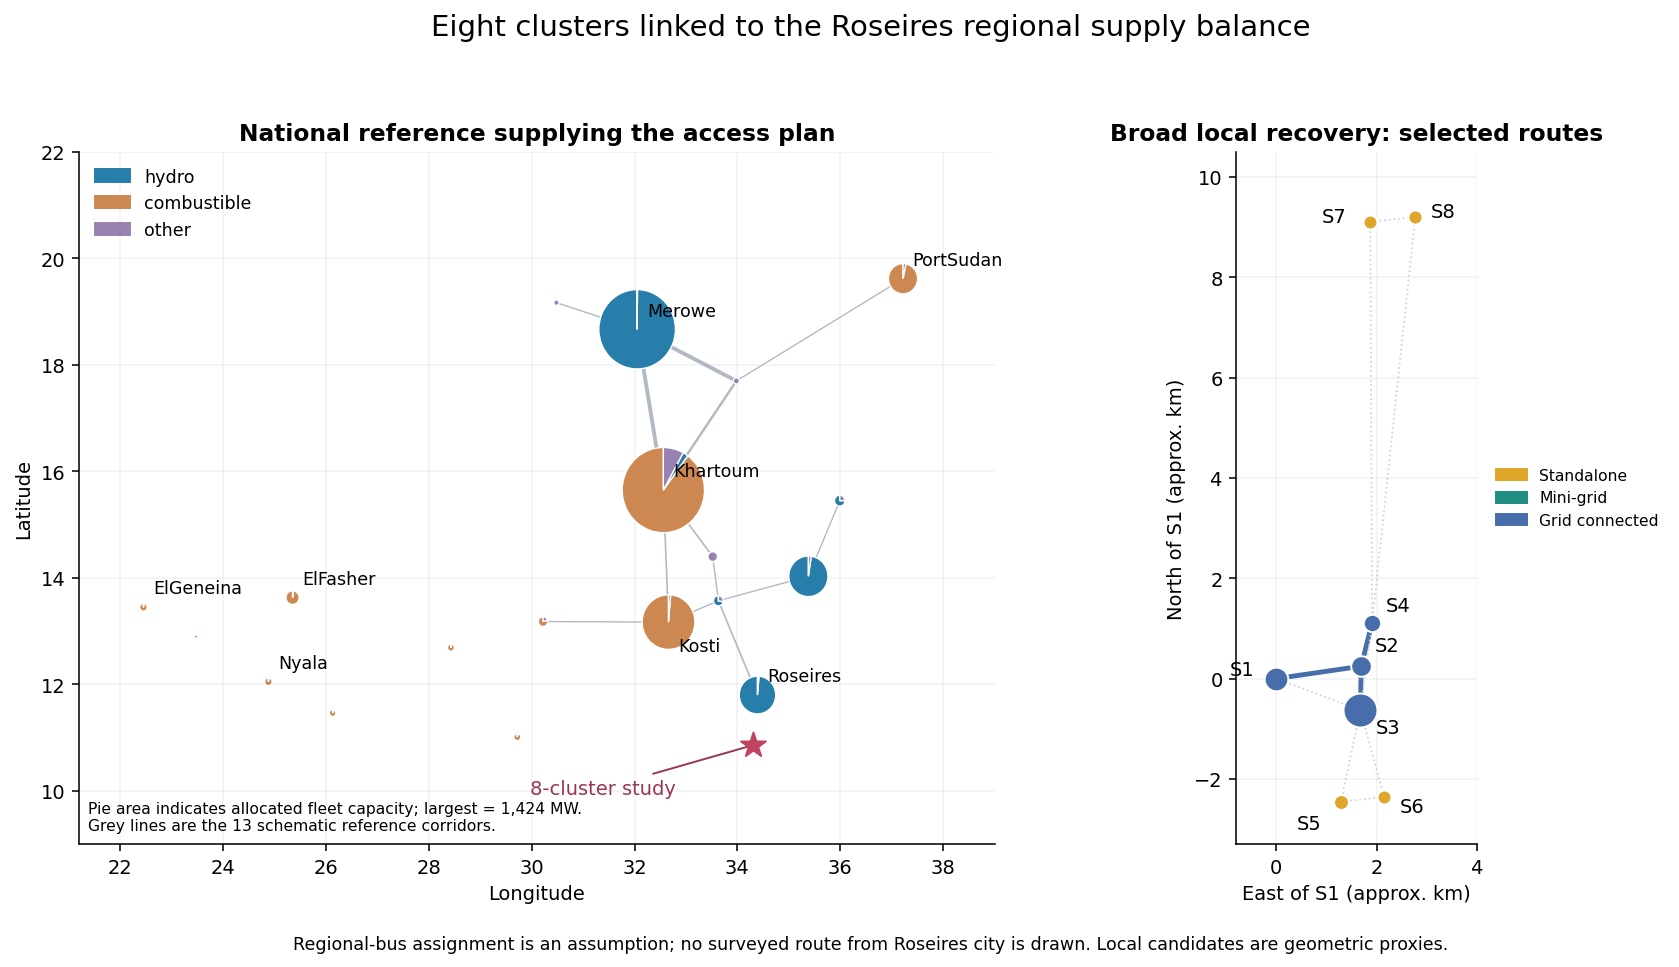

,scenario,label,repair_budget_USD,outage_local_hours
0,constrained,Constrained local recovery,0,"[18, 19, 20, 21, 22, 23]"
1,partial,Partial local recovery,30000,"[19, 20, 21]"
2,broad,Broad local recovery,100000,[]


In [36]:
display(coupled_sites[['site_id','geohash','village_name','num_connections','distance_to_anchor_km']])
display(Image(filename=str(COUPLED_OUT/'national_coupling_map.png')))
display(pd.DataFrame([dict(scenario=k,**v) for k,v in coupled.CONFIG['scenarios'].items()]))

### 11.2 Equal service, an aligned clock and no double counting

Every potential connection receives the same assumed **1 kWh/day** hourly service. Standalone and mini-grid alternatives are independently sized for all 8,760 hours; the shared grid plan must deliver the same target. The selected clusters are assumed to be **additional access demand outside the existing national total**. This is a boundary assumption, not verified evidence of their present access status.

The original national demand profile used Sudan local time; weather and local demand use UTC. A two-hour periodic shift aligns the national synthetic year to UTC while preserving annual energy. The last two UTC hours wrap to the first two local-year hours. Annual hydro energy constraints are explicitly recreated because NetCDF does not retain custom constraints.

Costs are **incremental access costs**: local systems + routes/repairs + the increase in national dispatch cost relative to its no-access baseline. The existing national operating bill and sunk national capital are not assigned to these settlements. Local costs use the same 20-year, 10% real, constant-2025-USD ledger with taxes excluded. The old national variable costs are illustrative values assigned this scenario price basis; they are not newly verified wartime prices.

These results are stationary alternatives, not sequential investments. They cannot be directly compared with section 10's total costs because coverage, background demand and upstream representation differ.

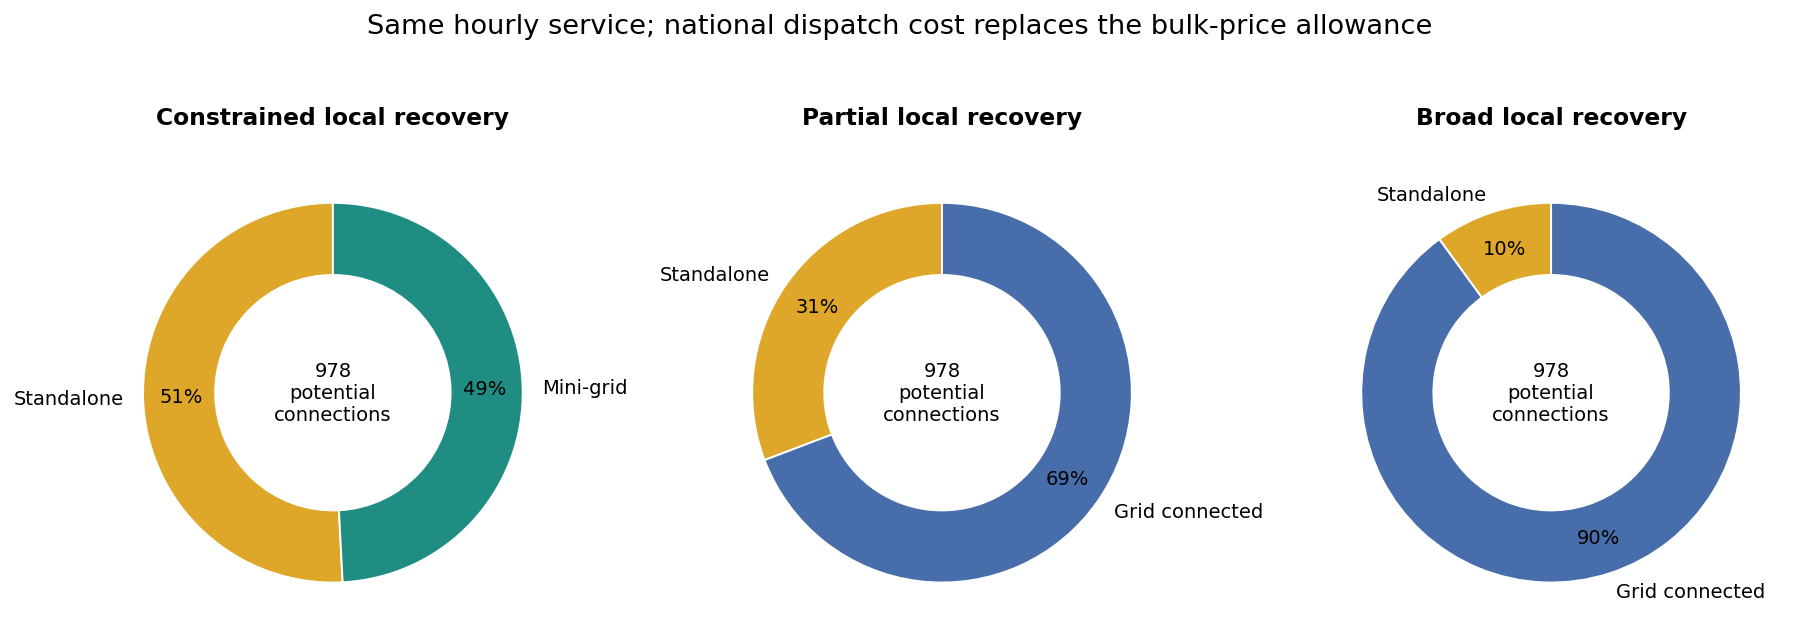

,,scenario,constrained,partial,broad
site_id,source_name,connections,,,
S1,Al Kurumuk,196,standalone,grid,grid
S2,Location #10663,131,standalone,standalone,grid
S3,Kubbaka,481,mini_grid,grid,grid
S4,Radona,72,standalone,standalone,grid
S5,Al Kurumuk,34,standalone,standalone,standalone
S6,Gaissan,21,standalone,standalone,standalone
S7,Location #32433,20,standalone,standalone,standalone
S8,Al Kurumuk,23,standalone,standalone,standalone


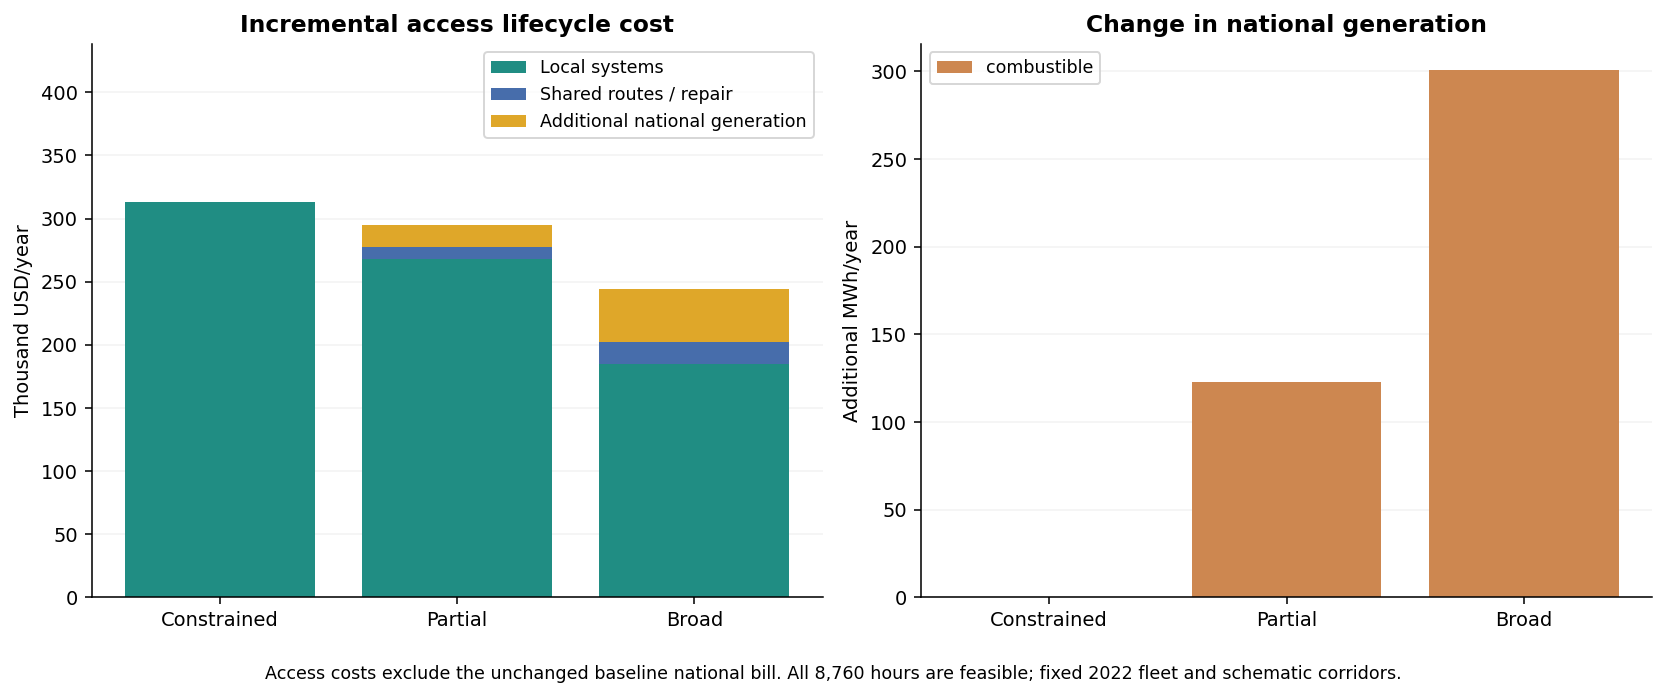

,scenario,equivalent_annual_access_cost_USD,lifecycle_access_NPC_USD,initial_local_investment_USD,incremental_national_dispatch_cost_USD,repair_spend_USD,national_import_MWh,new_route_km
0,constrained,"313,260.77","2,666,965.52","1,840,393.55",0.00,0.00,0.00,0.00
1,partial,"295,001.95","2,511,517.91","1,707,645.50","17,176.14","16,648.63",122.69,2.32
2,broad,"244,037.97","2,077,632.84","1,295,981.48","42,107.09","16,648.63",300.77,4.52


**Local equipment totals:** power is in kW/kWp; battery energy is nominal kWh. These totals exclude the existing national fleet.

,pv_kWp,diesel_kW,converter_AC_kW,battery_nominal_kWh
scenario,,,,
constrained,641.30,12.39,137.65,887.71
partial,413.41,0.00,156.56,617.66
broad,148.21,0.00,14.42,89.87


,combustible,hydro,imports,other
scenario,,,,
constrained,0.000,0.000,0.000,0.000
partial,122.687,0.000,0.000,0.000
broad,300.765,0.001,0.000,0.000


**Scale:** the sample delivers 356.97 MWh/year, about 0.0027% of reference national consumer electricity. It tests a working coupling mechanism; its size is too small to establish country-wide congestion or investment needs.

**What this run teaches us:** broad local recovery reduces the modelled annual access cost by 22.1% relative to constrained recovery, while delivering the same service. It selects grid service for 880 potential connections. The result reflects the combined repair-budget and outage conditions; it does not isolate the effect of budget alone. The settlement table above shows which locations retain off-grid service.

In [37]:
display(Image(filename=str(COUPLED_OUT/'coupled_connections.png')))
display(coupled_choices.pivot(index=['site_id','source_name','connections'],columns='scenario',values='choice').reindex(columns=coupled.CONFIG['scenario_order']))
display(Image(filename=str(COUPLED_OUT/'coupled_costs_supply.png')))
display(coupled_summary[['scenario','equivalent_annual_access_cost_USD','lifecycle_access_NPC_USD','initial_local_investment_USD','incremental_national_dispatch_cost_USD','repair_spend_USD','national_import_MWh','new_route_km']].style.format(precision=2,thousands=','))
capacity_totals=coupled_choices.groupby('scenario')[['pv_kWp','diesel_kW','converter_AC_kW','battery_nominal_kWh']].sum().reindex(coupled.CONFIG['scenario_order'])
display(Markdown('**Local equipment totals:** power is in kW/kWp; battery energy is nominal kWh. These totals exclude the existing national fleet.'))
display(capacity_totals.style.format(precision=2))
display(pd.read_csv(COUPLED_OUT/'national_generation_changes_MWh.csv').set_index('scenario').style.format(precision=3))
national_facts=pd.read_csv(coupled.DATA/'national_2022.csv',index_col=0).value
sample_share=100*coupled_summary.delivered_MWh.iloc[0]/(national_facts.consumption*1000)
display(Markdown(f'**Scale:** the sample delivers {coupled_summary.delivered_MWh.iloc[0]:,.2f} MWh/year, about {sample_share:.4f}% of reference national consumer electricity. It tests a working coupling mechanism; its size is too small to establish country-wide congestion or investment needs.'))
by_recovery=coupled_summary.set_index('scenario')
cost_reduction=100*(1-by_recovery.at['broad','equivalent_annual_access_cost_USD']/by_recovery.at['constrained','equivalent_annual_access_cost_USD'])
display(Markdown(f"**What this run teaches us:** broad local recovery reduces the modelled annual access cost by {cost_reduction:.1f}% relative to constrained recovery, while delivering the same service. It selects grid service for {by_recovery.at['broad','grid_connections']:.0f} potential connections. The result reflects the combined repair-budget and outage conditions; it does not isolate the effect of budget alone. The settlement table above shows which locations retain off-grid service."))

### 11.3 How the national and local models agree

The national dispatch problem gives hourly marginal costs at Roseires. These create a **supporting lower bound** on the cost of supplying any candidate import profile. The local mixed-integer model chooses its routes, primary service arrangements, repair and hub equipment against that bound. We then re-dispatch the full national network with those imports to obtain a feasible upper bound. If the bounds are too far apart, the national solution supplies another cost cut and the process repeats.

This is more than applying a fixed grid tariff: the completed plan has been supplied by an actual national re-dispatch, and the gap bounds how much a different feasible plan could improve the objective within the declared model. The lower bound uses the master's solver dual bound, including its integer gap. Completion requires the larger of **1 USD/year or 0.01%** tolerance. A negligible charging tie-break penalty is tracked separately and removed from reported resource costs.

This certificate covers the restricted graph, single-hub architecture, fixed national fleet and prescribed service. It is not proof of unrestricted national investment optimality. Numerical adequacy is also not field reliability: no uncertain outage draws or electrical protection/voltage study have been conducted.

In [38]:
display(coupled_summary[['scenario','iterations','lower_bound_USD','feasible_upper_bound_USD','certified_absolute_gap_USD','certified_relative_gap','numerical_charge_penalty_USD']].style.format(precision=6))
display(pd.read_csv(COUPLED_OUT/'independent_checks.csv'))
display(pd.DataFrame([coupled_validation]))
numeric_reversal=(coupled_summary.lower_bound_USD-coupled_summary.feasible_upper_bound_USD).clip(lower=0).max()
display(Markdown(f'**Numerical precision:** the largest lower/upper bound reversal is {numeric_reversal:.5f} USD/year, within the documented 0.50 USD/year numerical allowance. Displayed gaps are clipped at zero; this means agreement within solver tolerance, not exact arithmetic.'))
for sc in coupled.CONFIG['scenario_order']:
    display(Markdown('**'+sc.capitalize()+' — coupling convergence**'))
    display(pd.read_csv(COUPLED_OUT/sc/'convergence.csv').style.format(precision=4))
display(Markdown('**Sample-only allocation:** '+ '; '.join(sc.capitalize()+': '+', '.join(str(count)+' connections via '+mode.replace('_',' ') for mode,count in coupled_findings['allocation'][sc].items()) for sc in coupled.CONFIG['scenario_order'])+'.'))

,scenario,iterations,lower_bound_USD,feasible_upper_bound_USD,certified_absolute_gap_USD,certified_relative_gap,numerical_charge_penalty_USD
0,constrained,1,313260.769280,313260.769280,0,0,0.000000
1,partial,1,295002.057376,295002.056821,0,0,0.105007
2,broad,1,244038.171946,244037.974235,0,0,0.000000


,scenario,hours,settlements,local_balance_error_MW,national_balance_error_MW,storage_error_MWh,cost_reconstruction_error_USD,coupling_gap_USD
0,constrained,8760,8,0.000000e+00,2.858815e-08,0.000000e+00,1.641456e-08,0
1,partial,8760,8,4.111295e-16,2.854154e-08,9.454243e-17,1.554145e-08,0
2,broad,8760,8,1.975850e-15,4.547474e-13,0.000000e+00,-4.368485e-08,0


,passed,clusters,potential_connections,scenarios,hours,national_buses,national_corridors,offgrid_designs,all_hourly_service_met,national_shortage_allowed,coupling_bounds_checked,national_allocation,field_validated
0,True,8,978,3,8760,19,13,16,True,False,True,False,False


**Numerical precision:** the largest lower/upper bound reversal is 0.19771 USD/year, within the documented 0.50 USD/year numerical allowance. Displayed gaps are clipped at zero; this means agreement within solver tolerance, not exact arithmetic.

**Constrained — coupling convergence**

...

**Partial — coupling convergence**

,iteration,master_objective,master_lower_bound,national_delta_USD,national_estimate_USD,candidate_upper_bound,best_upper_bound,lower_bound,gap_USD,relative_gap
0,1,295002.0574,295002.0574,17176.1379,17176.1385,295002.0568,295002.0568,295002.0574,0,0.0000


**Broad — coupling convergence**

,iteration,master_objective,master_lower_bound,national_delta_USD,national_estimate_USD,candidate_upper_bound,best_upper_bound,lower_bound,gap_USD,relative_gap
0,1,244038.1719,244038.1719,42107.0910,42107.2887,244037.9742,244037.9742,244038.1719,0,0.0000


**Sample-only allocation:** Constrained: 481 connections via mini grid, 497 connections via standalone; Partial: 677 connections via grid, 301 connections via standalone; Broad: 880 connections via grid, 98 connections via standalone.

### 11.4 What is ready and what comes next

**Ready:** joint local route/service/repair decisions, local equipment sizing, national hourly supply feasibility, annual hydro limits, aligned clocks, incremental-cost accounting, verified cached outputs and a bounded coupling solution. All source rows, assumptions and limits are explicit.

**Next implementation:** add geographically distinct settlement neighbourhoods at several national buses so they compete for national generation and corridor capacity. Then introduce national asset rehabilitation/expansion and investment periods with asset carry-over. Neither national universal-access cost nor actual damaged-asset repair priorities can be inferred by multiplying this eight-cluster result.

Measured local demand can improve the service scenarios later; it does not block this conditional modelling workflow. The most consequential remaining evidence gaps are usable tie-ins/routes, access overlap, seasonal hydro behaviour, comparable installed prices and engineering reliability. We continue with the documented public proxies rather than treating these as reasons to stop.

[Detailed formulation, assumptions and reproduction](../../docs/NATIONAL_COUPLING.md). Run `python research/system_costs/coupled_model.py` and `python research/system_costs/check_coupled.py`, or Run All here. Hash-verified results are reused offline. Changing inputs invalidates the cache. Local NetCDF files do not retain custom constraints: use the builder for a fresh solve.